# Queensland road crashes | V5

This notebook follows the six CRISP-ML(Q) phases, with quality checks alongside the analysis. It combines crash-level exploration, spatial enrichment, year-and-police-region analysis, and an experimental crash severity classifier.

Run from top to bottom with the project’s `.venv` kernel. Keep the six original CSVs beside the notebook and the Queensland reference layers under `Public spatial data/`. The notebook regenerates the enriched data and reconciliation exports. Each code cell has an overview of its methods before it and a summary of the saved results after it. The three CSV exports carry V5 filenames. The release manifest identifies the source files, spatial layers and software used in this run.

Open [the Tableau workbook](Queensland%20Traffic%20V5.twbx) to explore the crash-level data with filters and maps and to review the fixed-period results, or [the interactive Esri maps](Queensland%20Traffic%20V5%20-%20Esri%20Maps.html) for the map layers. The workbook reads the tables this notebook writes to `Tableau data V5/`. After a re-run, `python build_tableau_workbook.py` repackages the workbook from those tables.

The kernel uses pandas, NumPy, SciPy, Matplotlib, Folium, scikit-learn, imbalanced-learn, mlxtend, Shapely, PyProj, pyshp, ijson, and PyArrow.

Process references are available in [Studer et al., CRISP-ML(Q)](https://www.mdpi.com/2504-4990/3/2/20) · [Google Cloud, MLOps lifecycle and automation](https://docs.cloud.google.com/architecture/mlops-continuous-delivery-and-automation-pipelines-in-machine-learning)

### Optional · Run in Google Colab

Skip this cell when running locally. To work in Colab, copy this notebook to Google Drive, keep the data in a Drive folder named `Traffic Data`, and uncomment the lines below before running anything else.

**In this cell.** Mount Google Drive, make `Traffic Data` the working directory so every relative path in the notebook resolves there, and install the packages Colab does not provide. The folder needs the six source CSVs and the `Public spatial data/` subfolder. Exports are written back to the same Drive folder.

In [ ]:
# --- Google Colab setup -------------------------------------------------------------------
# Uncomment every line below (select the lines, then Ctrl+/ or Cmd+/) and run this cell first.
# Leave it commented out when running locally.

# from google.colab import drive
# import os
#
# # Mount Google Drive. Colab asks for permission the first time.
# drive.mount('/content/drive')
#
# # The notebook reads and writes relative to the working directory, so point it at the data folder.
# # Change this path if "Traffic Data" is not at the top level of My Drive.
# COLAB_DATA_DIR = '/content/drive/MyDrive/Traffic Data'
# os.chdir(COLAB_DATA_DIR)
#
# # Fail early with a clear message if the folder is not laid out as the notebook expects.
# for needed in ['Road crash locations.csv', 'Public spatial data/roads.geojson.gz']:
#     assert os.path.exists(needed), f'Missing in {COLAB_DATA_DIR}: {needed}'
#
# # Install the packages the notebook uses. Most are already in Colab; pip skips those.
# %pip install -q folium imbalanced-learn mlxtend shapely pyproj pyshp ijson pyarrow
#
# # If a cell later fails on a pandas or scikit-learn difference, install the versions this
# # notebook was last run with instead, then restart the runtime (Runtime > Restart session)
# # and run this cell again:
# # %pip install -q pandas==3.1.1 numpy==2.5.5 scipy==1.18.1 matplotlib==3.11.2 scikit-learn==1.9.1 \
# #     imbalanced-learn==0.14.2 mlxtend==0.25.0 folium==1.0.0 shapely==2.2.0 pyproj==3.8.0 \
# #     pyshp==3.1.9 ijson==3.6.0 pyarrow==26.0.1
#
# # After the last cell has run, rebuild the Tableau workbook from the new exports with:
# # %pip install -q tableauhyperapi
# # !python build_tableau_workbook.py
#
# print('Working directory:', os.getcwd())

**What this achieved.** Nothing when left commented out. When uncommented in Colab, the notebook runs from the `Traffic Data` folder in Google Drive with the required packages installed.

## Phase 1 · Business and data understanding

The current analytical goal is to describe the circumstances and outcomes of recorded Queensland crashes and identify patterns worth testing further. The modelling experiment classifies injury severity using recorded crash and road conditions. Its operational user, prediction timing, decision, and acceptance thresholds are open.

The locations file supports crash-level analysis. For comparisons across all six files, the common unit is crash year and police region. Treat 2025 as partial wherever complete years are required.

Two recording changes shape what the data can support. Property-damage-only crashes are recorded to 2010 only, so the analysis uses injury crashes wherever a series or a share crosses that year. The overseas-licensed driver flag stops during the series and is not analysed. Phase 2 documents both.

### Load and profile the source data

**In this cell.** Load the six source CSVs with pandas, verify that the required local spatial files are present, and check that crash identifiers are unique. List missing values to guide the cleaning steps.

In [1]:
from pathlib import Path
from tempfile import NamedTemporaryFile

import numpy as np
import pandas as pd
from IPython.display import display

# Fixed seed and file locations used throughout the notebook.
SEED = 42
DATA_DIR = Path.cwd()
SOURCE = DATA_DIR / 'Road crash locations.csv'
EXPORT = DATA_DIR / 'Road crash locations - cleaned V5.csv'
CRASH_ID = 'Crash_Ref_Number'
COORDS = ['Crash_Latitude', 'Crash_Longitude']
SPATIAL_DIR = DATA_DIR / 'Public spatial data'

# The five grouped supplement files, keyed by a short name.
supplement_paths = {
    'Factors': DATA_DIR / 'Factors in road crashes.csv',
    'Casualties': DATA_DIR / 'Road casualties.csv',
    'Vehicles': DATA_DIR / 'Vehicle types.csv',
    'Demographics': DATA_DIR / 'Driver demographics.csv',
    'Restraints': DATA_DIR / 'Seatbelt restraints and helmet use.csv',
}
spatial_files = [
    'roads.geojson.gz', 'locality.geojson.gz', 'postal.geojson.gz', 'police.zip',
    'G-NAF Queensland 2026-08.parquet',
]
# Stop early with a clear message if any input file or spatial layer is missing.
required = [SOURCE, *supplement_paths.values(), *(SPATIAL_DIR / name for name in spatial_files)]
missing_inputs = [str(path.relative_to(DATA_DIR)) for path in required if not path.is_file()]
if missing_inputs:
    raise FileNotFoundError('Missing notebook inputs: ' + ', '.join(missing_inputs))

# `raw` is the crash-level source and is never modified. `datasets` holds all six files.
raw = pd.read_csv(SOURCE, low_memory=False)
datasets = {'Locations': raw} | {
    name: pd.read_csv(path, low_memory=False) for name, path in supplement_paths.items()
}
# The crash reference must identify exactly one row.
assert raw[CRASH_ID].notna().all() and raw[CRASH_ID].is_unique
print(f"{len(raw):,} crashes | {raw.shape[1]} fields | {raw['Crash_Year'].min()}–{raw['Crash_Year'].max()}")
display(raw.isna().sum().loc[lambda counts: counts.gt(0)].rename('Missing rows').to_frame())

415,407 crashes | 53 fields | 2001–2025


,Missing rows
Crash_Longitude,598
Crash_Latitude,598
Crash_Street,15
Crash_Street_Intersecting,234997
State_Road_Name,224003
Crash_Speed_Limit,5
Crash_Road_Horiz_Align,1
Crash_Road_Vert_Align,2
DCA_Key_Approach_Dir,8021


**What this achieved.** Loaded the six source tables and checked that the required files and spatial layers are available. The crash-level source contains 415,407 unique crash records from 2001–2025. The output lists the fields with missing values.

### Audit the six files and test merge keys

Test identifier coverage, matching row IDs, and repeated year-region groups. A crash can be identified in the locations file by `Crash_Ref_Number`. Supplemental files report grouped counts and require a common geographic and time unit for analysis.

**In this cell.** Test candidate merge keys by checking identifier coverage, duplicate year–region groups, and whether matching row IDs refer to the same crash year. Align the police-region column names for later aggregation.

In [2]:
# Map each locations row ID to its crash year, to test whether `_id` means the same thing in every file.
location_ids = raw.set_index('_id')['Crash_Year']
# Each file names its police-region column differently.
region_fields = {
    'Locations': 'Loc_Police_Region',
    'Factors': 'Crash_Police_Region',
    'Casualties': 'Crash_Police_Region',
    'Vehicles': 'Crash_Police_Region',
    'Demographics': 'Crash_Police_Region',
    'Restraints': 'Crash_PoliceRegion',
}
group_fields = ['Crash_Year', 'Police_Region']
# The same tables with one shared `Police_Region` column, used for all year-region work below.
regional_sources = {
    name: frame.rename(columns={region_fields[name]: 'Police_Region'})
    for name, frame in datasets.items()
}

# Only columns present in all six files could serve as a common key.
columns_in_every_file = sorted(set.intersection(*(set(frame.columns) for frame in datasets.values())))
print('Exact column names shared by all six files:', ', '.join(columns_in_every_file))
# For each file, record ID coverage, uniqueness, year agreement and repeated year-region groups.
key_audit_rows = []
for name, frame in regional_sources.items():
    file_ids = frame['_id'].dropna()
    matching = frame.loc[file_ids.index[file_ids.isin(location_ids.index)], ['_id', 'Crash_Year']]
    mismatches = matching['Crash_Year'].ne(matching['_id'].map(location_ids))
    key_audit_rows.append({
        'File': name,
        'Rows': len(frame),
        'Has Crash ID': 'Crash ID' in frame,
        'Has crash reference': CRASH_ID in frame,
        'Unique _id': frame['_id'].is_unique,
        '_id overlaps with locations': len(matching),
        'Overlapping _id with different year': int(mismatches.sum()),
        'Year-region groups': frame[group_fields].drop_duplicates().shape[0],
        'Repeated year-region rows': int(frame.duplicated(group_fields).sum()),
    })
display(pd.DataFrame(key_audit_rows).set_index('File'))

Exact column names shared by all six files: Crash_Year, _id


,Rows,Has Crash ID,Has crash reference,Unique _id,_id overlaps with locations,Overlapping _id with different year,Year-region groups,Repeated year-region rows
File,,,,,,,,
Locations,415407,False,True,True,415407,0,186,415221
Factors,5523,False,False,True,5523,5234,186,5337
Casualties,38893,False,False,True,38893,37463,184,38709
Vehicles,3764,False,False,True,3764,3573,186,3578
Demographics,22699,False,False,True,22699,22572,186,22513
Restraints,42787,False,False,True,42787,41399,184,42603


**What this achieved.** Tested record identifiers and year–region coverage. `Crash_Ref_Number` identifies a locations record. Shared row IDs disagree on crash year across files. Year and police region support comparisons after source-level aggregation.

## Phase 2 · Data preparation and quality assurance

Prepare the crash-level data, document uncertainty, and reconcile both individual and grouped counts. The exploration that follows checks what the prepared data can support before modelling.

### Estimate missing coordinate pairs

Use median observed coordinates from the most specific group with at least three donor crashes. For records with usable locality labels, try an intersection within a suburb, then a street, suburb, or local government area (LGA). All 598 records missing coordinates have both suburb and LGA coded as `Unknown` in this CSV.

For records without locality labels, try an exact intersection, a street and named state-road segment, or a street name across Queensland. A compact match requires all geocoded donors to agree on a single known suburb and LGA, with a bounding-box diagonal of at most 1 km. As a last resort, a coarse street estimate allows a diagonal of up to 3 km where all donors agree on the LGA. An inferred suburb is recorded only when all donors agree on the suburb. Intersections are matched irrespective of road order. Unknown and generic street names are excluded. Estimates retain the donor method, count, and inferred locality, and unresolved coordinates remain blank.

Compare V2-style suburb/LGA medians with the V3 hierarchy on 10,000 withheld observed locations. Also mask suburb and LGA on those same rows to test the street fallback in conditions closer to the actual missing records. Errors are measured only where each method produced an estimate. Actual errors for the missing records remain unknown.

**In this cell.** Estimate missing coordinates using median locations from matching intersections, streets, suburbs, or council areas. Withhold known locations, then compare geographic error and coverage across the matching rules using Haversine distance.

In [3]:
# Great-circle (Haversine) distance in kilometres between two sets of points.
def distance_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = (np.radians(value) for value in (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2
    a += np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


# Lower-case and trim labels, turning placeholders such as 'unknown' or 'unnamed' into missing values.
def normalized_label(values):
    values = values.str.strip().str.casefold()
    placeholders = values.isin(['', 'unknown', 'not stated', 'not applicable', 'no road name'])
    generic = values.str.match(r'^(unnamed|invalid street|un-named)', na=False)
    return values.mask(placeholders | generic)


# Short names for the location fields used as matching keys.
LGA = 'Loc_Local_Government_Area'
SUBURB = 'Loc_Suburb'
STREET = 'Crash_Street'
CROSS_STREET = 'Crash_Street_Intersecting'
STATE_ROAD = 'State_Road_Name'
YEAR = 'Crash_Year'
geography = raw[[LGA, SUBURB, STREET, CROSS_STREET, STATE_ROAD]].apply(normalized_label)
road, cross = geography[STREET], geography[CROSS_STREET]
# Store each intersection with its two roads in alphabetical order so that A/B and B/A match.
valid_intersection = (road.notna() & cross.notna() & road.ne(cross)).fillna(False)
swap_roads = road.gt(cross).fillna(False)
geography['Road A'] = road.where(~swap_roads, cross).where(valid_intersection)
geography['Road B'] = cross.where(~swap_roads, road).where(valid_intersection)

# Donor groups to try in order when locality labels are usable.
location_levels = [
    ('intersection median', [LGA, SUBURB, 'Road A', 'Road B']),
    ('street within suburb median', [LGA, SUBURB, STREET]),
    ('suburb median', [LGA, SUBURB]),
    ('LGA median', [LGA]),
]


# Fallback groups for records without locality labels, each with its own spread limit.
street_levels = [
    ('compact statewide intersection', ['Road A', 'Road B'], 1, True),
    ('compact street and state-road segment', [STREET, STATE_ROAD], 1, True),
    ('compact statewide street', [STREET], 1, True),
    ('coarse statewide street', [STREET], 3, False),
]
estimated_locality_columns = ['Estimated_Suburb', 'Estimated_Local_Government_Area']


# Estimate coordinates as the median of matching donor crashes, trying each level until one has enough donors.
def estimate_coordinates(donor_rows, target_rows, levels, minimum_donors, compact_levels=()):
    estimates = pd.DataFrame(index=target_rows, columns=COORDS, dtype=float)
    locality = pd.DataFrame(index=target_rows, columns=estimated_locality_columns, dtype='string')
    method = pd.Series('unresolved', index=target_rows, dtype='string')
    donor_count = pd.Series(0, index=target_rows, dtype='int64')
    donors = geography.loc[donor_rows].join(raw.loc[donor_rows, COORDS])
    donors[estimated_locality_columns] = raw.loc[donor_rows, [SUBURB, LGA]].to_numpy()
    donors['known_locality'] = donors[[SUBURB, LGA]].notna().all(axis=1)

    named_levels = [(label, keys, None, False) for label, keys in levels]
    for label, keys, max_spread, require_suburb in [*named_levels, *compact_levels]:
        remaining = method.index[method.eq('unresolved')]
        if not len(remaining):
            break
        groups = donors.groupby(keys)
        medians = groups[COORDS].median()
        medians['donor_count'] = groups.size()
        eligible = medians['donor_count'].ge(minimum_donors)

        if max_spread is not None:
            bounds = groups[COORDS].agg(['min', 'max'])
            spread = distance_km(
                bounds[(COORDS[0], 'min')], bounds[(COORDS[1], 'min')],
                bounds[(COORDS[0], 'max')], bounds[(COORDS[1], 'max')],
            )
            suburb_agrees = groups[SUBURB].nunique().eq(1)
            eligible &= groups[LGA].nunique().eq(1) & groups['known_locality'].all() & spread.le(max_spread)
            if require_suburb:
                eligible &= suburb_agrees
            medians = medians.join(groups[estimated_locality_columns].first())
            medians['Estimated_Suburb'] = medians['Estimated_Suburb'].where(suburb_agrees)

        matched = geography.loc[remaining, keys].join(medians.loc[eligible], on=keys).dropna(subset=COORDS)
        estimates.loc[matched.index, COORDS] = matched[COORDS]
        method.loc[matched.index] = label
        donor_count.loc[matched.index] = matched['donor_count'].astype(int)
        if max_spread is not None:
            locality.loc[matched.index, estimated_locality_columns] = matched[estimated_locality_columns]
    return estimates, method, donor_count, locality

# Withhold 10,000 known locations to measure the error of each matching rule.
observed = raw.index[raw[COORDS].notna().all(axis=1)]
targets = raw.index[raw[COORDS].isna().any(axis=1)]
holdout = raw.loc[observed].sample(n=min(10_000, len(observed)), random_state=SEED).index
validation_rows = []
for label, levels, minimum, fallback in [
    ('V2-style suburb/LGA', [('suburb median', [SUBURB]), ('LGA median', [LGA])], 1, []),
    ('V3 named-locality hierarchy', location_levels, 3, []),
    ('V3 street fallback, locality withheld', [], 3, street_levels),
]:
    predicted, methods, _, _ = estimate_coordinates(
        observed.difference(holdout), holdout, levels, minimum, fallback
    )
    matched = methods.index[methods.ne('unresolved')]
    errors = distance_km(
        raw.loc[matched, COORDS[0]], raw.loc[matched, COORDS[1]],
        predicted.loc[matched, COORDS[0]], predicted.loc[matched, COORDS[1]],
    )
    validation_rows.append({
        'Method': label, 'Test locations': len(holdout), 'Estimated': len(matched),
        'Median error (km)': errors.median(), '90th percentile error (km)': errors.quantile(.90),
    })
coordinate_validation = pd.DataFrame(validation_rows).set_index('Method')
display(coordinate_validation.round(3))
fallback_errors = pd.DataFrame({'Method': methods.loc[matched], 'Error (km)': errors})
display(fallback_errors.groupby('Method')['Error (km)'].agg(
    Estimated='size', Median='median', P90=lambda values: values.quantile(.90)
).round(3))

# `cleaned` starts as a copy of the source. Estimates fill blanks only and keep their method and donor count.
cleaned = raw.copy()
estimated, methods, donor_count, inferred_locality = estimate_coordinates(
    observed, targets, location_levels, 3, street_levels
)
for column in COORDS:
    cleaned[column] = raw[column].fillna(estimated[column])
cleaned['Coordinate_Method'] = pd.Series('observed', index=raw.index, dtype='string')
cleaned.loc[targets, 'Coordinate_Method'] = methods
cleaned['Coordinate_Donor_Count'] = pd.Series(pd.NA, index=raw.index, dtype='Int64')
cleaned.loc[targets, 'Coordinate_Donor_Count'] = donor_count.astype('Int64')
cleaned[estimated_locality_columns] = inferred_locality.reindex(raw.index)

display(cleaned['Coordinate_Method'].value_counts().rename('Crashes').to_frame())

,Test locations,Estimated,Median error (km),90th percentile error (km)
Method,,,,
V2-style suburb/LGA,10000,10000,0.866,2.909
V3 named-locality hierarchy,10000,10000,0.234,2.100
"V3 street fallback, locality withheld",10000,3690,0.011,0.476


,Estimated,Median,P90
Method,,,
coarse statewide street,832,0.333,1.109
compact statewide intersection,2395,0.006,0.022
compact statewide street,330,0.175,0.536
compact street and state-road segment,133,0.069,0.401


,Crashes
Coordinate_Method,
observed,414809
unresolved,515
coarse statewide street,60
compact statewide street,21
compact statewide intersection,2


**What this achieved.** Compared geographic donor rules on withheld coordinates and estimated an initial 83 coordinate pairs from observed crash evidence. The cleaned table records the method and number of supporting crashes.

### Infer other fields where local records agree

For speed limit, require at least two agreeing reports on the same street and in the same suburb and LGA, within 25 m and two crash years. For road alignment, require at least three agreeing reports at the exact same recorded coordinates on the same street and in the same locality. These are conservative rules for suggesting missing values. Estimates rely on agreement within this dataset.

Leave the other blanks in place. Intersecting street and state-road name can be inapplicable, and approach direction depends on the individual crash.

**In this cell.** Look for agreeing records on the same road to fill missing speed limits or road alignment. Apply distance and, where relevant, year limits, then record the source method and number of supporting records.

In [4]:
# Fill a missing road attribute only where nearby crashes on the same road agree on a single value.
def infer_road_attribute(column, method_name, minimum_donors, radius_km, year_window=None):
    method_column = f'{column}_Method'
    count_column = f'{column}_Donor_Count'
    cleaned[method_column] = pd.Series(
        np.where(raw[column].notna(), 'observed', 'unresolved'), index=raw.index, dtype='string'
    )
    cleaned[count_column] = pd.Series(pd.NA, index=raw.index, dtype='Int64')
    complete_coordinates = raw[COORDS].notna().all(axis=1)
    for index in raw.index[raw[column].isna() & complete_coordinates]:
        keys = [LGA, SUBURB, STREET]
        road_key = geography.loc[index, keys]
        if road_key.isna().any():
            continue
        same_road = geography[keys].eq(road_key).all(axis=1, skipna=False).fillna(False)
        eligible = same_road & complete_coordinates & raw[column].notna()
        if year_window is not None:
            eligible &= raw[YEAR].sub(raw.at[index, YEAR]).abs().le(year_window)
        donors = raw.loc[eligible, [*COORDS, column]]
        if radius_km == 0:
            donors = donors.loc[donors[COORDS].eq(raw.loc[index, COORDS]).all(axis=1)]
        else:
            distances = distance_km(
                raw.at[index, COORDS[0]], raw.at[index, COORDS[1]],
                donors[COORDS[0]], donors[COORDS[1]],
            )
            donors = donors.loc[distances.le(radius_km)]
        if len(donors) >= minimum_donors and donors[column].nunique() == 1:
            cleaned.at[index, column] = donors[column].iloc[0]
            cleaned.at[index, method_column] = method_name
            cleaned.at[index, count_column] = len(donors)


# Speed limit: two or more agreeing reports within 25 m and two crash years.
infer_road_attribute('Crash_Speed_Limit', 'same road within 25 m and 2 years', 2, .025, year_window=2)
# Alignment: three or more agreeing reports at exactly the same coordinates.
for feature in ['Crash_Road_Horiz_Align', 'Crash_Road_Vert_Align']:
    infer_road_attribute(feature, 'same road and recorded coordinates', 3, 0)

# Before-and-after count of missing values for every field that had gaps.
missing_audit = pd.DataFrame({
    'Missing before': raw.isna().sum(),
    'Missing after': cleaned[raw.columns].isna().sum(),
})
missing_audit['Values inferred'] = missing_audit['Missing before'] - missing_audit['Missing after']
display(missing_audit.loc[missing_audit['Missing before'].gt(0)])

,Missing before,Missing after,Values inferred
Crash_Longitude,598,515,83
Crash_Latitude,598,515,83
Crash_Street,15,15,0
Crash_Street_Intersecting,234997,234997,0
State_Road_Name,224003,224003,0
Crash_Speed_Limit,5,4,1
Crash_Road_Horiz_Align,1,1,0
Crash_Road_Vert_Align,2,1,1
DCA_Key_Approach_Dir,8021,8021,0


**What this achieved.** Inferred one speed-limit category and one vertical road-alignment value from agreeing local records. The method and donor counts are retained for review.

### Add public spatial matches and reconcile the remaining gaps

The first pass runs locally and uses Queensland Roads and Tracks to check recorded points with a blank or generic street name. It requires a named road within 35 m and a lead of at least 10 m over the next differently named road. For crashes still missing coordinates, an exact road name or alias could yield an estimate at one shared junction or the midpoint of a single connected named street up to 1.5 km long.

The second pass expands standard street abbreviations and normalizes punctuation. A junction estimate requires two different recorded street names, the recorded cross-intersection type, a single mapped ground-level junction with four approaches, and at least one corroborating crash with the same two streets within 75 m. A street estimate requires a compact road corridor with every mapped road vertex within 500 m of the estimate, at least three distinct G-NAF address sites associated with the road, and at least three observed crash locations associated with the named street. All known crash points for that street must agree with the candidate corridor. The audit records the candidate extent and the evidence used. Plausible candidates without enough historical support are listed as review coordinates and excluded from the crash maps and models.

The validation sample combines 5,000 located crashes whose primary street names overlap with the unresolved cases and additional records on rare matching streets. For cases where the first road pass found no estimate, the check compares second-pass estimates with the recorded points. Each evaluated crash is excluded from its own historical road evidence. The errors describe performance on this sample.

Queensland locality polygons provide suburb and council area. ABS 2021 Postal Areas provide an approximate area code. QPS polygons provide the police-region label from the October 2026 archive. The latter two remain in separate columns so analysts can choose whether to combine them with recorded crash-era fields. Values derived from estimated points inherit their location uncertainty. Recorded street, suburb, council, postcode, and police-region values remain the preferred source.

The public layers are [Queensland Roads and Tracks](https://queensland.opendatasoft.com/explore/assets/roads-and-tracks/), [Queensland locality boundaries](https://www.data.qld.gov.au/dataset/locality-boundaries-queensland), [ABS Postal Areas](https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs/edition-3-july-2021-june-2026/access-and-downloads/digital-boundary-files), and [QPS regions](https://www.data.qld.gov.au/dataset/qps-regions).

Council-name comparisons account for the Region/Regional suffix and the 2023 Moreton Bay reclassification. Both source labels are retained. [City of Moreton Bay](https://www.moretonbay.qld.gov.au/files/assets/public/v/3/services/annual-report/annual-report-2022-23/mbrc-annual-report-2022-23.pdf)

The August 2026 Queensland G-NAF extract adds nearby numbered-address references within 50 m of recorded crash points. Address matches use property or building geocodes and exclude low-confidence and secondary addresses. Locality and street must agree where known. Where the street remains unresolved, three distinct nearby address sites must agree on one street for G-NAF to report a candidate. Property references and their postcodes are stored separately from crash street names and recorded postcodes. [Geoscape G-NAF product description](https://docs.geoscape.com.au/projects/gnaf_desc/en/stable/appendix_d.html) · [GeoParquet source](https://github.com/minus34/gnaf-loader#option-4---geoparquet-files-in-s3)

The compressed Queensland layers and source manifest are in `Public spatial data/`. The following cells recompute the matches directly from the layers and the crash data prepared above.

#### Recover suburbs without assigning coordinates

For crashes still missing both coordinates and a suburb, look for an exact named road or street pair in the Queensland network. The road must map to one locality statewide, or all intersections of the two named roads must fall in the same locality. Require agreement from at least two recorded crashes or at least three G-NAF points. A conflicting recorded suburb blocks the estimate. The result appears in `Reconciled_Suburb`, with evidence in the `Suburb_Only_*` columns. Maps, coordinate estimates, and regional grouping still use their existing inputs.

#### Set up local spatial lookups

**In this cell.** Import the libraries used to read the spatial files and query nearby features. Set up conversions between latitude/longitude and projected coordinates for distance checks, and define street abbreviations used in matching.

In [5]:
from collections import defaultdict
from gzip import open as gzip_open
import re
from zipfile import ZipFile

import ijson
from pyproj import CRS, Transformer
from scipy.spatial import cKDTree
import shapefile
from shapely import STRtree, get_coordinates, get_parts, line_merge, transform, union_all
from shapely.geometry import Point, shape
from shapely.ops import nearest_points

# Project longitude/latitude (EPSG:4326) to a metre-based Queensland grid (EPSG:9473) and back.
FORWARD = Transformer.from_crs(4326, 9473, always_xy=True).transform
INVERSE = Transformer.from_crs(9473, 4326, always_xy=True).transform
ID = CRASH_ID
LAT, LON = 'Crash_Latitude', 'Crash_Longitude'
STREET, CROSS = 'Crash_Street', 'Crash_Street_Intersecting'
ROADWAY = 'Crash_Roadway_Feature'
GNAF_FILE = 'G-NAF Queensland 2026-08.parquet'

# Street-type abbreviations expanded before road names are compared.
ABBREVIATIONS = {
    'RD': 'ROAD', 'ST': 'STREET', 'AVE': 'AVENUE', 'AV': 'AVENUE', 'DR': 'DRIVE',
    'HWY': 'HIGHWAY', 'PDE': 'PARADE', 'CT': 'COURT', 'CL': 'CLOSE', 'LN': 'LANE',
    'CCT': 'CIRCUIT', 'CRES': 'CRESCENT', 'TCE': 'TERRACE', 'BLVD': 'BOULEVARD',
    'PL': 'PLACE', 'PKWY': 'PARKWAY', 'ESP': 'ESPLANADE', 'TRK': 'TRACK',
}

**What this achieved.** Set up coordinate transformations and street-name normalisation settings used by the local public-layer lookups.

#### Match road names, junctions, and corridors

**In this cell.** Define how to standardise street names and screen candidate intersections and road corridors. Check road geometry and, where relevant, corroborate a candidate with G-NAF address sites and observed crash locations.

In [6]:
# Return the accepted spellings of a recorded road name, or an empty set for blanks and placeholders.
def road_spellings(name):
    if pd.isna(name):
        return set()
    original = ' '.join(name.upper().strip().split())
    if original in {'', 'UNKNOWN', 'NOT STATED', 'NOT APPLICABLE', 'NO ROAD NAME'}:
        return set()
    if original.startswith(('UNNAMED', 'INVALID STREET', 'UN-NAMED')):
        return set()
    words = original.split()
    words[-1] = ABBREVIATIONS.get(words[-1], words[-1])
    return {original, ' '.join('CREEK' if word == 'CK' else word for word in words)}


# Reduce a road name to one comparable form: upper case, no punctuation, street type spelled out.
def canonical_street(value):
    if not road_spellings(value):
        return ''
    words = re.sub(r'[^A-Z0-9]+', ' ', str(value).upper().replace("'", '').replace('’', '')).split()
    if not words:
        return ''
    street_types = ABBREVIATIONS | {'CR': 'CRESCENT', 'LA': 'LANE', 'BVD': 'BOULEVARD', 'CIR': 'CIRCUIT'}
    suffix_index = -2 if len(words) > 2 and words[-1] in ('NORTH', 'SOUTH', 'EAST', 'WEST') else -1
    words[suffix_index] = street_types.get(words[suffix_index], words[suffix_index])
    return ' '.join('CREEK' if word == 'CK' else word for word in words)


# First pass: locate a crash from its recorded street names using the public road network.
def forward_location(row, catalogue):
    first, second = (road_spellings(row[column]) for column in (STREET, CROSS))
    if not first:
        return {'Forward_status': 'no usable recorded street name'}
    first_segments = [segment for name in first for segment in catalogue.get(name, [])]
    if not first_segments:
        return {'Forward_status': 'recorded street name absent from road catalogue'}
    second_segments = [segment for name in second for segment in catalogue.get(name, [])]
    if second:
        points = []
        segment_ids = set()
        cross_tree = STRtree([geometry for _, geometry in second_segments])
        for properties, line in first_segments:
            for idx in cross_tree.query(line):
                cross_properties, cross_line = second_segments[idx]
                if properties['ground_rel'] not in ('Ground', 'Unknown') or cross_properties['ground_rel'] not in ('Ground', 'Unknown'):
                    continue
                intersection = line.intersection(cross_line)
                if intersection.geom_type != 'Point' or intersection.is_empty:
                    continue
                if line.boundary.distance(intersection) <= 2 and cross_line.boundary.distance(intersection) <= 2:
                    points.append(intersection)
                    segment_ids.update((properties['segment_id'], cross_properties['segment_id']))
        if not points:
            return {'Forward_status': 'no shared road junction for the recorded street pair'}
        point = union_all(points).centroid
        if max(point.distance(p) for p in points) > 12.5:
            return {'Forward_status': 'multiple possible road junctions'}
        method = 'QLD road network shared junction'
    else:
        combined = line_merge(union_all([line for _, line in first_segments]))
        if combined.geom_type != 'LineString' or not 0 < combined.length <= 1500:
            return {'Forward_status': 'street name has multiple components or spans over 1.5 km'}
        point = combined.interpolate(.5, normalized=True)
        segment_ids = {properties['segment_id'] for properties, _ in first_segments}
        method = 'QLD road network short-street midpoint'
    lon, lat = INVERSE(point.x, point.y)
    return {'Forward_status': 'estimated', 'Public_longitude': lon, 'Public_latitude': lat,
            'Public_coordinate_basis': method, 'Public_road_segments': sorted(str(v) for v in segment_ids)}


# Collect G-NAF address points by street so that a road corridor can be corroborated by its addresses.
def second_pass_streets(path, accepted_names):
    import pyarrow.parquet as pq

    groups = defaultdict(set)
    columns = [
        'street_name', 'street_type', 'street_suffix', 'latitude', 'longitude',
        'geocode_type', 'number_first', 'confidence',
    ]
    for batch in pq.ParquetFile(path).iter_batches(columns=columns, batch_size=120_000):
        frame = batch.to_pandas()
        eligible = (
            frame[['latitude', 'longitude', 'street_name', 'number_first']].notna().all(axis=1)
            & frame['confidence'].gt(0)
            & frame['geocode_type'].fillna('').str.contains(r'CENTROID|FRONTAGE|ENTRANCE|ACCESS|BUILDING')
        )
        frame = frame.loc[eligible]
        labels = (frame['street_name'] + ' ' + frame['street_type'].fillna('') + ' '
                  + frame['street_suffix'].fillna('')).str.strip()
        canonical = labels.map({label: canonical_street(label) for label in labels.unique()})
        subset = frame.loc[canonical.isin(accepted_names)]
        x, y = FORWARD(subset['longitude'].to_numpy(), subset['latitude'].to_numpy())
        for name, east, north in zip(canonical.loc[subset.index], x, y):
            if np.isfinite(east) and np.isfinite(north):
                groups[name].add((east, north))
    return groups


# Check the directions in which road arms leave the junction, to confirm opposing approaches.
def has_opposing_approaches(nodes, junction):
    directions = []
    for _, geometry in nodes:
        for part in get_parts(geometry):
            for line in (part, part.reverse()):
                endpoint = line.interpolate(0)
                if endpoint.distance(junction) > 3 or line.length < 3:
                    continue
                away = line.interpolate(min(10, line.length))
                direction = np.array([away.x - endpoint.x, away.y - endpoint.y])
                norm = np.linalg.norm(direction)
                if norm:
                    directions.append(direction / norm)
    return any(first @ second <= -.5 for i, first in enumerate(directions) for second in directions[i + 1:])


# Look for a ground-level crossing point shared by two named roads.
def second_pass_junction(first_segments, second_segments):
    matches = []
    cross_tree = STRtree([line for _, line in second_segments])
    for props, line in first_segments:
        for idx in cross_tree.query(line):
            other, cross_line = second_segments[idx]
            grades = {props['ground_rel'], other['ground_rel']}
            if not grades <= {'Ground', 'Unknown'} or 'Ground' not in grades:
                continue
            intersection = line.intersection(cross_line)
            if (not intersection.is_empty and intersection.geom_type == 'Point'
                    and line.boundary.distance(intersection) <= 2
                    and cross_line.boundary.distance(intersection) <= 2):
                matches.append((intersection, props['segment_id'], other['segment_id']))
    if not matches:
        return None, [], None, 'no shared ground-level node for the recorded junction'
    point = union_all([item[0] for item in matches]).centroid
    radius = max(point.distance(item[0]) for item in matches)
    if radius > 3:
        return None, [], None, 'multiple geographically distinct junction candidates'
    if not all(has_opposing_approaches(segments, point) for segments in [first_segments, second_segments]):
        return None, [], None, 'mapped approaches do not confirm a cross intersection'
    segments = {segment_id for _, first, second in matches for segment_id in (first, second)}
    return point, segments, radius, 'mapped four-arm cross intersection'


# Second pass: propose a junction or compact street-corridor estimate, or return the reason for no estimate.
def second_pass_location(first, second, roadway, catalogue, addresses):
    if not first:
        return {'Second_pass_status': 'no usable primary street name'}
    first_segments = catalogue.get(first, [])
    if not first_segments:
        return {'Second_pass_status': 'normalized street absent from road network'}
    support = None
    if second:
        if first == second:
            return {'Second_pass_status': 'recorded street pair repeats the same name'}
        if roadway != 'Intersection - Cross':
            return {'Second_pass_status': 'recorded junction type does not establish a cross intersection'}
        point, segments, radius, basis = second_pass_junction(first_segments, catalogue.get(second, []))
        if point is None:
            return {'Second_pass_status': basis}
    else:
        merged = union_all([geometry for _, geometry in first_segments])
        xmin, ymin, xmax, ymax = merged.bounds
        if np.hypot(xmax - xmin, ymax - ymin) > 3000 or merged.buffer(30).geom_type != 'Polygon':
            return {'Second_pass_status': 'street spans over 3 km or has disconnected corridors'}
        sites = addresses.get(first, set())
        if len(sites) < 3 or any(merged.distance(Point(x, y)) > 120 for x, y in sites):
            return {'Second_pass_status': 'insufficient or conflicting G-NAF support for one corridor'}
        midpoint = Point((xmin + xmax) / 2, (ymin + ymax) / 2)
        point = nearest_points(midpoint, merged)[1]
        radius = float(np.linalg.norm(get_coordinates(merged) - (point.x, point.y), axis=1).max())
        if radius > 1500:
            return {'Second_pass_status': 'candidate road extends more than 1.5 km from the estimate'}
        segments = [props['segment_id'] for props, _ in first_segments]
        support = len(sites)
        basis = 'G-NAF corroborated road corridor'
    lon, lat = INVERSE(point.x, point.y)
    return {
        'Second_pass_status': 'estimated', 'Public_latitude': lat, 'Public_longitude': lon,
        'Public_coordinate_basis': basis, 'Public_road_segments': sorted({str(value) for value in segments}),
        'Second_pass_road_extent_m': round(radius, 1), 'Second_pass_address_sites': support,
    }


# Accept a second-pass estimate only when enough observed crashes on that road or junction agree with it.
def historical_corroboration(estimate, donors, excluded_id=None):
    if estimate.get('Second_pass_status') != 'estimated':
        return estimate
    donors = donors.loc[donors.index != excluded_id]
    corridor = estimate['Public_coordinate_basis'] == 'G-NAF corroborated road corridor'
    minimum = 3 if corridor else 1
    extent = estimate['Second_pass_road_extent_m']
    if corridor and extent > 500:
        reason = 'candidate corridor is too long for automatic estimation'
    elif len(donors) < minimum:
        reason = 'insufficient observed crashes on the candidate road or junction'
    else:
        coordinates = np.column_stack(FORWARD(donors[LON].to_numpy(), donors[LAT].to_numpy()))
        point = np.asarray(FORWARD(estimate['Public_longitude'], estimate['Public_latitude']))
        distances = np.linalg.norm(coordinates - point, axis=1)
        limit = extent + 100 if corridor else 75
        if distances.max() <= limit:
            return estimate | {'Second_pass_crash_donors': len(donors)}
        reason = 'observed crashes disagree with the candidate location'
    return {
        'Second_pass_status': reason,
        'Second_pass_review_latitude': estimate['Public_latitude'],
        'Second_pass_review_longitude': estimate['Public_longitude'],
        'Second_pass_review_basis': estimate['Public_coordinate_basis'],
    }

**What this achieved.** Defined checks for candidate roads, junctions and corridors. The rules use mapped geometry, G-NAF sites and recorded crashes to screen geographic matches.

#### Read the public layers and match nearby addresses

**In this cell.** Define how to read the local road, boundary, and address layers. Use spatial indexes for nearest-road, point-in-polygon, and nearby-address lookups, and define the rules for assigning a suburb when coordinates are unavailable.

In [7]:
# Stream GeoJSON features one at a time so the large layers never load fully into memory.
def features(path):
    opener = gzip_open if path.suffix == '.gz' else open
    with opener(path, 'rb') as handle:
        yield from ijson.items(handle, 'features.item', use_float=True)


# Build a point-in-polygon lookup that answers only when exactly one polygon contains the point.
def polygons(records):
    attributes = []
    geometries = []
    for values, geometry in records:
        if geometry is not None and not geometry.is_empty:
            attributes.append(values)
            geometries.append(geometry)
    assert geometries
    index = STRtree(geometries)

    def lookup(point):
        found = {attributes[i] for i in index.query(point, predicate='covered_by')}
        return next(iter(found)) if len(found) == 1 else None

    return lookup


# Read polygons and selected attributes from a zipped shapefile, reprojected to longitude/latitude.
def shapefile_polygons(path, fields):
    with ZipFile(path) as archive:
        shp = next(name for name in archive.namelist() if name.lower().endswith('.shp'))
        stem = shp[:-4]
        crs = CRS.from_wkt(archive.read(stem + '.prj').decode())
        project = Transformer.from_crs(crs, 4326, always_xy=True).transform
        with shapefile.Reader(shp=archive.open(shp), dbf=archive.open(stem+'.dbf')) as layer:
            for feature in layer.iterShapeRecords():
                values = tuple(feature.record[field] for field in fields)
                if feature.shape.shapeType != shapefile.NULL:
                    yield values, transform(shape(feature.shape.__geo_interface__), project, interleaved=False)


# Index the road segments this run needs by name, and keep segments near points that lack a street name.
def road_catalogue(path, names, reverse_targets, normalized_names):
    catalogue = defaultdict(list)
    normalized_catalogue = defaultdict(list)
    nearby = []
    # The downloaded road layer covers the state. These bounds filter it locally.
    envelopes = [(row[LON]-.0015, row[LAT]-.0015, row[LON]+.0015, row[LAT]+.0015)
                 for row in reverse_targets.to_dict('records')]
    count = 0
    for feature in features(path):
        count += 1
        props, geometry = feature['properties'], feature['geometry']
        title = props['road_name_full']
        if not title or not geometry:
            continue
        labels = (title, props.get('alias_1_name_full'), props.get('alias_2_name_full'))
        matched = {str(value).upper() for value in labels if value} & names
        normalized_matches = {canonical_street(value) for value in labels if value} & normalized_names
        paths = [geometry['coordinates']] if geometry['type'] == 'LineString' else geometry['coordinates']
        vertices = [point for path in paths for point in path]
        if not vertices:
            continue
        x, y = zip(*(point[:2] for point in vertices))
        xmin, xmax, ymin, ymax = min(x), max(x), min(y), max(y)
        near_target = any(xmin <= right and xmax >= left and ymin <= top and ymax >= bottom
                          for left, bottom, right, top in envelopes)
        if matched or normalized_matches or near_target:
            line = transform(shape(geometry), FORWARD, interleaved=False)
            for name in matched:
                catalogue[name].append((props, line))
            for name in normalized_matches:
                normalized_catalogue[name].append((props, line))
            if near_target:
                nearby.append((props, line))
    assert count > 100_000, f'Unexpected Queensland road feature count: {count}'
    print(f'Processed {count:,} public road segments locally.', flush=True)
    return catalogue, normalized_catalogue, nearby, count


# Find the named roads near a recorded point and the distance to each.
def reverse_road(lon, lat, candidates, index):
    point = Point(*FORWARD(lon, lat))
    nearest = {}
    for position in index.query(point, predicate='dwithin', distance=120):
        props, line = candidates[position]
        road = props['road_name_full']
        if not road_spellings(road):
            continue
        distance = point.distance(line)
        key = road.casefold()
        if key not in nearest or distance < nearest[key][0]:
            nearest[key] = (distance, road, str(props['segment_id']))
    ranked = sorted(nearest.values())
    if ranked and ranked[0][0] <= 35 and (len(ranked) == 1 or ranked[1][0] - ranked[0][0] >= 10):
        distance, road, segment = ranked[0]
        return {'Public_street': road, 'Public_street_distance_m': round(distance, 1),
                'Public_street_segment': segment, 'Reverse_street_status': 'matched'}
    return {'Reverse_street_status': ('ambiguous nearby roads' if ranked and ranked[0][0] <= 35
                                     else 'no named road within 35 m')}


def missing(value):
    return pd.isna(value) or str(value).strip().casefold() in {'', 'unknown', 'not stated', 'not applicable'}


def address_references(path, targets, spatial_records):
    """Add references for recorded points only, keeping road and property evidence distinct."""
    import pyarrow.parquet as pq

    if targets.empty:
        return
    target_xy = np.column_stack(FORWARD(targets[LON].to_numpy(), targets[LAT].to_numpy()))
    tree = cKDTree(target_xy)
    nearby = defaultdict(list)
    columns = [
        'gnaf_pid', 'address', 'number_first', 'street_name', 'street_type', 'street_suffix',
        'locality_name', 'postcode', 'latitude', 'longitude', 'geocode_type', 'confidence',
        'primary_secondary',
    ]
    for batch in pq.ParquetFile(path).iter_batches(columns=columns, batch_size=100_000):
        frame = batch.to_pandas()
        eligible = (
            frame[['latitude', 'longitude', 'address', 'street_name', 'number_first']].notna().all(axis=1)
            & frame['geocode_type'].fillna('').str.upper().str.contains(r'CENTROID|FRONTAGE|ENTRANCE|ACCESS|BUILDING')
            & frame['confidence'].gt(0)
            & ~frame['primary_secondary'].fillna('').str.upper().isin(['S', 'SECONDARY'])
        )
        frame = frame.loc[eligible]
        if frame.empty:
            continue
        address_xy = np.column_stack(FORWARD(frame['longitude'].to_numpy(), frame['latitude'].to_numpy()))
        distances, _ = tree.query(address_xy, distance_upper_bound=50)
        for row, point in zip(frame.loc[np.isfinite(distances)].to_dict('records'),
                              address_xy[np.isfinite(distances)]):
            for i in tree.query_ball_point(point, r=50):
                nearby[i].append((float(np.linalg.norm(point - target_xy[i])), row))

    for i, (crash_id, crash) in enumerate(targets.iterrows()):
        result = spatial_records[int(crash_id)]
        expected_street = road_spellings(crash[STREET]) or road_spellings(result.get('Public_street'))
        expected_locality = (
            crash['Loc_Suburb'] if not missing(crash['Loc_Suburb']) else result.get('Public_suburb')
        )
        candidates = []
        for distance, address in nearby[i]:
            if expected_locality and str(address['locality_name']).casefold() != str(expected_locality).casefold():
                continue
            street = ' '.join(str(address[field]) for field in ('street_name', 'street_type', 'street_suffix')
                              if not missing(address[field]))
            names = road_spellings(street)
            if names and (not expected_street or names & expected_street):
                candidates.append((distance, names, street, address))
        if not candidates:
            result['GNAF_lookup_status'] = 'no eligible nearby address on the expected street and locality'
            continue
        distance, names, street, address = min(candidates, key=lambda item: (item[0], item[3]['gnaf_pid']))
        if not expected_street:
            distinct_sites = {(item[3]['longitude'], item[3]['latitude']) for item in candidates}
            if len(distinct_sites) < 3 or any(not names & item[1] for item in candidates):
                result['GNAF_lookup_status'] = 'nearby address points do not resolve the street name'
                continue
        postcode = address['postcode']
        result.update({
            'GNAF_lookup_status': 'nearby same-street reference' if expected_street
                                  else 'nearby addresses agree on one candidate street',
            'GNAF_reference_address': address['address'], 'GNAF_reference_street': street,
            'GNAF_reference_locality': address['locality_name'],
            'GNAF_reference_postcode': str(postcode).zfill(4) if not missing(postcode) else None,
            'GNAF_reference_distance_m': round(distance, 1), 'GNAF_address_id': address['gnaf_pid'],
        })


def suburb_key(value):
    return '' if missing(value) else ' '.join(str(value).strip().casefold().split())


def suburb_name_lookup(locality_records, catalogue):
    # Match complete statewide road geometries, retaining alternate same-name roads.
    from functools import lru_cache

    from shapely import make_valid

    projected = [transform(geom, FORWARD, interleaved=False) for _, geom in locality_records]
    projected = [geom if geom.is_valid else make_valid(geom) for geom in projected]
    locality_tree = STRtree(projected)

    @lru_cache(maxsize=None)
    def road_suburbs(name):
        touched = set()
        segments = catalogue.get(name, [])
        if not segments:
            return touched
        for _, segment in segments:
            candidates = locality_tree.query(segment, predicate='intersects')
            overlaps = {int(i): projected[i].intersection(segment).length for i in candidates}
            overlaps = {i: length for i, length in overlaps.items() if length > .05}
            if not overlaps or sum(overlaps.values()) < .95 * segment.length:
                return set()
            touched.update(overlaps)
        return {locality_records[i][0][0] for i in touched if locality_records[i][0][0]}

    @lru_cache(maxsize=None)
    def candidates(first, second):
        if not first:
            return None, 'no usable street name'
        if second and second != first:
            first_roads = catalogue.get(first, [])
            cross_roads = [line for _, line in catalogue.get(second, [])]
            cross_index = STRtree(cross_roads)
            suburbs = set()
            for _, road in first_roads:
                for position in cross_index.query(road, predicate='intersects'):
                    crossing = road.intersection(cross_roads[position])
                    for part in get_parts(crossing):
                        if part.is_empty:
                            continue
                        if part.geom_type != 'Point':
                            return None, 'named roads overlap beyond an intersection'
                        matches = locality_tree.query(part, predicate='covered_by')
                        if not len(matches):
                            return None, 'a mapped crossing lacks a locality'
                        suburbs.update(locality_records[int(i)][0][0] for i in matches)
            if len(suburbs) == 1:
                return next(iter(suburbs)), 'recorded street pair'
            return None, 'street pair does not identify one mapped suburb'
        suburbs = road_suburbs(first)
        if len(suburbs) == 1:
            return next(iter(suburbs)), 'all mapped segments of recorded street'
        return None, ('street occurs in multiple suburbs' if suburbs
                      else 'street has no complete locality match')
    return candidates


# Assign a suburb without coordinates only when recorded crashes or address sites agree with the mapped suburb.
def infer_suburb(candidate, donors, address_sites, localities):
    suburb, method = candidate
    if suburb is None:
        return {'Suburb_Only_Status': method}
    labels = donors['Loc_Suburb'].map(suburb_key)
    known = labels[labels.ne('')]
    if known.ne(suburb_key(suburb)).any():
        return {'Suburb_Only_Status': 'recorded crash suburbs disagree with mapped suburb'}
    if len(known) >= 2:
        return {'Suburb_Only_Status': 'estimated', 'Suburb_Only_Name': suburb,
                'Suburb_Only_Method': method + ' + recorded crashes', 'Suburb_Only_Crash_Donors': len(known)}

    checked = [localities(Point(*INVERSE(x, y))) for x, y in address_sites]
    if len(checked) >= 3 and all(area and suburb_key(area[0]) == suburb_key(suburb) for area in checked):
        return {'Suburb_Only_Status': 'estimated', 'Suburb_Only_Name': suburb,
                'Suburb_Only_Method': method + ' + G-NAF sites', 'Suburb_Only_GNAF_Sites': len(checked),
                'Suburb_Only_Crash_Donors': len(known)}
    return {'Suburb_Only_Status': 'mapped suburb lacks agreeing crash or G-NAF evidence'}

**What this achieved.** Defined how to read local spatial layers, match points to boundaries, look up nearby address references, and infer a suburb independently of a coordinate pair.

#### Run both lookup passes and evaluate withheld coordinates

**In this cell.** Run both public spatial lookup passes and test them on records with known locations withheld. Compare estimated coordinates with recorded points and suburb estimates with recorded labels.

In [8]:
# Run both public-layer passes for every eligible crash and return the matches with their validation results.
def match_public_layers(raw_crashes, prepared_crashes, layers):
    fields = [ID, LAT, LON, STREET, CROSS, 'Loc_Suburb', 'Loc_Local_Government_Area',
              'Loc_Post_Code', 'Loc_Police_Region', ROADWAY]
    raw = raw_crashes[fields].set_index(ID)
    base = prepared_crashes.set_index(ID)[[LAT, LON]]
    assert raw.index.equals(base.index)
    records = {}
    missing_coords = raw[[LAT, LON]].isna().any(axis=1)
    coordinate_donors = base[[LAT, LON]].notna().all(axis=1)
    need_forward = raw.loc[missing_coords & ~coordinate_donors]
    names = set().union(*(road_spellings(value) for column in (STREET, CROSS) for value in need_forward[column]))
    street_missing = ~raw[STREET].map(lambda street: bool(road_spellings(street)))
    reverse_targets = raw.loc[~missing_coords & street_missing]
    normalized = raw[[STREET, CROSS]].apply(lambda column: column.map({
        value: canonical_street(value) for value in column.dropna().unique()
    }).fillna(''))
    target_names = set(normalized.loc[need_forward.index, STREET]) - {''}
    comparable = normalized[STREET].isin(target_names) & ~missing_coords
    with_junction = raw.loc[comparable & normalized[CROSS].ne('')]
    without_junction = raw.loc[comparable & normalized[CROSS].eq('')]
    holdout = pd.concat([
        with_junction.sample(n=min(2000, len(with_junction)), random_state=SEED),
        without_junction.sample(n=min(3000, len(without_junction)), random_state=SEED),
    ])
    named_street_counts = normalized.loc[comparable, STREET].value_counts()
    rare = named_street_counts.index[named_street_counts.le(15)]
    rare_observed = raw.loc[comparable & normalized[STREET].isin(rare)]
    holdout = pd.concat([holdout, rare_observed.loc[~rare_observed.index.isin(holdout.index)]])
    for column in [STREET, CROSS]:
        names.update(name for value in holdout[column].unique() for name in road_spellings(value))
    normalized_names = set(normalized.loc[need_forward.index.union(holdout.index)].to_numpy().ravel()) - {''}
    catalogue, normalized_catalogue, road_candidates, road_count = road_catalogue(
        layers / 'roads.geojson.gz', names, reverse_targets, normalized_names
    )
    road_index = STRtree([geometry for _, geometry in road_candidates])
    print(f'Comparing {len(need_forward):,} unlocated crashes to exact road names and aliases.', flush=True)
    for crash_id, row in need_forward.iterrows():
        records[int(crash_id)] = forward_location(row, catalogue)

    address_path = layers / GNAF_FILE
    addresses = second_pass_streets(address_path, target_names)
    second_results = {}
    observed = raw.loc[~missing_coords, [LAT, LON, 'Loc_Suburb']]
    observed_labels = normalized.loc[observed.index, [STREET, CROSS]]
    observed_roads = pd.concat([
        observed.loc[observed_labels[column].isin(target_names)].assign(name=observed_labels[column])
        for column in [STREET, CROSS]
    ])
    donors_by_street = {
        name: donor_rows.loc[~donor_rows.index.duplicated()]
        for name, donor_rows in observed_roads.groupby('name')
    }
    junction_rows = observed_labels[
        observed_labels[STREET].ne('') & observed_labels[CROSS].ne('')
        & (observed_labels[STREET].isin(target_names) | observed_labels[CROSS].isin(target_names))
    ]
    junction_keys = pd.Series(
        [tuple(sorted(pair)) for pair in junction_rows.itertuples(index=False, name=None)],
        index=junction_rows.index,
    )
    donors_by_junction = {
        pair: donor_rows for pair, donor_rows in observed.loc[junction_rows.index].groupby(junction_keys)
    }
    no_donors = observed.iloc[:0]

    # Second-pass estimate for one crash. Results are cached by street pair and roadway type.
    def estimate_again(crash_id, withheld=False):
        first, second = normalized.loc[crash_id, [STREET, CROSS]]
        roadway = raw.at[crash_id, ROADWAY]
        key = (first, second, roadway if second else None)
        if key not in second_results:
            second_results[key] = second_pass_location(*key, normalized_catalogue, addresses)
        estimate = second_results[key]
        if estimate.get('Second_pass_status') != 'estimated':
            return estimate
        if second:
            donors = donors_by_junction.get(tuple(sorted((first, second))), no_donors)
        else:
            donors = donors_by_street.get(first, no_donors)
        return historical_corroboration(estimate, donors, excluded_id=crash_id if withheld else None)

    errors = defaultdict(list)
    eligible = 0
    first_pass_cache = {}
    for crash_id, row in holdout.iterrows():
        key = tuple(frozenset(road_spellings(row[column])) for column in [STREET, CROSS])
        if key not in first_pass_cache:
            first_pass_cache[key] = forward_location(row, catalogue)['Forward_status']
        if first_pass_cache[key] == 'estimated':
            continue
        eligible += 1
        estimate = estimate_again(crash_id, withheld=True)
        if estimate['Second_pass_status'] == 'estimated':
            a = np.asarray(FORWARD(row[LON], row[LAT]))
            b = np.asarray(FORWARD(estimate['Public_longitude'], estimate['Public_latitude']))
            errors[estimate['Public_coordinate_basis']].append(float(np.linalg.norm(a - b)))
    validation = {
        'sample_rows': len(holdout), 'first_pass_unresolved': eligible,
        'methods': {method: {'estimates': len(values), 'median_error_m': round(float(np.median(values)), 1),
                            'p90_error_m': round(float(np.quantile(values, .90)), 1)}
                    for method, values in errors.items()},
    }
    for crash_id in need_forward.index:
        if records[int(crash_id)]['Forward_status'] != 'estimated':
            records[int(crash_id)].update(estimate_again(crash_id))
    print('Second-pass withheld-coordinate check:', validation, flush=True)

    locality_records = [
        ((f['properties']['locality'], f['properties']['lga']), shape(f['geometry']))
        for f in features(layers / 'locality.geojson.gz') if f['geometry']
    ]
    localities = polygons(iter(locality_records))
    suburb_candidates = suburb_name_lookup(locality_records, normalized_catalogue)
    suburb_tests, suburb_correct, suburb_eligible = 0, 0, 0
    for crash_id, row in holdout.iterrows():
        first, second = normalized.loc[crash_id, [STREET, CROSS]]
        observed_suburb = suburb_key(row['Loc_Suburb'])
        first_key = tuple(frozenset(road_spellings(row[column])) for column in [STREET, CROSS])
        if (not observed_suburb or first_pass_cache[first_key] == 'estimated'
                or estimate_again(crash_id, withheld=True).get('Second_pass_status') == 'estimated'):
            continue
        suburb_eligible += 1
        labels = (donors_by_junction.get(tuple(sorted((first, second))), no_donors)
                  if second else donors_by_street.get(first, no_donors))
        result = infer_suburb(suburb_candidates(first, second), labels.drop(index=crash_id, errors='ignore'),
                              addresses.get(first, ()), localities)
        if 'Suburb_Only_Name' in result:
            suburb_tests += 1
            suburb_correct += suburb_key(result['Suburb_Only_Name']) == observed_suburb

    for crash_id in need_forward.index:
        existing = records[int(crash_id)]
        if ('Public_latitude' in existing or not missing(raw.at[crash_id, 'Loc_Suburb'])):
            continue
        first, second = normalized.loc[crash_id, [STREET, CROSS]]
        labels = (donors_by_junction.get(tuple(sorted((first, second))), no_donors)
                  if second else donors_by_street.get(first, no_donors))
        existing.update(infer_suburb(suburb_candidates(first, second), labels, addresses.get(first, ()), localities))
    postal = polygons(((f['properties']['POA_CODE21'],), shape(f['geometry']))
                      for f in features(layers / 'postal.geojson.gz'))
    police = polygons(shapefile_polygons(layers / 'police.zip', ('REGION',)))
    locations_missing = raw[fields[3:]].drop(columns=[CROSS, ROADWAY]).map(missing).any(axis=1)
    for crash_id, row in raw.loc[missing_coords | locations_missing | street_missing].iterrows():
        existing = records.setdefault(int(crash_id), {})
        estimated = bool(missing_coords.at[crash_id])
        if estimated and (existing.get('Forward_status') == 'estimated'
                          or existing.get('Second_pass_status') == 'estimated'):
            lat, lon = existing['Public_latitude'], existing['Public_longitude']
        elif coordinate_donors.at[crash_id]:
            lat, lon = base.loc[crash_id, [LAT, LON]]
        else:
            continue
        point = Point(lon, lat)
        if estimated or missing(row['Loc_Suburb']) or missing(row['Loc_Local_Government_Area']):
            locality = localities(point)
            if locality:
                existing['Public_suburb'], existing['Public_lga'] = locality
        if estimated or missing(row['Loc_Post_Code']):
            area = postal(point)
            if area:
                existing['Public_postal_area_2021'] = area[0]
        if estimated or missing(row['Loc_Police_Region']):
            region = police(point)
            if region:
                existing['Public_police_region'] = region[0].title()
        if not estimated and street_missing.at[crash_id]:
            existing.update(reverse_road(lon, lat, road_candidates, road_index))

    address_targets = raw.loc[~missing_coords & (locations_missing | street_missing)]
    address_references(address_path, address_targets, records)

    return {
        'public_road_feature_count': road_count,
        'second_pass_validation': validation,
        'suburb_validation': {'eligible': suburb_eligible, 'estimated': suburb_tests,
                              'matching_recorded_suburb': int(suburb_correct)},
        'records': records,
    }


# This is the slowest step: it reads the statewide road, boundary and address layers.
snapshot = match_public_layers(raw, cleaned, SPATIAL_DIR)

Processed 564,950 public road segments locally.


Comparing 515 unlocated crashes to exact road names and aliases.


Second-pass withheld-coordinate check: {'sample_rows': 5441, 'first_pass_unresolved': 4455, 'methods': {'mapped four-arm cross intersection': {'estimates': 7, 'median_error_m': 9.3, 'p90_error_m': 25.3}, 'G-NAF corroborated road corridor': {'estimates': 2, 'median_error_m': 41.7, 'p90_error_m': 45.2}}}


**What this achieved.** Ran both spatial lookup passes and suburb recovery, then checked their performance on records with withheld locations. Plausible matches with insufficient evidence are retained for review.

#### Apply the matches and reconcile gaps

**In this cell.** Join the lookup results to the crash table using its crash reference. Apply supported estimates to missing fields, flag candidates for review, and assemble the reconciliation table with match methods and evidence.

In [9]:
# One row of public-layer results per matched crash, aligned to the crash table by crash reference.
public_matches = pd.DataFrame.from_dict(
    {int(crash_id): values for crash_id, values in snapshot['records'].items()}, orient='index'
)
assert public_matches.index.is_unique and public_matches.index.isin(raw[CRASH_ID]).all()
lookup = public_matches.reindex(raw[CRASH_ID]).set_axis(raw.index)
if 'Public_road_segments' in lookup:
    lookup['Public_road_segments'] = lookup['Public_road_segments'].map(
        lambda segments: ', '.join(segments) if isinstance(segments, list) else pd.NA
    )
for column in ['Public_latitude', 'Public_longitude']:
    if column not in lookup:
        lookup[column] = float('nan')
for column in ['Public_street', 'Public_suburb', 'Public_lga', 'Public_postal_area_2021',
               'Public_police_region', 'Public_coordinate_basis']:
    if column not in lookup:
        lookup[column] = pd.NA
    lookup[column] = lookup[column].astype('string')

# Apply public coordinate estimates only where coordinates are still unresolved.
public_pairs = lookup[['Public_latitude', 'Public_longitude']].notna().all(axis=1)
assert cleaned.loc[public_pairs, 'Coordinate_Method'].eq('unresolved').all()
cleaned.loc[public_pairs, COORDS] = lookup.loc[public_pairs, ['Public_latitude', 'Public_longitude']].to_numpy(dtype=float)
second_pass = lookup.get('Second_pass_status', pd.Series(index=raw.index, dtype='string')).eq('estimated').fillna(False)
cleaned.loc[public_pairs, 'Coordinate_Method'] = 'public road network estimate'
cleaned.loc[second_pass, 'Coordinate_Method'] = 'public second-pass estimate'
second_pass_fields = [
    'Second_pass_status', 'Second_pass_road_extent_m', 'Second_pass_address_sites',
    'Second_pass_crash_donors', 'Second_pass_review_latitude', 'Second_pass_review_longitude',
    'Second_pass_review_basis',
]
for column in second_pass_fields:
    if column not in lookup:
        lookup[column] = pd.NA
cleaned.loc[public_pairs, 'Coordinate_Donor_Count'] = pd.NA
cleaned[STREET] = cleaned[STREET].fillna(lookup['Public_street'])
cleaned = cleaned.join(lookup.drop(columns=['Public_latitude', 'Public_longitude']))

gnaf_fields = [
    'GNAF_lookup_status', 'GNAF_reference_address', 'GNAF_reference_street',
    'GNAF_reference_locality', 'GNAF_reference_postcode', 'GNAF_reference_distance_m',
    'GNAF_address_id',
]
for field in gnaf_fields:
    if field not in cleaned:
        cleaned[field] = pd.NA
recorded_postcode = raw['Loc_Post_Code'].astype('string')
recorded_postcode = recorded_postcode.where(recorded_postcode.str.fullmatch(r'\d{4}', na=False))
comparison_postcode = recorded_postcode.fillna(cleaned['Public_postal_area_2021'])
postal_comparison = cleaned['GNAF_reference_postcode'].notna() & comparison_postcode.notna()
postal_agreement = cleaned.loc[postal_comparison, 'GNAF_reference_postcode'].eq(
    comparison_postcode.loc[postal_comparison]
)
cleaned['GNAF_Postcode_Comparison'] = postal_agreement.map(
    {True: 'same code', False: 'different code'}
).reindex(cleaned.index)
cleaned['GNAF_Postcode_Comparison_Source'] = pd.Series(
    np.where(recorded_postcode.notna(), 'recorded postcode', 'ABS 2021 Postal Area'), index=raw.index,
    dtype='string',
).where(postal_comparison)


def has_value(values):
    return normalized_label(values.astype('string')).notna()

# Reconciled fields keep the recorded value and fall back to the public-layer value.
cleaned['Reconciled_Street'] = raw[STREET].where(has_value(raw[STREET])).fillna(cleaned['Public_street'])
suburb_fields = [
    'Suburb_Only_Status', 'Suburb_Only_Name', 'Suburb_Only_Method',
    'Suburb_Only_Crash_Donors', 'Suburb_Only_GNAF_Sites',
]
for field in suburb_fields:
    if field not in cleaned:
        cleaned[field] = pd.NA
suburb_validation = snapshot['suburb_validation']
print(f"Suburb-only holdout: {suburb_validation['matching_recorded_suburb']:,} matches "
      f"among {suburb_validation['estimated']:,} estimates "
      f"from {suburb_validation['eligible']:,} eligible records.")

cleaned['Reconciled_Suburb'] = raw[SUBURB].where(has_value(raw[SUBURB])).fillna(
    cleaned['Public_suburb']
).fillna(cleaned['Estimated_Suburb']).fillna(cleaned['Suburb_Only_Name'])
cleaned['Reconciled_Local_Government_Area'] = raw[LGA].where(has_value(raw[LGA])).fillna(
    cleaned['Public_lga']
).fillna(cleaned['Estimated_Local_Government_Area'])

# For each location field: what the source recorded, and what is available after estimation.
recorded = {
    'Coordinate pair': raw[COORDS].notna().all(axis=1),
    'Street name': has_value(raw[STREET]),
    'Suburb': has_value(raw[SUBURB]),
    'Council area': has_value(raw[LGA]),
    'Postcode or Postal Area': has_value(raw['Loc_Post_Code']),
    'Police region': has_value(raw['Loc_Police_Region']),
}
available = {
    'Coordinate pair': cleaned[COORDS].notna().all(axis=1),
    'Street name': cleaned['Reconciled_Street'].notna(),
    'Suburb': cleaned['Reconciled_Suburb'].notna(),
    'Council area': cleaned['Reconciled_Local_Government_Area'].notna(),
    'Postcode or Postal Area': recorded['Postcode or Postal Area'] | cleaned['Public_postal_area_2021'].notna(),
    'Police region': recorded['Police region'] | cleaned['Public_police_region'].notna(),
}
reconciliation_summary = pd.DataFrame([
    {'Field': name, 'Missing or unknown in source': int((~source).sum()),
     'Added or supplied as fallback': int((~source & available[name]).sum()),
     'Still unresolved': int((~available[name]).sum())}
    for name, source in recorded.items()
]).set_index('Field')
print(f"Matched against {snapshot['public_road_feature_count']:,} local Queensland road segments.")
display(reconciliation_summary)
display(cleaned['Coordinate_Method'].value_counts().rename('Crashes').to_frame())
display(cleaned['Reverse_street_status'].value_counts().rename('Recorded locations').to_frame())
if cleaned['GNAF_lookup_status'].notna().any():
    display(cleaned['GNAF_lookup_status'].value_counts().rename('Recorded locations').to_frame())
    display(cleaned.groupby(['GNAF_Postcode_Comparison_Source', 'GNAF_Postcode_Comparison'])
            .size().rename('Address references').to_frame())
validation = snapshot.get('second_pass_validation')
if validation:
    print(f"Second-pass holdout: {validation['first_pass_unresolved']:,} of {validation['sample_rows']:,} "
          "sampled crashes were unresolved by the first road-network pass.")
    if validation['methods']:
        display(pd.DataFrame.from_dict(validation['methods'], orient='index')
                .rename_axis('Second-pass method').rename(columns={
                    'estimates': 'Holdout estimates', 'median_error_m': 'Median error (m)',
                    'p90_error_m': '90th percentile error (m)',
                }))
with pd.option_context('display.max_colwidth', None):
    display(cleaned.loc[~available['Coordinate pair'], 'Second_pass_status']
            .fillna('no usable match').value_counts().rename('Crashes still missing coordinates').to_frame())

# Align council naming differences between the crash file and the boundary layer.
def council_name(values):
    return normalized_label(values).str.replace(r' regional$', ' region', regex=True).replace({
        'moreton bay region': 'moreton bay city',
    })

for label, old, new, normalize in [
    ('Suburb', 'Estimated_Suburb', 'Public_suburb', normalized_label),
    ('Council_Area', 'Estimated_Local_Government_Area', 'Public_lga', council_name),
]:
    both = cleaned[[old, new]].notna().all(axis=1)
    original_match = normalized_label(cleaned.loc[both, old]).eq(normalized_label(cleaned.loc[both, new]))
    match = normalize(cleaned.loc[both, old]).eq(normalize(cleaned.loc[both, new]))
    statuses = pd.Series('different location labels', index=match.index, dtype='string')
    statuses.loc[match] = 'same location after name normalization'
    statuses.loc[original_match] = 'same location label'
    cleaned[f'{label}_Boundary_Comparison'] = statuses.reindex(cleaned.index)
    print(f"{label.replace('_', ' ')}: {int((~match).sum())} disagreements after name normalization "
          f"among {int(both.sum())} donor/boundary comparisons.")

# The reconciliation table lists every crash that was eligible for a public lookup.
workflow_rows = raw[CRASH_ID].isin([int(crash_id) for crash_id in snapshot['records']])
gap_audit = cleaned.loc[workflow_rows, [
    CRASH_ID, YEAR, STREET, CROSS_STREET, STATE_ROAD, *COORDS, 'Coordinate_Method',
    'Coordinate_Donor_Count', SUBURB, LGA, 'Loc_Post_Code', 'Loc_Police_Region',
    'Estimated_Suburb', 'Estimated_Local_Government_Area',
    'Reconciled_Street', 'Reconciled_Suburb', 'Reconciled_Local_Government_Area', 'Public_street',
    'Public_street_distance_m', 'Public_suburb', 'Public_lga',
    'Suburb_Boundary_Comparison', 'Council_Area_Boundary_Comparison', 'Public_postal_area_2021', 'Public_police_region',
    'Public_coordinate_basis', 'Public_road_segments', 'Forward_status', 'Reverse_street_status',
    *second_pass_fields, *suburb_fields,
    *gnaf_fields, 'GNAF_Postcode_Comparison_Source', 'GNAF_Postcode_Comparison',
]].copy()
gap_audit['Recorded_Street'] = raw.loc[workflow_rows, STREET]
gap_audit['Missing_Location_Fields'] = [
    ', '.join(name for name, valid in available.items() if not valid.at[index])
    for index in gap_audit.index
]

Suburb-only holdout: 294 matches among 295 estimates from 4,446 eligible records.


Matched against 564,950 local Queensland road segments.


,Missing or unknown in source,Added or supplied as fallback,Still unresolved
Field,,,
Coordinate pair,598,127,471
Street name,386,124,262
Suburb,599,156,443
Council area,599,128,471
Postcode or Postal Area,600,127,473
Police region,598,127,471


,Crashes
Coordinate_Method,
observed,414809
unresolved,471
coarse statewide street,60
public road network estimate,43
compact statewide street,21
compact statewide intersection,2
public second-pass estimate,1


,Recorded locations
Reverse_street_status,
matched,124
no named road within 35 m,112
ambiguous nearby roads,41


,Recorded locations
GNAF_lookup_status,
no eligible nearby address on the expected street and locality,234
nearby address points do not resolve the street name,23
nearby same-street reference,19
nearby addresses agree on one candidate street,3


,,Address references
GNAF_Postcode_Comparison_Source,GNAF_Postcode_Comparison,
recorded postcode,same code,22


Second-pass holdout: 4,455 of 5,441 sampled crashes were unresolved by the first road-network pass.


,Holdout estimates,Median error (m),90th percentile error (m)
Second-pass method,,,
mapped four-arm cross intersection,7,9.3,25.3
G-NAF corroborated road corridor,2,41.7,45.2


,Crashes still missing coordinates
Second_pass_status,
street spans over 3 km or has disconnected corridors,243
no usable primary street name,109
normalized street absent from road network,91
insufficient or conflicting G-NAF support for one corridor,13
recorded junction type does not establish a cross intersection,8
insufficient observed crashes on the candidate road or junction,3
candidate corridor is too long for automatic estimation,2
no shared ground-level node for the recorded junction,1
recorded street pair repeats the same name,1


Suburb: 0 disagreements after name normalization among 59 donor/boundary comparisons.
Council Area: 0 disagreements after name normalization among 83 donor/boundary comparisons.


**What this achieved.** Applied the public matches and reconciled the gaps. The saved run contains 127 estimated coordinate pairs and 28 additional suburb-only estimates. There are 471 missing coordinate pairs, including 443 records also missing a suburb.

### Validate and export the enriched crash data

Check that the crash IDs and recorded values are preserved. The cleaned export includes method, public source, and donor evidence columns. A separate reconciliation CSV lists the records that were eligible for public lookup, the outcome and the gaps that remain.

**In this cell.** Compare the cleaned data with the source to verify that crash IDs, row order, and recorded values are preserved. Write the cleaned crash and reconciliation CSVs through temporary files so each export can be replaced after it is fully written.

In [10]:
assert cleaned.index.equals(raw.index) and cleaned[CRASH_ID].equals(raw[CRASH_ID])
assert cleaned.columns.is_unique
# Every value recorded in the source must be unchanged in the cleaned table.
for column in raw.columns:
    recorded_values = raw[column].notna()
    assert cleaned.loc[recorded_values, column].equals(raw.loc[recorded_values, column]), column

# Write to a temporary file first, then replace the destination, so a failed run never leaves a partial export.
def write_csv(frame, destination):
    with NamedTemporaryFile(mode='w', encoding='utf-8', newline='', dir=destination.parent,
                            prefix='.traffic-v5-', suffix='.csv', delete=False) as temporary:
        temporary_path = Path(temporary.name)
        try:
            frame.to_csv(temporary, index=False)
        except BaseException:
            temporary_path.unlink(missing_ok=True)
            raise
    temporary_path.replace(destination)


write_csv(cleaned, EXPORT)
write_csv(gap_audit, DATA_DIR / 'Traffic location and suburb reconciliation V5.csv')
print(f"Exported {len(cleaned):,} rows and {cleaned.shape[1]} columns to {EXPORT.name}.")
print(f"Exported {len(gap_audit):,} lookup records to Traffic location and suburb reconciliation V5.csv.")

Exported 415,407 rows and 100 columns to Road crash locations - cleaned V5.csv.
Exported 877 lookup records to Traffic location and suburb reconciliation V5.csv.


**What this achieved.** Checked that every crash ID and recorded source value was preserved, then exported the enriched crash CSV and a record-level suburb and location reconciliation CSV.

### Check that source counts tally

Compare crash counts and casualty counts separately. The locations file contributes one per crash and its recorded casualty total. The other files contribute their published count columns. Check statewide totals and report year-by-police-region differences or absent groups. Finally, compare the restraints file with the road casualties file for the road-user categories it covers.

**In this cell.** Compare weighted crash and casualty totals statewide and by year and police region. Align the road-user categories in the casualty and restraint files to check whether scope differences explain their totals.

In [11]:
# Compare each source's counts with the locations file, statewide and by year-region group.
def tally_counts(sources, baseline='Locations'):
    groups = pd.concat(sources, axis=1).sort_index().astype('Int64')
    observed = groups[baseline].notna()
    rows = []
    for name, values in groups.items():
        compared = observed & values.notna()
        difference = (values - groups[baseline]).loc[compared]
        rows.append({
            'Source': name,
            'Statewide total': int(values.sum()),
            'Statewide difference from locations': int(values.sum() - groups[baseline].sum()),
            'Year-region groups compared': int(compared.sum()),
            'Groups with different counts': int(difference.ne(0).sum()),
            'Location groups absent from this file': int((observed & values.isna()).sum()),
        })
    return groups, pd.DataFrame(rows).set_index('Source')


# Sum a published count column to one value per year and police region.
def count_by_year_region(name, column):
    return regional_sources[name].groupby(group_fields, dropna=False)[column].sum(min_count=1)


crash_counts_by_group, crash_count_tally = tally_counts({
    'Locations': regional_sources['Locations'].groupby(group_fields, dropna=False).size(),
    **{name: count_by_year_region(name, 'Count_Crashes')
       for name in ['Factors', 'Vehicles', 'Demographics']},
})
casualty_counts_by_group, casualty_count_tally = tally_counts({
    name: count_by_year_region(name, column)
    for name, column in {
        'Locations': 'Count_Casualty_Total',
        'Factors': 'Count_All_Casualties',
        'Vehicles': 'Count_Casualty_All',
        'Demographics': 'Count_Casualty_All',
        'Casualties': 'Casualty_Count',
        'Restraints': 'Casualty_Count',
    }.items()
})
display(crash_count_tally.rename_axis('Crash counts'))
display(casualty_count_tally.rename_axis('Casualty counts'))

# The restraint file covers fewer road-user types. Compare the two casualty files on the types they share.
road_user = 'Casualty_Road_User_Type'
road_casualties = regional_sources['Casualties'].rename(columns={'Casualty_RoadUserType': road_user})
road_casualties = road_casualties.assign(**{
    road_user: road_casualties[road_user].replace({'Driver': 'Vehicle Occupant', 'Passenger': 'Vehicle Occupant'})
})
restraints_source = regional_sources['Restraints']
covered_users = restraints_source[road_user].dropna().unique()
scope_labels = [*group_fields, road_user, 'Casualty_Severity']
restraint_scope = pd.concat({
    'Road casualties': road_casualties.loc[road_casualties[road_user].isin(covered_users)]
        .groupby(scope_labels, dropna=False)['Casualty_Count'].sum(),
    'Restraints and helmets': restraints_source.groupby(scope_labels, dropna=False)['Casualty_Count'].sum(),
}, axis=1).astype('Int64')
outside_scope = road_casualties.loc[~road_casualties[road_user].isin(covered_users)].groupby(
    road_user)['Casualty_Count'].sum()
display(outside_scope.rename('Casualties outside restraint source scope').to_frame())
print(f"Casualties in covered road-user groups: {restraint_scope['Road casualties'].sum():,} "
      f"in Road casualties and {restraint_scope['Restraints and helmets'].sum():,} in Restraints and helmets.")
scope_discrepancies = restraint_scope.loc[
    restraint_scope['Road casualties'].fillna(0).ne(restraint_scope['Restraints and helmets'].fillna(0))
]
print(f"Different nonzero counts after aligning road user, casualty severity, year and police region: "
      f"{len(scope_discrepancies):,}.")
if not scope_discrepancies.empty:
    display(scope_discrepancies.head(10))

,Statewide total,Statewide difference from locations,Year-region groups compared,Groups with different counts,Location groups absent from this file
Crash counts,,,,,
Locations,415407,0,186,0,0
Factors,415407,0,186,0,0
Vehicles,415407,0,186,0,0
Demographics,415407,0,186,0,0


,Statewide total,Statewide difference from locations,Year-region groups compared,Groups with different counts,Location groups absent from this file
Casualty counts,,,,,
Locations,437355,0,186,0,0
Factors,437355,0,186,0,0
Vehicles,437355,0,186,0,0
Demographics,437355,0,186,0,0
Casualties,437355,0,184,0,2
Restraints,417148,-20207,184,181,2


,Casualties outside restraint source scope
Casualty_Road_User_Type,
Other,1572
Pedestrian,18635


Casualties in covered road-user groups: 417,148 in Road casualties and 417,148 in Restraints and helmets.
Different nonzero counts after aligning road user, casualty severity, year and police region: 0.


#### What the tally shows

- **Crash counts agree.** The locations, crash factors, vehicle types, and driver demographics files each report **415,407 crashes**. Their counts match in all **186 year-and-police-region groups**.
- **Casualty counts also agree statewide.** Those four files and the road casualties file each report **437,355 casualties**. The road casualties file matches the locations file in all **184 year-and-police-region groups** that both report.
- **The restraint and helmet file covers a narrower set of road users.** It reports **417,148 casualties**, a difference of **20,207**. The road casualties file accounts for that difference with **18,635 pedestrians** and **1,572 other road users** outside the restraint file’s scope. For road users covered by both files, counts match by year, police region, road-user type, and injury severity.

### Check for recording changes over time

A change in what is recorded can look like a change in road safety. Check three series before reading any long-run trend: the share of property-damage-only crashes, the overseas-licensed driver flag, and minor-injury casualties. Where a series stops or steps, later comparisons either start after the break or use a measure the break leaves untouched.

**In this cell.** Count injury and property-damage-only crashes by year, tabulate the overseas-licensed driver flag by year and severity, and plot minor-injury casualties for complete years. Record the last year with property-damage-only crashes so later cells can refer to it.

,Injury crashes,Property damage only,Property damage only (%),Overseas-licensed flag: Fatal crashes,Overseas-licensed flag: Other crashes,Minor-injury casualties
Crash_Year,,,,,,
2001,13867,8156,37.0,10,556,4835.0
2002,13821,8495,38.1,6,503,4786.0
2003,13652,8741,39.0,5,543,4671.0
2004,13960,9481,40.4,5,589,4589.0
2005,13928,9149,39.6,6,610,4383.0
2006,14048,8406,37.4,6,362,4907.0
2007,14710,8137,35.6,5,203,6089.0
2008,14770,8755,37.2,4,308,5150.0
2009,14017,8925,38.9,6,302,4074.0


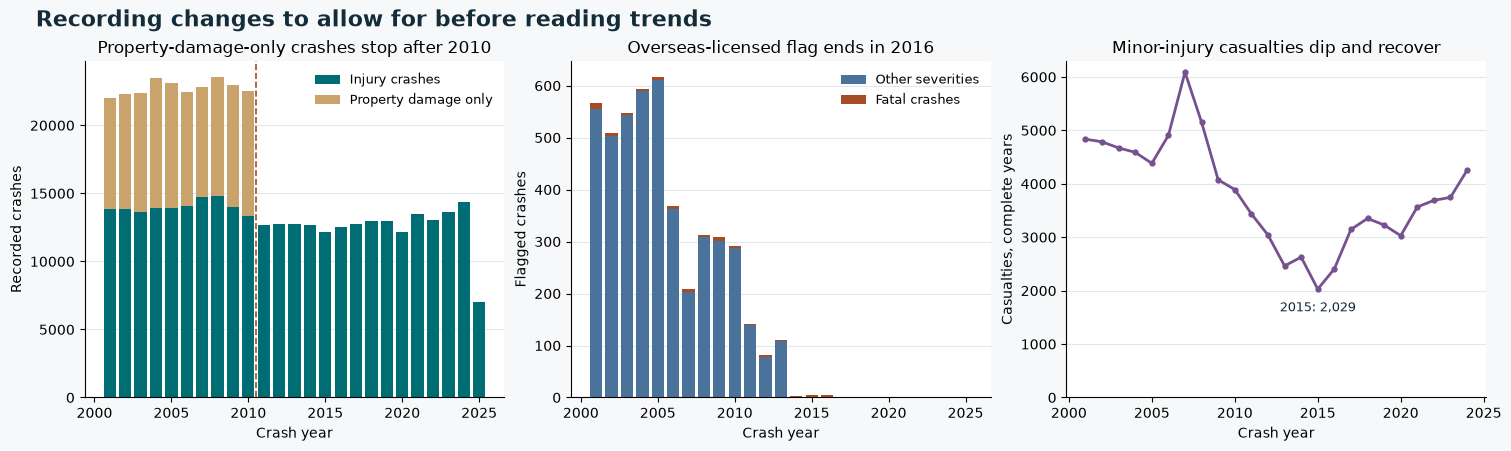

Property-damage-only crashes: 35.6–40.8% of records each year to 2010, then none.
Overseas-licensed flag: all severities to 2013, fatal crashes only to 2016, then no flagged crashes.
Minor-injury casualties: 6,089 in 2007, 2,029 in 2015, 4,253 in 2024.


In [12]:
import matplotlib.pyplot as plt

# These series describe what was recorded each year. A break here is a recording change.
record_mix = pd.crosstab(raw['Crash_Year'], raw['Crash_Severity'].eq('Property damage only'))
record_mix.columns = ['Injury crashes', 'Property damage only']
record_mix['Property damage only (%)'] = 100 * record_mix['Property damage only'] / record_mix.sum(axis=1)
last_pdo_year = int(record_mix.index[record_mix['Property damage only'].gt(0)].max())
assert record_mix.loc[record_mix.index > last_pdo_year, 'Property damage only'].eq(0).all()

# Flagged crashes by year, split into fatal and other severities.
overseas_flag = regional_sources['Demographics'].loc[
    lambda frame: frame['Involving_Overseas_Licensed_Driver'].eq('Yes')
].assign(Outcome=lambda frame: np.where(frame['Crash_Severity'].eq('Fatal'), 'Fatal crashes', 'Other crashes'))
overseas_by_year = (overseas_flag.pivot_table(index='Crash_Year', columns='Outcome', values='Count_Crashes',
                                              aggfunc='sum', fill_value=0)
                    .reindex(index=record_mix.index, columns=['Fatal crashes', 'Other crashes'], fill_value=0))
overseas_last_all_severities = int(overseas_by_year.index[overseas_by_year['Other crashes'].gt(0)].max())
overseas_last_year = int(overseas_by_year.index[overseas_by_year.sum(axis=1).gt(0)].max())

# Minor-injury casualties for years with all 12 months present.
full_years = raw.groupby('Crash_Year')['Crash_Month'].nunique().loc[lambda months: months.eq(12)].index
minor_by_year = (regional_sources['Casualties'].loc[lambda frame: frame['Casualty_Severity'].eq('Minor injury')]
                 .groupby('Crash_Year')['Casualty_Count'].sum().reindex(full_years))
minor_low_year = int(minor_by_year.idxmin())
minor_peak_before = minor_by_year.loc[:minor_low_year]

recording_audit = record_mix.join(overseas_by_year.add_prefix('Overseas-licensed flag: ')).join(
    minor_by_year.rename('Minor-injury casualties'))
display(recording_audit.round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), layout='constrained', facecolor='#f6f8fa')
fig.suptitle('Recording changes to allow for before reading trends', x=.02, ha='left',
             fontsize=16, fontweight='bold', color='#142b3a')
audit_years = record_mix.index
axes[0].bar(audit_years, record_mix['Injury crashes'], color='#006d75', label='Injury crashes')
axes[0].bar(audit_years, record_mix['Property damage only'], bottom=record_mix['Injury crashes'],
            color='#c9a36b', label='Property damage only')
axes[0].axvline(last_pdo_year + .5, color='#a64d25', linestyle='--', linewidth=1.2)
axes[0].set(title=f'Property-damage-only crashes stop after {last_pdo_year}', ylabel='Recorded crashes')
axes[0].legend(frameon=False, fontsize=9)
axes[1].bar(audit_years, overseas_by_year['Other crashes'], color='#4a729b', label='Other severities')
axes[1].bar(audit_years, overseas_by_year['Fatal crashes'], bottom=overseas_by_year['Other crashes'],
            color='#a64d25', label='Fatal crashes')
axes[1].set(title=f'Overseas-licensed flag ends in {overseas_last_year}', ylabel='Flagged crashes')
axes[1].legend(frameon=False, fontsize=9)
axes[2].plot(minor_by_year.index, minor_by_year.to_numpy(), color='#76518f', linewidth=2, marker='o', markersize=3.5)
axes[2].annotate(f'{minor_low_year}: {int(minor_by_year.loc[minor_low_year]):,}',
                 (minor_low_year, minor_by_year.loc[minor_low_year]), xytext=(0, -16),
                 textcoords='offset points', ha='center', fontsize=9, color='#142b3a')
axes[2].set(title='Minor-injury casualties dip and recover', ylabel='Casualties, complete years', ylim=(0, None))
for ax in axes:
    ax.set_xlabel('Crash year')
    ax.grid(axis='y', color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

print(f"Property-damage-only crashes: {record_mix.loc[:last_pdo_year, 'Property damage only (%)'].min():.1f}–"
      f"{record_mix.loc[:last_pdo_year, 'Property damage only (%)'].max():.1f}% of records each year to {last_pdo_year}, "
      f"then none.")
print(f"Overseas-licensed flag: all severities to {overseas_last_all_severities}, fatal crashes only to "
      f"{overseas_last_year}, then no flagged crashes.")
print(f"Minor-injury casualties: {int(minor_peak_before.max()):,} in {int(minor_peak_before.idxmax())}, "
      f"{int(minor_by_year.loc[minor_low_year]):,} in {minor_low_year}, "
      f"{int(minor_by_year.iloc[-1]):,} in {int(minor_by_year.index[-1])}.")

**What this achieved.** Found three recording changes. Property-damage-only crashes made up 35.6–40.8% of records each year to 2010 and none from 2011, so any count or share that mixes all severities changes level at that point for recording reasons. The overseas-licensed driver flag covers all severities to 2013, fatal crashes only from 2014 to 2016, and no crashes afterwards, so it is left out of the flag comparisons. Minor-injury casualties fell from 6,089 in 2007 to 2,029 in 2015 and rose to 4,253 in 2024. The source files do not explain that movement, so treat minor-injury trends with caution. `last_pdo_year` records the first break for later cells.

### Explore the prepared crash data and year–region context

#### Explore severity, crash types, time of day, and road setting

Counts use the crash-level file. Because property-damage-only crashes are recorded only in the early years, the charts here describe **injury crashes**. The share of injury crashes that were fatal or led to hospitalisation is the severity measure. It describes outcomes among recorded injury crashes. It does not measure the risk of crashing.

**In this cell.** Tabulate all records by severity, then chart injury crashes by severity and crash type. Show the fatal-or-hospitalisation share by day of week and hour, and by remoteness area and speed zone. Chart how many missing locations were recovered.

,Crashes,Share
Crash_Severity,,
Hospitalisation,133287,32.1%
Medical treatment,130109,31.3%
Property damage only,87432,21.0%
Minor injury,58188,14.0%
Fatal,6391,1.5%


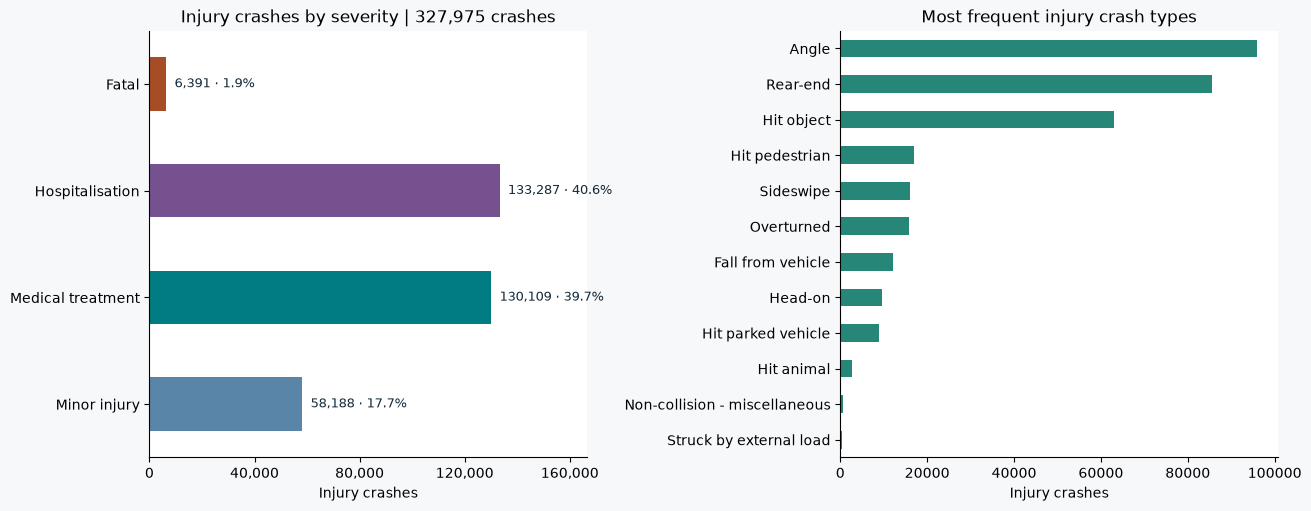

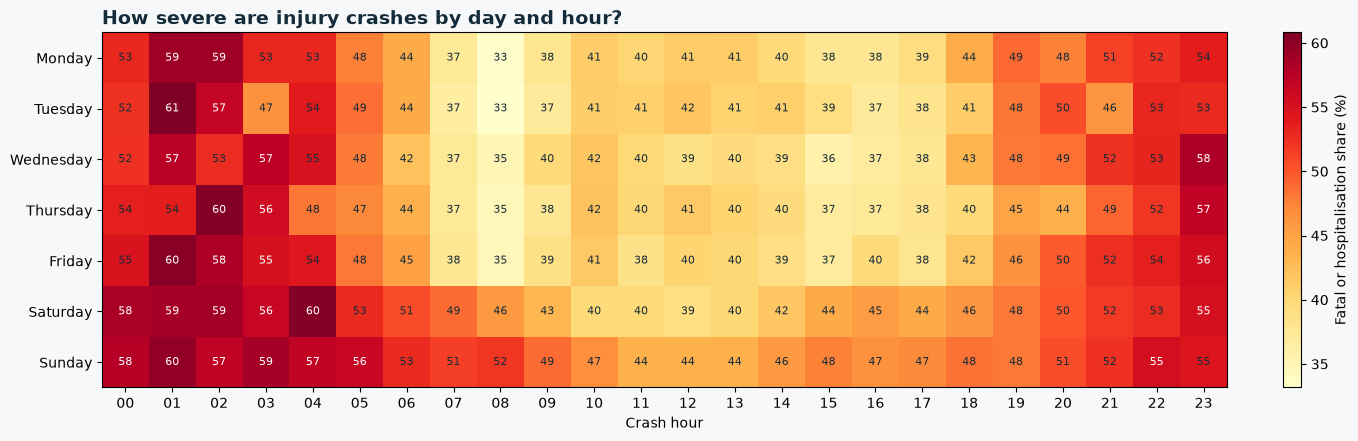

,Injury crashes,Fatal or hospitalisation (%),Fatal (%)
"Weekday, 05:00–21:59",227701.0,39.91,1.55
"Weekend, 22:00–04:59",13379.0,57.01,4.62


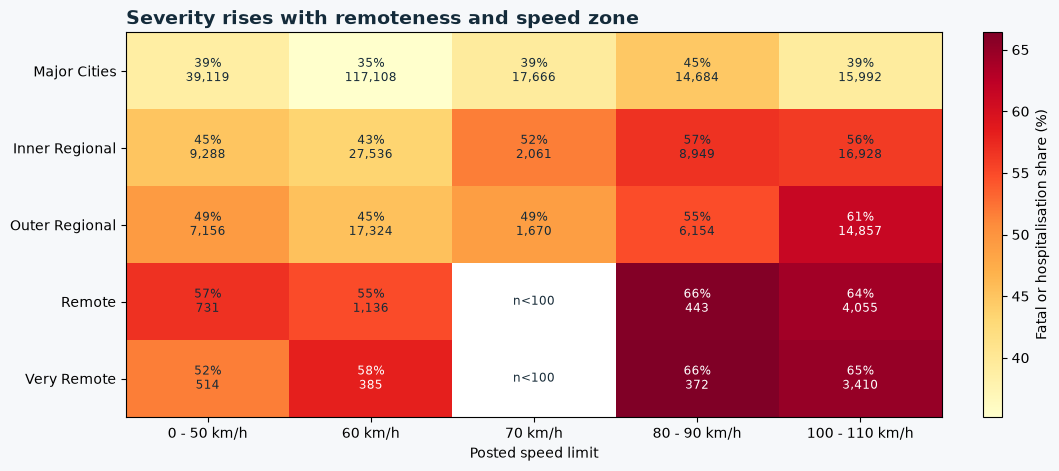

Injury crashes  Fatal (%)
Remoteness area Major Cities            204570       1.09
                Inner Regional           64764       3.07
                Outer Regional           47162       3.24
                Remote                    6411       5.69
                Very Remote               4690       6.08
Speed zone      0 - 50 km/h              56896       1.04
                60 km/h                 163647       0.97
                70 km/h                  21463       1.57
                80 - 90 km/h             30653       3.36
                100 - 110 km/h           55312       5.15

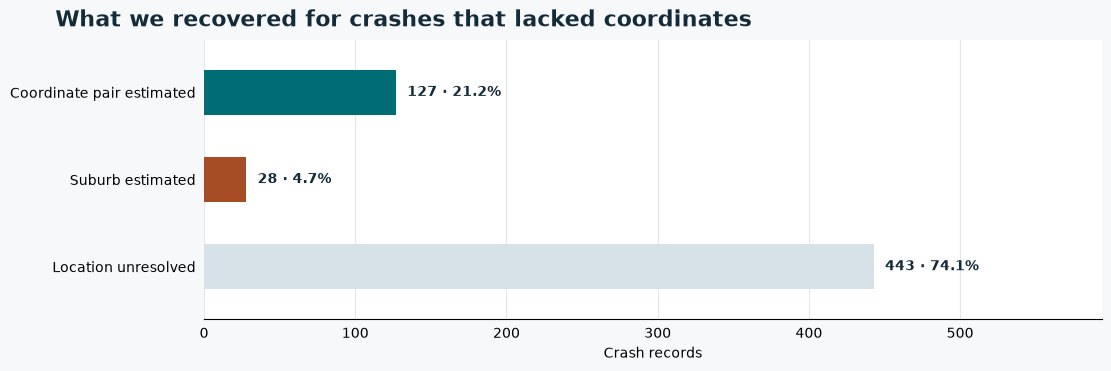

In [13]:
import matplotlib.pyplot as plt

severity = cleaned['Crash_Severity'].value_counts()
display(severity.to_frame('Crashes').assign(Share=(severity / len(cleaned)).map('{:.1%}'.format)))

# Property-damage-only crashes are recorded only in the early years, so the charts use injury crashes.
severity_order = ['Fatal', 'Hospitalisation', 'Medical treatment', 'Minor injury']
injury_only = cleaned.loc[cleaned['Crash_Severity'].isin(severity_order)]
injury_serious = injury_only['Crash_Severity'].isin(['Fatal', 'Hospitalisation'])
injury_fatal = injury_only['Crash_Severity'].eq('Fatal')
injury_severity = injury_only['Crash_Severity'].value_counts().reindex(severity_order)
assert injury_severity.sum() == len(injury_only) == len(cleaned) - severity['Property damage only']

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained', facecolor='#f6f8fa')
injury_severity.iloc[::-1].plot.barh(ax=axes[0], color=['#5985a8', '#007c82', '#76518f', '#a64d25'],
                                     title=f'Injury crashes by severity | {len(injury_only):,} crashes')
for position, count in enumerate(injury_severity.iloc[::-1]):
    axes[0].annotate(f'{count:,} · {count / len(injury_only):.1%}', (count, position), xytext=(6, 0),
                     textcoords='offset points', va='center', fontsize=9, color='#142b3a')
axes[0].set_xlim(0, injury_severity.max() * 1.25)
axes[0].set_xticks(range(0, 160_001, 40_000), [f'{tick:,}' for tick in range(0, 160_001, 40_000)])
injury_only['Crash_Nature'].value_counts().head(12).sort_values().plot.barh(
    ax=axes[1], color='#268677', title='Most frequent injury crash types'
)
for ax in axes:
    ax.set(xlabel='Injury crashes', ylabel='')
    ax.set_xlabel('Injury crashes')
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

hourly = pd.crosstab(injury_only['Crash_Severity'], injury_only['Crash_Hour']).reindex(severity_order)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
# Serious share for each day-of-week and hour cell.
day_hour = injury_serious.groupby([injury_only['Crash_Day_Of_Week'], injury_only['Crash_Hour']]).agg(['size', 'mean'])
day_hour_share = day_hour['mean'].unstack().reindex(day_order).mul(100)
day_hour_count = day_hour['size'].unstack().reindex(day_order)
assert day_hour_count.sum().sum() == len(injury_only)
fig, ax = plt.subplots(figsize=(13.5, 4.3), layout='constrained', facecolor='#f6f8fa')
image = ax.imshow(day_hour_share, cmap='YlOrRd', aspect='auto')
ax.set(xticks=range(24), xticklabels=[f'{hour:02}' for hour in day_hour_share.columns],
       yticks=range(7), yticklabels=day_order, xlabel='Crash hour')
ax.set_title('How severe are injury crashes by day and hour?', loc='left', fontsize=14,
             fontweight='bold', color='#142b3a')
for row, col in np.ndindex(day_hour_share.shape):
    value = day_hour_share.iat[row, col]
    ax.text(col, row, f'{value:.0f}', ha='center', va='center', fontsize=8,
            color='white' if value > 55 else '#172b38')
fig.colorbar(image, ax=ax, label='Fatal or hospitalisation share (%)')
plt.show()

# Contrast weekend nights with weekday daytime and evening.
night_hours = [22, 23, 0, 1, 2, 3, 4]
weekend_night = (injury_only['Crash_Day_Of_Week'].isin(['Saturday', 'Sunday'])
                 & injury_only['Crash_Hour'].isin(night_hours))
weekday_day = (~injury_only['Crash_Day_Of_Week'].isin(['Saturday', 'Sunday'])
               & ~injury_only['Crash_Hour'].isin(night_hours))
timing_contrast = pd.DataFrame({
    label: {'Injury crashes': int(mask.sum()),
            'Fatal or hospitalisation (%)': 100 * injury_serious[mask].mean(),
            'Fatal (%)': 100 * injury_fatal[mask].mean()}
    for label, mask in [('Weekday, 05:00–21:59', weekday_day), ('Weekend, 22:00–04:59', weekend_night)]
}).T
display(timing_contrast.round(2))

remoteness_order = ['Major Cities', 'Inner Regional', 'Outer Regional', 'Remote', 'Very Remote']
speed_order = ['0 - 50 km/h', '60 km/h', '70 km/h', '80 - 90 km/h', '100 - 110 km/h']
# Serious share by remoteness area and speed zone. Cells with fewer than 100 crashes are left blank.
setting = injury_serious.groupby([injury_only['Loc_ABS_Remoteness'], injury_only['Crash_Speed_Limit']]).agg(['size', 'mean'])
setting_count = setting['size'].unstack().reindex(index=remoteness_order, columns=speed_order).fillna(0).astype(int)
setting_share = setting['mean'].unstack().reindex(index=remoteness_order, columns=speed_order).mul(100)
setting_share = setting_share.where(setting_count.ge(100))
fig, ax = plt.subplots(figsize=(10.5, 4.6), layout='constrained', facecolor='#f6f8fa')
image = ax.imshow(setting_share, cmap='YlOrRd', aspect='auto')
ax.set(xticks=range(len(speed_order)), xticklabels=speed_order, yticks=range(len(remoteness_order)),
       yticklabels=remoteness_order, xlabel='Posted speed limit')
ax.set_title('Severity rises with remoteness and speed zone', loc='left', fontsize=14,
             fontweight='bold', color='#142b3a')
for row, col in np.ndindex(setting_share.shape):
    value, count = setting_share.iat[row, col], setting_count.iat[row, col]
    label = f'{value:.0f}%\n{count:,}' if np.isfinite(value) else f'n<100'
    ax.text(col, row, label, ha='center', va='center', fontsize=8.5,
            color='white' if np.isfinite(value) and value > 58 else '#172b38')
fig.colorbar(image, ax=ax, label='Fatal or hospitalisation share (%)')
plt.show()

setting_summary = pd.concat({
    'Remoteness area': pd.DataFrame({'Injury crashes': injury_only.groupby('Loc_ABS_Remoteness').size(),
                                     'Fatal (%)': injury_fatal.groupby(injury_only['Loc_ABS_Remoteness']).mean().mul(100)}
                                    ).reindex(remoteness_order),
    'Speed zone': pd.DataFrame({'Injury crashes': injury_only.groupby('Crash_Speed_Limit').size(),
                                'Fatal (%)': injury_fatal.groupby(injury_only['Crash_Speed_Limit']).mean().mul(100)}
                               ).reindex(speed_order),
})
display(setting_summary.round(2))

# Show what was recovered from the records that started with missing coordinates.
resolved_pair_count = int(available['Coordinate pair'].loc[targets].sum())
suburb_only_count = int((~available['Coordinate pair'] & available['Suburb']).loc[targets].sum())
missing_both_count = len(targets) - resolved_pair_count - suburb_only_count
fig, ax = plt.subplots(figsize=(11, 3.6), layout='constrained', facecolor='#f6f8fa')
fig.suptitle('What we recovered for crashes that lacked coordinates', x=.045, ha='left',
             fontsize=16, fontweight='bold', color='#142b3a')
categories = [
    ('Coordinate pair estimated', resolved_pair_count, '#006d75'),
    ('Suburb estimated', suburb_only_count, '#a64d25'),
    ('Location unresolved', missing_both_count, '#d7e1e8'),
]
counts = [count for _, count, _ in categories]
ax.barh(range(len(categories)), counts, color=[color for _, _, color in categories], height=.52)
ax.set(yticks=range(len(categories)), yticklabels=[label for label, _, _ in categories],
       ylim=(2.6, -.6), xlim=(0, max(counts) * 1.34), xlabel='Crash records')
for y, (_, count, _) in enumerate(categories):
    ax.annotate(f'{count:,} · {count / len(targets):.1%}', (count, y), xytext=(8, 0),
                textcoords='offset points', va='center', fontsize=10, color='#142b3a', fontweight='bold')
ax.grid(axis='x', color='#e1e8ed', zorder=0)
ax.set_axisbelow(True)
ax.tick_params(length=0, pad=6)
ax.spines[['top', 'right', 'left']].set_visible(False)
plt.show()

**What this achieved.** Summarised injury-crash severity, crash types, timing, road setting and location recovery. Of 327,975 injury crashes, 133,287 (40.6%) led to hospitalisation and 6,391 (1.9%) were fatal. 15:00 had the most injury crashes. The fatal-or-hospitalisation share was 57.0% on weekend nights (22:00–04:59) compared with 39.9% on weekdays between 05:00 and 21:59, and the fatal share was 4.62% compared with 1.55%. The fatal share rose from 1.09% in major cities to 6.08% in very remote areas, and from 0.97% in 60 km/h zones to 5.15% in 100–110 km/h zones. These are shares of recorded injury crashes. If minor crashes are less completely reported in remote areas, the remote shares are overstated.

#### Map the crashes

Toggle the sampled density and severity layers. Inferred coordinates appear in their own optional layer. Its markers are approximate locations, with the estimation method in each tooltip. Both interactive maps use Esri World Street Map.

**In this cell.** Build a Folium map on an Esri basemap. Show observed crash density as a heatmap, add sampled markers by severity, and place estimated coordinates in their own map layer.

In [14]:
from html import escape

import folium
from folium.plugins import HeatMap

# Keep observed and estimated coordinates apart so that estimates never feed the density layer.
map_points = cleaned.dropna(subset=COORDS)
observed_points = map_points.loc[map_points['Coordinate_Method'].eq('observed')]
inferred_points = map_points.loc[map_points['Coordinate_Method'].ne('observed')]
severity_colors = {
    'Fatal': '#9d2525', 'Hospitalisation': '#db6820', 'Medical treatment': '#8c618f',
    'Minor injury': '#197a8c', 'Property damage only': '#456c46',
}
crash_map = folium.Map(
    location=observed_points[COORDS].median().tolist(), zoom_start=6, tiles='Esri.WorldStreetMap'
)
# A 5,000-point sample keeps the heatmap responsive.
density_points = observed_points.sample(n=min(5000, len(observed_points)), random_state=SEED)
HeatMap(density_points[COORDS].to_numpy().tolist(), name='Observed crash density', radius=14).add_to(crash_map)

# One optional layer of sampled markers per severity level.
for level, color in severity_colors.items():
    layer = folium.FeatureGroup(name=level, show=False).add_to(crash_map)
    rows = observed_points.loc[observed_points['Crash_Severity'].eq(level), COORDS]
    for point in rows.sample(n=min(180, len(rows)), random_state=SEED).to_numpy().tolist():
        folium.CircleMarker(point, radius=3, color=color, fill=True, fill_opacity=.65,
                            weight=1, tooltip=level).add_to(layer)

# Estimated locations sit in their own layer, with the estimation method in each tooltip.
estimate_layer = folium.FeatureGroup(name='Inferred coordinates', show=False).add_to(crash_map)
for lat, lon, method in inferred_points[[*COORDS, 'Coordinate_Method']].itertuples(index=False, name=None):
    folium.CircleMarker([lat, lon], radius=3, color='#53389e', fill=True, fill_opacity=.55,
                        weight=1, tooltip=escape(method)).add_to(estimate_layer)
folium.LayerControl(collapsed=False).add_to(crash_map)
display(crash_map)

**Static picture of the map above.** A saved notebook may show "Make this Notebook Trusted to load map" in place of an interactive map. The picture below shows the same view from the run saved on 20 November 2026. For the interactive version, run the cell above or open `Queensland Traffic V5 - Esri Maps.html` in a browser.

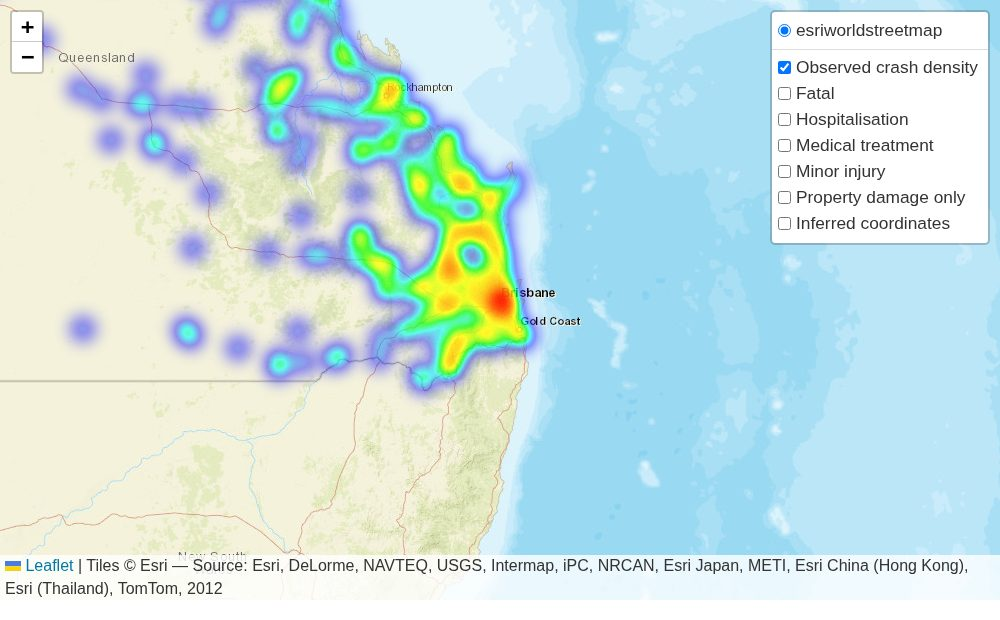

**What this achieved.** Built an interactive Esri map with observed crash density, sampled severity markers and a separate layer for estimated coordinates.

#### Vehicle involvement and crash severity

Use the aggregate vehicle table and weight by `Count_Crashes`. Compare cases involving a motorcycle or moped, a truck, or a bus with cases without that particular flag. A crash can involve multiple vehicle types. Reported injury crashes are the common basis for severity and trend comparisons because property-damage-only coverage changes over time. The latest five complete years in the locations file set the comparison window. The partial 2025 series is excluded from full-year comparisons.

The fatal and hospitalisation shares describe severity among recorded injury crashes. Vehicle trips, distance travelled, and fleet exposure are outside the source data.

**In this cell.** Weight the vehicle analysis by reported crash counts and compare injury severity with and without each vehicle flag. Use annual trends, paired comparisons, and box plots to show how involvement and severity vary across complete years.

Vehicle severity comparison for 2020–2024


Injury crashes  Fatal crashes  Fatal share (%)  \
Vehicle             Status                                                     
Motorcycle or moped Involved            8022            351             4.38   
                    Absent             58602            953             1.63   
Truck               Involved            4482            217             4.84   
                    Absent             62142           1087             1.75   
Bus                 Involved             934             19             2.03   
                    Absent             65690           1285             1.96   

                              Fatal or hospitalisation (%)  
Vehicle             Status                                  
Motorcycle or moped Involved                         72.36  
                    Absent                           46.79  
Truck               Involved                         53.06  
                    Absent                           49.64  
Bus                 Involved                         45.07  
                    Absent                           49.94

,Recorded injury crashes
None of these three flags,53437
Motorcycle or moped,7801
Truck,4268
Bus,867
Motorcycle or moped + Truck,184
Motorcycle or moped + Bus,37
Truck + Bus,30


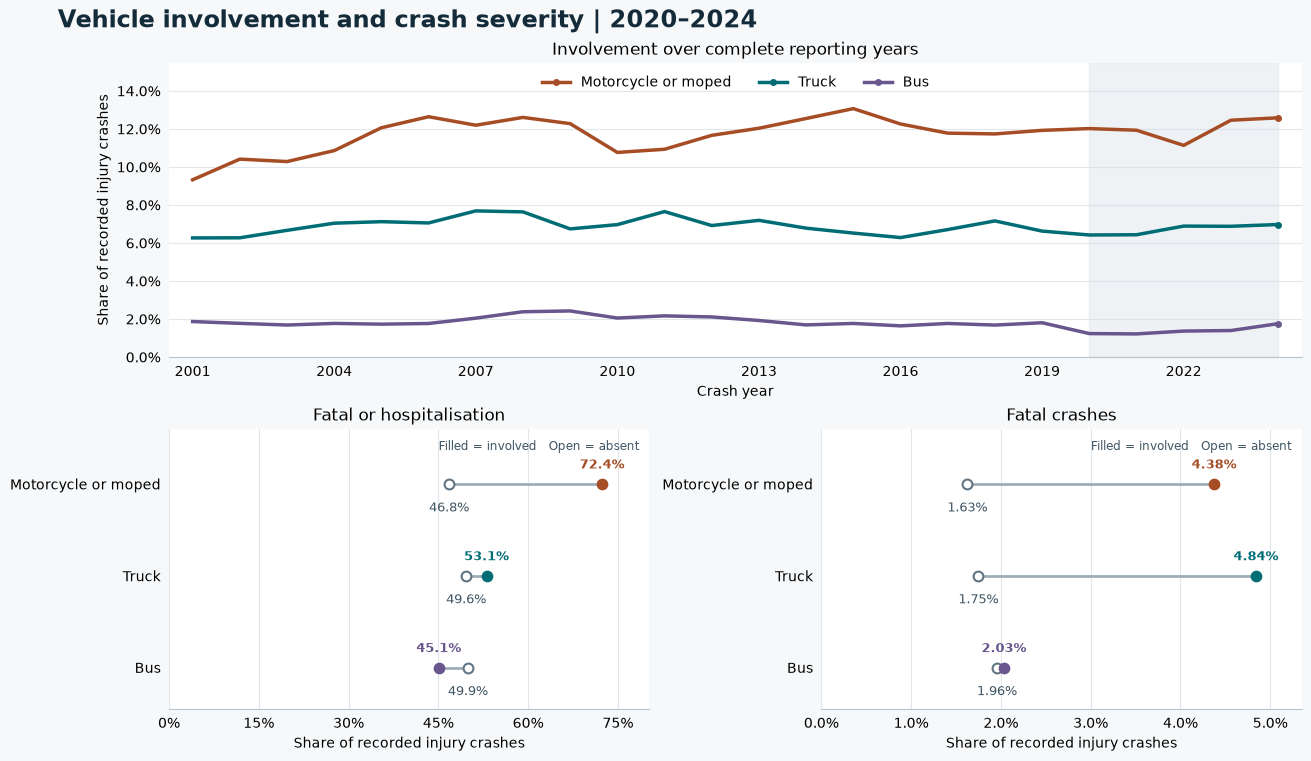

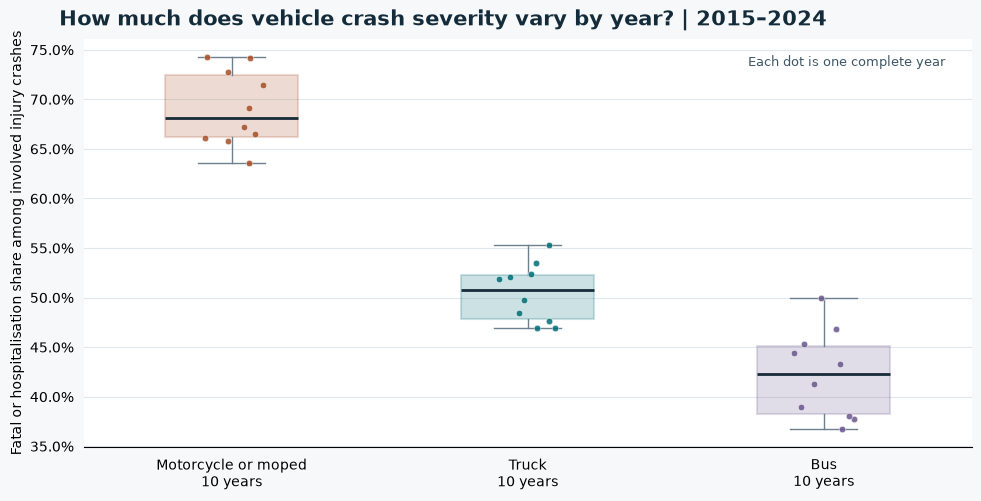

In [15]:
import matplotlib.ticker as mticker

# A complete year has crashes in all 12 months. The latest five set the comparison window.
complete_years = raw.groupby('Crash_Year')['Crash_Month'].nunique()
complete_years = complete_years.index[complete_years.eq(12)]
recent_years = complete_years[-5:]
injury_labels = ['Fatal', 'Hospitalisation', 'Medical treatment', 'Minor injury']
severe_labels = ['Fatal', 'Hospitalisation']
vehicle_flags = {
    'Motorcycle or moped': 'Involving_Motorcycle_Moped',
    'Truck': 'Involving_Truck',
    'Bus': 'Involving_Bus',
}
# Injury crashes only, because property-damage-only coverage changes over time.
vehicle_injury = regional_sources['Vehicles'].loc[
    lambda frame: frame['Crash_Severity'].isin(injury_labels)
].copy()
vehicle_recent = vehicle_injury.loc[vehicle_injury['Crash_Year'].isin(recent_years)]
assert vehicle_recent['Crash_Severity'].isin(injury_labels).all()
# Severity shares with and without each vehicle flag, weighted by crash counts.
vehicle_metrics = []
for kind, flag in vehicle_flags.items():
    for answer, label in [('Yes', 'Involved'), ('No', 'Absent')]:
        cohort = vehicle_recent.loc[vehicle_recent[flag].eq(answer)]
        counts = cohort.groupby('Crash_Severity')['Count_Crashes'].sum().reindex(injury_labels, fill_value=0)
        total = int(counts.sum())
        vehicle_metrics.append({
            'Vehicle': kind, 'Status': label, 'Injury crashes': total,
            'Fatal crashes': int(counts['Fatal']),
            'Fatal share (%)': 100 * counts['Fatal'] / total if total else np.nan,
            'Fatal or hospitalisation (%)': 100 * counts[severe_labels].sum() / total if total else np.nan,
        })
vehicle_severity = pd.DataFrame(vehicle_metrics).set_index(['Vehicle', 'Status'])
print(f'Vehicle severity comparison for {recent_years.min()}–{recent_years.max()}')
display(vehicle_severity.round(2))

# Annual involvement share for each vehicle flag over complete years.
annual_vehicle = vehicle_injury.loc[vehicle_injury['Crash_Year'].isin(complete_years)]
annual_vehicle_total = annual_vehicle.groupby('Crash_Year')['Count_Crashes'].sum()
vehicle_trends = pd.DataFrame({
    kind: annual_vehicle['Count_Crashes'].where(annual_vehicle[flag].eq('Yes'), 0)
    .groupby(annual_vehicle['Crash_Year']).sum().div(annual_vehicle_total).mul(100)
    for kind, flag in vehicle_flags.items()
})
flag_pattern_counts = vehicle_recent.groupby(list(vehicle_flags.values()))['Count_Crashes'].sum()
flag_labels = [' + '.join(kind for kind, value in zip(vehicle_flags, combination) if value == 'Yes')
               or 'None of these three flags' for combination in flag_pattern_counts.index]
vehicle_overlap = flag_pattern_counts.set_axis(flag_labels).sort_values(ascending=False)
assert vehicle_overlap.sum() == vehicle_recent['Count_Crashes'].sum()
display(vehicle_overlap.to_frame('Recorded injury crashes'))

fig = plt.figure(figsize=(13, 7.5), layout='constrained', facecolor='#f6f8fa')
grid = fig.add_gridspec(2, 2, height_ratios=[1.05, 1])
trend = fig.add_subplot(grid[0, :])
severity_axes = [fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])]
fig.suptitle(f'Vehicle involvement and crash severity | {recent_years.min()}–{recent_years.max()}',
             x=.04, ha='left', fontsize=17, fontweight='bold', color='#142b3a')
vehicle_colors = {'Motorcycle or moped': '#a64d25', 'Truck': '#006d75', 'Bus': '#68568d'}

for kind, color in vehicle_colors.items():
    trend.plot(vehicle_trends.index, vehicle_trends[kind], linewidth=2.5, color=color, label=kind,
               marker='o', markersize=4, markevery=[-1])
trend.axvspan(recent_years.min(), recent_years.max(), color='#cfdae4', alpha=.35)
trend.set(title='Involvement over complete reporting years', xlabel='Crash year',
          ylabel='Share of recorded injury crashes')
trend.yaxis.set_major_formatter(mticker.PercentFormatter())
trend.set_xlim(vehicle_trends.index.min() - .5, vehicle_trends.index.max() + .5)
trend.set_ylim(0, float(vehicle_trends.max().max()) + 2.4)
trend.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
trend.legend(loc='upper center', frameon=False, ncols=3, bbox_to_anchor=(.5, 1.0))

for ax, field, title, step in zip(
    severity_axes, ['Fatal or hospitalisation (%)', 'Fatal share (%)'],
    ['Fatal or hospitalisation', 'Fatal crashes'], [15, 1],
):
    by_flag = vehicle_severity[field].unstack().reindex(vehicle_flags)
    for y, (kind, row) in enumerate(by_flag.iterrows()):
        involved, absent = row['Involved'], row['Absent']
        ax.hlines(y, min(involved, absent), max(involved, absent), color='#9eaeb8', lw=2, zorder=2)
        ax.scatter(absent, y, s=50, facecolor='white', edgecolor='#637582', linewidth=1.5, zorder=3)
        ax.scatter(involved, y, s=55, color=vehicle_colors[kind], zorder=4)
        digits = 2 if field == 'Fatal share (%)' else 1
        ax.annotate(f'{absent:.{digits}f}%', (absent, y), xytext=(0, -13), textcoords='offset points',
                    ha='center', va='top', fontsize=9, color='#405664')
        ax.annotate(f'{involved:.{digits}f}%', (involved, y), xytext=(0, 9), textcoords='offset points',
                    ha='center', va='bottom', fontsize=9, color=vehicle_colors[kind], fontweight='bold')
    ax.set(yticks=range(len(by_flag)), yticklabels=by_flag.index,
           ylim=(len(by_flag)-.55, -.6), xlim=(0, step * (np.ceil(by_flag.max().max()/step) + .35)),
           xlabel='Share of recorded injury crashes', title=title)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(step))
    ax.xaxis.set_major_formatter(mticker.PercentFormatter())
    ax.text(.98, .96, 'Filled = involved   Open = absent', transform=ax.transAxes,
            va='top', ha='right', fontsize=8.5, color='#405664')

for ax in [trend, *severity_axes]:
    ax.set_facecolor('white')
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#b8c4cc')
    ax.tick_params(length=0, pad=6)
    ax.grid(axis='y' if ax is trend else 'x', color='#e1e8ed', zorder=0)
    ax.set_axisbelow(True)
plt.show()


# Compare variability across years using one within-vehicle rate per complete year.
box_years = complete_years[-10:]
boxes = []
for kind, flag in vehicle_flags.items():
    involved = vehicle_injury.loc[vehicle_injury[flag].eq('Yes') & vehicle_injury['Crash_Year'].isin(box_years)]
    annual_totals = involved.groupby('Crash_Year')['Count_Crashes'].sum()
    annual_severe = involved['Count_Crashes'].where(involved['Crash_Severity'].isin(severe_labels), 0)
    annual_severe = annual_severe.groupby(involved['Crash_Year']).sum()
    boxes.append(annual_severe.div(annual_totals.where(annual_totals.gt(0))).mul(100).dropna().to_numpy())

fig, ax = plt.subplots(figsize=(9.7, 4.9), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'How much does vehicle crash severity vary by year? | {box_years.min()}–{box_years.max()}',
             x=.055, ha='left', fontsize=15, fontweight='bold', color='#142b3a')
boxplot = ax.boxplot(boxes, widths=.45, patch_artist=True, showfliers=False,
                     medianprops={'color': '#172b38', 'linewidth': 2},
                     whiskerprops={'color': '#6d808e'}, capprops={'color': '#6d808e'})
jitter = np.random.default_rng(SEED)
for x, ((kind, color), values, box) in enumerate(zip(vehicle_colors.items(), boxes, boxplot['boxes']), start=1):
    box.set(facecolor=color, alpha=.20, edgecolor=color, linewidth=1.5)
    ax.scatter(x + jitter.uniform(-.11, .11, len(values)), values,
               s=22, color=color, alpha=.85, edgecolor='white', linewidth=.4, zorder=3)
ax.set(xticks=range(1, len(boxes) + 1),
       xticklabels=[f'{kind}\n{len(values)} years' for kind, values in zip(vehicle_flags, boxes)],
       ylabel='Fatal or hospitalisation share among involved injury crashes')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis='y', color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(length=0, pad=7)
ax.text(.97, .96, 'Each dot is one complete year', transform=ax.transAxes,
        ha='right', va='top', fontsize=9, color='#405664')
plt.show()

**What this achieved.** Compared injury outcomes for the three vehicle flags using weighted crash counts. The plots show the recent severity contrast, annual involvement trends, and year-to-year variation over complete years.

#### Combine all six sources by crash year and police region

Aggregate each source to one row per year and police region before joining. Preserve each source’s own denominator. A crash can appear in several source summaries and can meet several flags, so use the source totals for their respective rates. Missing groups stay blank. This table uses the reported police regions for consistency across sources.

**In this cell.** Aggregate each source to one row per crash year and police region, then align the six totals on that key. Compare group coverage and retain blanks where a source has no row for a group.

In [16]:
# One total per source for each year and police region, each from its own count column.
regional_totals = {
    'Locations': regional_sources['Locations'].groupby(group_fields, dropna=False).size(),
}
for source_name, count_field in {
    'Factors': 'Count_Crashes', 'Casualties': 'Casualty_Count', 'Vehicles': 'Count_Crashes',
    'Demographics': 'Count_Crashes', 'Restraints': 'Casualty_Count',
}.items():
    regional_totals[source_name] = regional_sources[source_name].groupby(
        group_fields, dropna=False
    )[count_field].sum(min_count=1)

regional_summary = pd.concat(regional_totals, axis=1).sort_index().astype('Int64')
assert regional_summary.index.is_unique
for name, source_total in regional_totals.items():
    assert regional_summary[name].sum() == source_total.sum()
print(f'{len(regional_summary):,} year-region groups | '
      f'{regional_summary.notna().all(axis=1).sum():,} represented in all six files')
display(regional_summary.tail(12))
# List the groups that at least one source does not report.
missing_sources = regional_summary.loc[regional_summary.isna().any(axis=1)]
if not missing_sources.empty:
    display(missing_sources)

186 year-region groups | 184 represented in all six files


Locations  Factors  Casualties  Vehicles  \
Crash_Year Police_Region                                             
2024       Far Northern         723      723         965       723   
           North Coast         2745     2745        3634      2745   
           Northern             756      756        1010       756   
           South Eastern       3141     3141        4085      3141   
           Southern            1852     1852        2596      1852   
2025       Brisbane            1889     1889        2397      1889   
           Central              585      585         786       585   
           Far Northern         345      345         467       345   
           North Coast         1372     1372        1834      1372   
           Northern             359      359         486       359   
           South Eastern       1529     1529        2004      1529   
           Southern             950      950        1272       950   

                          Demographics  Restraints  
Crash_Year Police_Region                            
2024       Far Northern            723         882  
           North Coast            2745        3382  
           Northern                756         904  
           South Eastern          3141        3846  
           Southern               1852        2497  
2025       Brisbane               1889        2221  
           Central                 585         721  
           Far Northern            345         425  
           North Coast            1372        1724  
           Northern                359         432  
           South Eastern          1529        1896  
           Southern                950        1207

,,Locations,Factors,Casualties,Vehicles,Demographics,Restraints
Crash_Year,Police_Region,,,,,,
2009,Unknown,7,7,<NA>,7,7,<NA>
2010,Unknown,36,36,<NA>,36,36,<NA>


**What this achieved.** Created a source totals table with one row per year and police region. All six files contribute to 184 of the 186 groups.

##### Explore vehicle involvement, driver characteristics, and safety

The flag table shows the share of each recorded severity group that involved each characteristic within its own source. The restraint table sums casualty counts by recorded restraint or helmet category. These descriptive counts reflect the reporting scope of the source tables.

**In this cell.** Calculate the share of crashes with each vehicle, driver, or contributing-factor flag within each recorded severity group. The overseas-licensed driver flag is left out because it stops being recorded during the series. Summarise restraint categories with weighted casualty counts. Plot annual casualty totals as counts and as an index of the first year, so the small fatality series and the larger injury series can be compared on one scale. The annual plot includes years with all 12 months represented in the locations file.

Crash severity (%)                 Hospitalisation  Medical treatment  \
Source       Recorded factor                                            
Factors      Drink Driving                     9.5                4.0   
             Driver Speed                      5.1                2.6   
             Fatigued Driver                   2.9                1.6   
             Defective Vehicle                 2.2                1.7   
Vehicles     Motorcycle Moped                 17.0                8.1   
             Truck                             7.0                6.5   
             Bus                               1.6                2.0   
Demographics Male Driver                      76.3               75.2   
             Female Driver                    46.2               58.4   
             Young Driver 16-24               33.4               37.6   
             Senior Driver 60plus             21.1               19.7   
             Provisional Driver               18.5               20.6   
             Unlicensed Driver                 7.3                4.6   

Crash severity (%)                 Property damage only  Minor injury  Fatal  
Source       Recorded factor                                                  
Factors      Drink Driving                          8.2           4.5   21.5  
             Driver Speed                           6.1           3.0   22.8  
             Fatigued Driver                        2.0           1.6    5.9  
             Defective Vehicle                      3.2           1.8    2.5  
Vehicles     Motorcycle Moped                       0.4           6.9   21.3  
             Truck                                  8.5           6.5   17.0  
             Bus                                    1.3           1.8    1.8  
Demographics Male Driver                           79.7          77.1   85.5  
             Female Driver                         46.0          55.3   27.9  
             Young Driver 16-24                    45.7          37.7   28.4  
             Senior Driver 60plus                  16.2          18.2   23.5  
             Provisional Driver                    27.5          21.0   15.1  
             Unlicensed Driver                      6.1           4.8   11.8

Casualty_Severity,Fatality,Hospitalised,Medically treated,Minor injury
Casualty_Restraint_Helmet_Use,,,,
Helmet Not Worn,127,2082,841,445
Helmet Use Not determined,83,1386,1287,1757
Helmet Worn,1357,27944,16312,6043
Not applicable,54,809,704,450
Restrained,2408,94834,117813,61516
Restraint Use Not determined,1280,21456,26085,18976
Unrestrained,884,5135,3462,1618


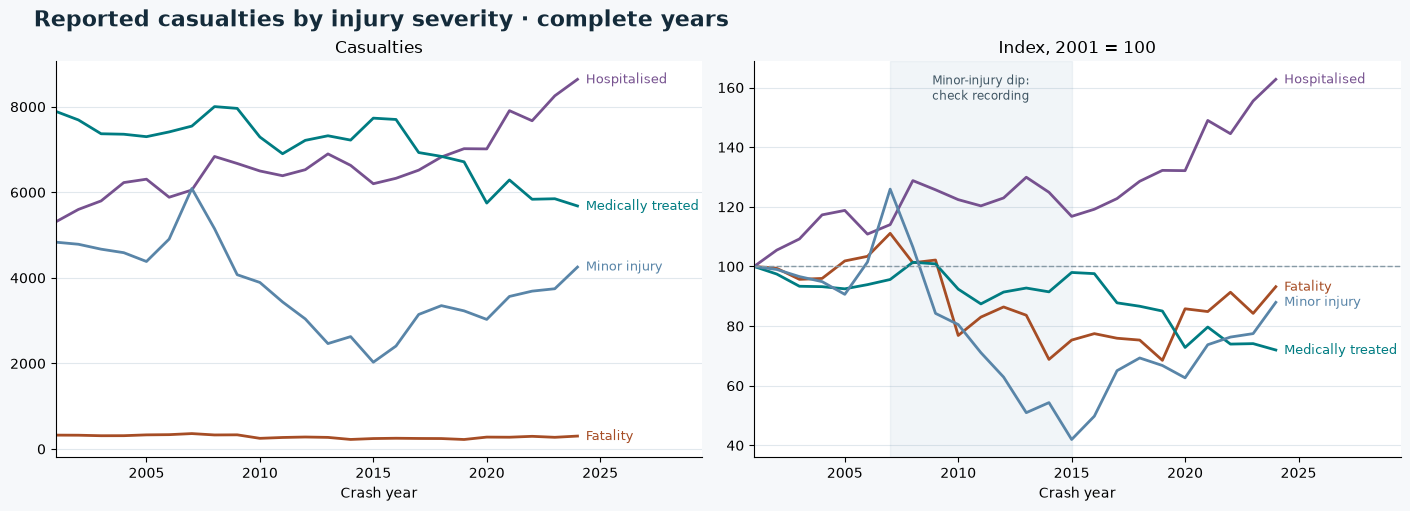

,2001,2024,Change (%)
Casualty_Severity,,,
Fatality,324,302,-6.8
Hospitalised,5309,8641,62.8
Medically treated,7893,5681,-28.0
Minor injury,4835,4253,-12.0


In [17]:
severity_flags = []
for source_name in ['Factors', 'Vehicles', 'Demographics']:
    frame = regional_sources[source_name]
    denominator = frame.groupby('Crash_Severity')['Count_Crashes'].sum()
    # The overseas-licensed flag stops being recorded part-way through the series.
    for flag in [column for column in frame if column.startswith('Involving_')
                 and column != 'Involving_Overseas_Licensed_Driver']:
        yes_counts = (frame['Count_Crashes'].where(frame[flag].eq('Yes'), 0)
                      .groupby(frame['Crash_Severity']).sum())
        percentages = yes_counts.div(denominator.where(denominator.gt(0))).mul(100)
        severity_flags.append(percentages.rename((source_name, flag.removeprefix('Involving_').replace('_', ' '))))
flag_shares = pd.DataFrame(severity_flags)
flag_shares.index = pd.MultiIndex.from_tuples(flag_shares.index, names=['Source', 'Recorded factor'])
display(flag_shares.reindex(columns=severity.index).round(1).rename_axis('Crash severity (%)', axis=1))

safety_rows = regional_sources['Restraints']
restraint_counts = safety_rows.pivot_table(
    index='Casualty_Restraint_Helmet_Use', columns='Casualty_Severity',
    values='Casualty_Count', aggfunc='sum', fill_value=0,
)
display(restraint_counts)
annual_casualties = regional_sources['Casualties'].pivot_table(
    index='Crash_Year', columns='Casualty_Severity', values='Casualty_Count', aggfunc='sum',
)
annual_casualties = annual_casualties.loc[annual_casualties.index.isin(complete_years)]
casualty_order = ['Fatality', 'Hospitalised', 'Medically treated', 'Minor injury']
casualty_colors = dict(zip(casualty_order, ['#a64d25', '#76518f', '#007c82', '#5985a8']))
annual_casualties = annual_casualties[casualty_order]
casualty_index = annual_casualties.div(annual_casualties.iloc[0]).mul(100)
first_year, last_year = int(annual_casualties.index[0]), int(annual_casualties.index[-1])
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained', facecolor='#f6f8fa')
fig.suptitle('Reported casualties by injury severity · complete years', x=.02, ha='left',
             fontsize=16, fontweight='bold', color='#142b3a')
for ax, values, title, unit in [
    (axes[0], annual_casualties, 'Casualties', ''),
    (axes[1], casualty_index, f'Index, {first_year} = 100', ''),
]:
    for level in casualty_order:
        ax.plot(values.index, values[level], color=casualty_colors[level], linewidth=2)
        ax.annotate(level, (last_year, values[level].iloc[-1]), xytext=(6, 0), textcoords='offset points',
                    va='center', fontsize=9, color=casualty_colors[level])
    ax.set(title=title, xlabel='Crash year', xlim=(first_year, last_year + 5.5))
    ax.grid(axis='y', color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[1].axhline(100, color='#879aa5', linewidth=1, linestyle='--')
axes[1].axvspan(minor_peak_before.idxmax(), minor_low_year, color='#5985a8', alpha=.08)
axes[1].text((minor_peak_before.idxmax() + minor_low_year) / 2, .97, 'Minor-injury dip:\ncheck recording',
             transform=axes[1].get_xaxis_transform(), ha='center', va='top', fontsize=8.5, color='#405664')
plt.show()
casualty_change = pd.DataFrame({
    first_year: annual_casualties.iloc[0], last_year: annual_casualties.iloc[-1],
    'Change (%)': casualty_index.iloc[-1] - 100,
})
display(casualty_change.round(1))

**What this achieved.** Compared weighted vehicle, driver and crash-factor flags by recorded severity and summarised helmet and restraint categories by injury outcome. Between 2001 and 2024, hospitalised casualties rose from 5,309 to 8,641 (62.8%), fatalities moved from 324 to 302, and medically treated casualties fell from 7,893 to 5,681 (28.0%). Hospitalised and medically treated counts moving in opposite directions may reflect a change in how injuries are classified as well as a change in outcomes, and the counts do not allow for population growth. The annual casualty trend ends in 2024. The partial 2025 records remain available in the source tallies.

##### Compare regional burden, severity and reported contributing factors

Join weighted measures at `Crash_Year` and `Police_Region`, where the sources have common coverage. Compare recorded injury crash volume, the serious crash share, the severe casualty share, speed and fatigue flags, heavy vehicle and motorcycle involvement, young-driver involvement, and protective equipment use. Each measure keeps its own within-source denominator. The protective equipment share uses records with a known helmet or restraint status.

These comparisons can identify regions where several issues warrant closer examination and show whether a high count reflects volume or a higher severity share. Associations between regional summaries do not establish that the same crashes shared those characteristics. The latest five complete years are pooled by summing numerators and denominators. The source category `Unknown` remains in the coverage audit.

**In this cell.** Build regional profiles from within-source numerators and denominators. Use scatter, bubble, and heatmap views to compare crash burden, severity, and reported factors, then summarise changes across two five-year periods.

Combined regional profile, 2020–2024


,Injury crashes,Serious crash (%),Severe casualty (%),Speed (%),Fatigue (%),Drink driving (%),Truck (%),Motorcycle or moped (%),Young driver (%),Unrestrained or helmet not worn (%)
Police_Region,,,,,,,,,,
Brisbane,18395,40.1,37.1,2.4,1.3,4.9,6.6,12.5,32.3,2.3
South Eastern,14427,43.8,40.8,3.3,1.7,7.0,5.6,11.1,33.9,3.3
North Coast,13184,52.5,48.2,4.6,2.3,8.2,5.9,12.4,32.9,4.0
Southern,8161,56.9,51.9,4.8,3.2,8.0,8.6,11.1,33.1,4.2
Central,5568,66.5,60.9,5.2,4.6,9.8,9.6,11.2,31.3,5.0
Far Northern,3446,62.5,57.6,5.2,3.3,11.8,6.6,12.8,25.1,7.4
Northern,3443,61.1,56.2,4.6,2.7,9.5,6.1,14.9,30.9,7.2


,Highest police region,Value
Measure,,
Injury crashes,Brisbane,"18,395"
Serious crash (%),Central,66.5%
Speed (%),Far Northern,5.2%
Drink driving (%),Far Northern,11.8%
Truck (%),Central,9.6%
Motorcycle or moped (%),Northern,14.9%
Unrestrained or helmet not worn (%),Far Northern,7.4%


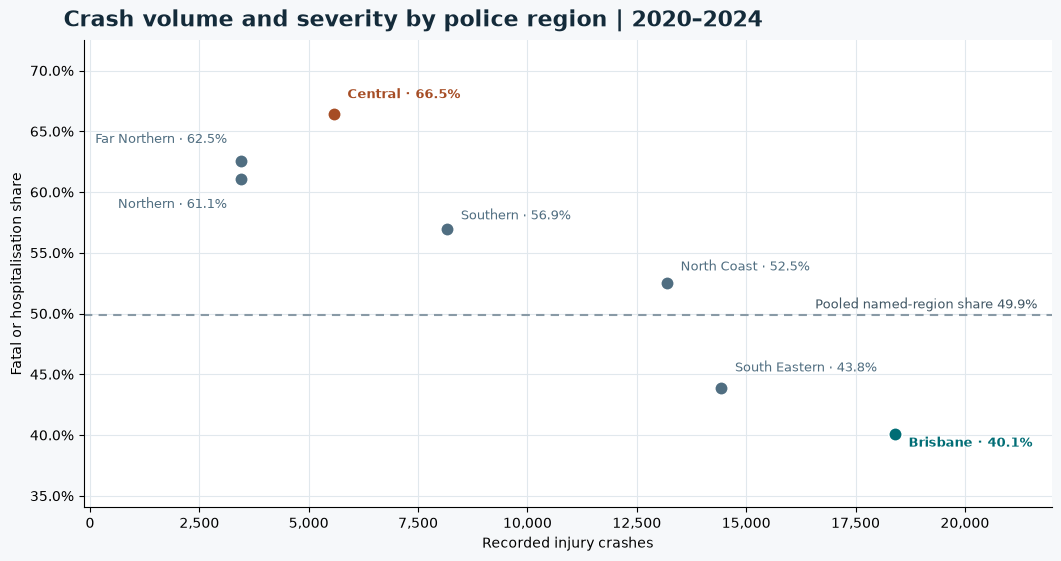

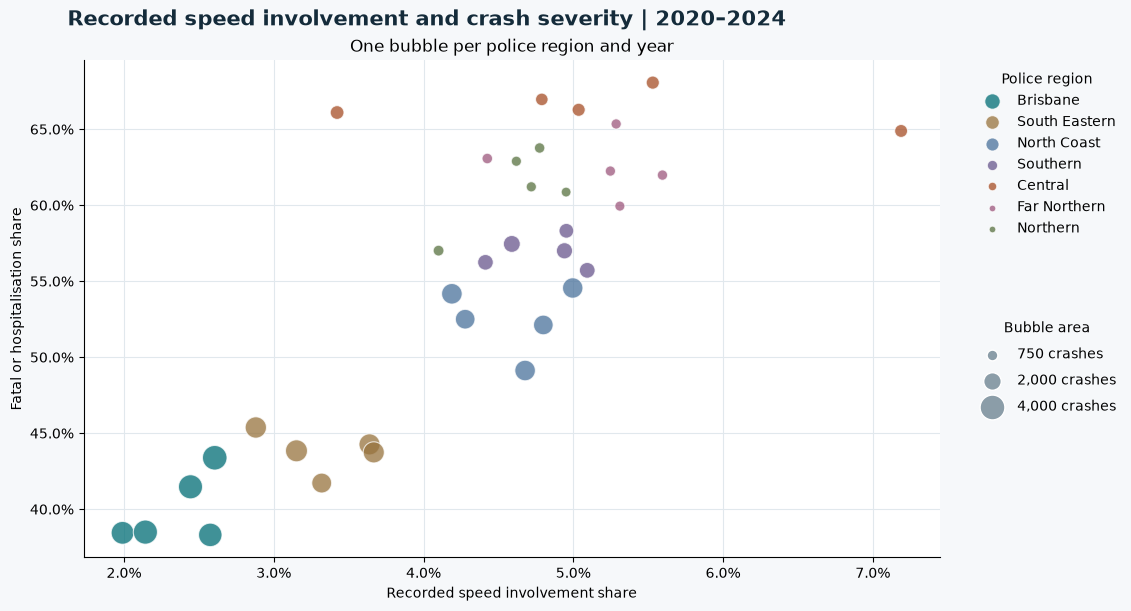

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


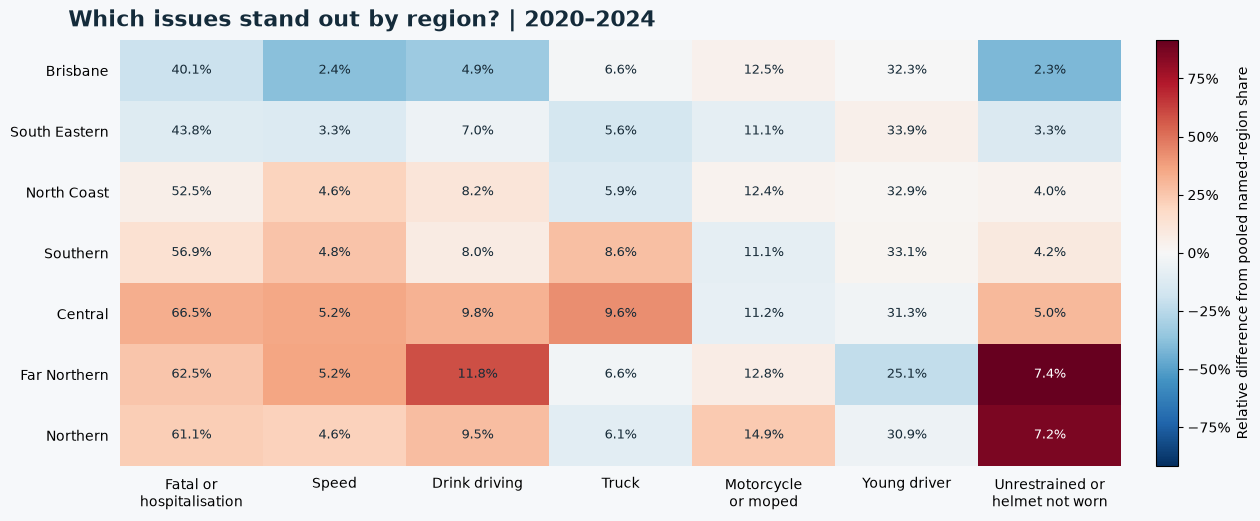

,Injury crashes,Serious crash (%),Severe casualty (%),Speed (%),Fatigue (%),Drink driving (%),Truck (%),Motorcycle or moped (%),Young driver (%),Unrestrained or helmet not worn (%)
Period,,,,,,,,,,
2015–2019,63370,44.0,40.5,3.1,2.1,5.7,6.7,12.1,33.0,3.5
2020–2024,66624,49.9,46.2,3.8,2.3,7.4,6.7,12.0,32.3,3.9


In [18]:
# Numerator and denominator by group, kept separate so periods can be pooled before dividing.
def grouped_rate(frame, count, condition, group, label):
    denominator = frame.groupby(group, dropna=False)[count].sum(min_count=1)
    numerator = frame[count].where(condition, 0).groupby([frame[key] for key in group], dropna=False).sum()
    return pd.concat({f'{label} numerator': numerator, f'{label} denominator': denominator}, axis=1)


location_injury = regional_sources['Locations'].loc[
    lambda frame: frame['Crash_Severity'].isin(injury_labels)
].assign(Records=1)
factor_injury = regional_sources['Factors'].loc[lambda frame: frame['Crash_Severity'].isin(injury_labels)]
driver_injury = regional_sources['Demographics'].loc[lambda frame: frame['Crash_Severity'].isin(injury_labels)]
casualty_records = regional_sources['Casualties']
known_equipment = safety_rows.loc[safety_rows['Casualty_Restraint_Helmet_Use'].isin([
    'Helmet Worn', 'Helmet Not Worn', 'Restrained', 'Unrestrained'
])]
# Each measure: (source table, count column, condition that defines the numerator).
metrics = {
    'Serious crash': (location_injury, 'Records', location_injury['Crash_Severity'].isin(severe_labels)),
    'Severe casualty': (casualty_records, 'Casualty_Count',
                        casualty_records['Casualty_Severity'].isin(['Fatality', 'Hospitalised'])),
    'Speed': (factor_injury, 'Count_Crashes', factor_injury['Involving_Driver_Speed'].eq('Yes')),
    'Fatigue': (factor_injury, 'Count_Crashes', factor_injury['Involving_Fatigued_Driver'].eq('Yes')),
    'Drink driving': (factor_injury, 'Count_Crashes', factor_injury['Involving_Drink_Driving'].eq('Yes')),
    'Truck': (vehicle_injury, 'Count_Crashes', vehicle_injury[vehicle_flags['Truck']].eq('Yes')),
    'Motorcycle or moped': (vehicle_injury, 'Count_Crashes', vehicle_injury[vehicle_flags['Motorcycle or moped']].eq('Yes')),
    'Young driver': (driver_injury, 'Count_Crashes', driver_injury['Involving_Young_Driver_16-24'].eq('Yes')),
    'Unrestrained or helmet not worn': (known_equipment, 'Casualty_Count',
        known_equipment['Casualty_Restraint_Helmet_Use'].isin(['Unrestrained', 'Helmet Not Worn'])),
}
regional_profile_counts = pd.concat([
    grouped_rate(frame, count, condition, group_fields, label)
    for label, (frame, count, condition) in metrics.items()
], axis=1)
assert regional_profile_counts.index.is_unique
for label in metrics:
    reported = regional_profile_counts[[f'{label} numerator', f'{label} denominator']].dropna()
    assert reported[f'{label} numerator'].le(reported[f'{label} denominator']).all()

# Pool the latest five complete years for the named regions.
regional_window = regional_profile_counts.loc[
    regional_profile_counts.index.get_level_values('Crash_Year').isin(recent_years)
    & (regional_profile_counts.index.get_level_values('Police_Region') != 'Unknown')
]
pooled_region = regional_window.groupby(level='Police_Region').sum(min_count=1)
regional_profile = pd.DataFrame({'Injury crashes': pooled_region['Serious crash denominator'].astype('Int64')})
for label in metrics:
    denominator = pooled_region[f'{label} denominator']
    regional_profile[f'{label} (%)'] = pooled_region[f'{label} numerator'].div(
        denominator.where(denominator.gt(0))
    ).mul(100)
regional_profile = regional_profile.sort_values('Injury crashes', ascending=False)
print(f'Combined regional profile, {recent_years.min()}–{recent_years.max()}')
display(regional_profile.round(1))

# Name the region with the highest value for each headline measure.
regional_findings = []
for field in ['Injury crashes', 'Serious crash (%)', 'Speed (%)', 'Drink driving (%)', 'Truck (%)',
              'Motorcycle or moped (%)', 'Unrestrained or helmet not worn (%)']:
    region = regional_profile[field].idxmax()
    value = regional_profile.at[region, field]
    formatted = f'{value:,}' if field == 'Injury crashes' else f'{value:.1f}%'
    regional_findings.append({'Measure': field, 'Highest police region': region, 'Value': formatted})
display(pd.DataFrame(regional_findings).set_index('Measure'))

fig, ax = plt.subplots(figsize=(10.5, 5.5), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Crash volume and severity by police region | {recent_years.min()}–{recent_years.max()}',
             x=.055, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
reference = pooled_region['Serious crash numerator'].sum() / pooled_region['Serious crash denominator'].sum() * 100
ax.axhline(reference, color='#899aa6', linestyle=(0, (4, 3)), zorder=1)
ax.text(.985, reference + .55, f'Pooled named-region share {reference:.1f}%',
        transform=ax.get_yaxis_transform(), ha='right', fontsize=9, color='#405664')
label_offsets = {'Central': (10, 9), 'Far Northern': (-10, 11), 'Northern': (-10, -13),
                 'Southern': (10, 5), 'Brisbane': (10, -2), 'South Eastern': (10, 10)}
for region, row in regional_profile.iterrows():
    volume, serious_share = row[['Injury crashes', 'Serious crash (%)']]
    denotation = {'Brisbane': '#006d75', 'Central': '#a64d25'}.get(region, '#506e81')
    ax.scatter(volume, serious_share, s=95, color=denotation, edgecolor='white', linewidth=1.2, zorder=3)
    dx, dy = label_offsets.get(region, (10, 7))
    ax.annotate(f'{region} · {serious_share:.1f}%', (volume, serious_share), xytext=(dx, dy),
                textcoords='offset points', ha='right' if dx < 0 else 'left',
                va='bottom' if dy > 0 else 'top', color=denotation, fontsize=9,
                fontweight='bold' if region in {'Brisbane', 'Central'} else 'normal')
ax.set(xlabel='Recorded injury crashes', ylabel='Fatal or hospitalisation share')
ax.margins(x=.24, y=.23)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

# Use one point per year and police region. Circle area represents injury crash volume.
speed_rate = (regional_window['Speed numerator'] / regional_window['Speed denominator'] * 100)
severity_rate = (regional_window['Serious crash numerator'] / regional_window['Serious crash denominator'] * 100)
bubble_data = pd.DataFrame({
    'Speed share': speed_rate, 'Severe share': severity_rate,
    'Injury crashes': regional_window['Serious crash denominator'],
}).dropna().reset_index()
region_colors = dict(zip(regional_profile.index,
                         ['#006d75', '#97733d', '#4a729b', '#68568d', '#a64d25', '#9d577d', '#587240']))
size_per_crash = .08
fig, ax = plt.subplots(figsize=(11.2, 6), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Recorded speed involvement and crash severity | {recent_years.min()}–{recent_years.max()}',
             x=.055, ha='left', fontsize=15, fontweight='bold', color='#142b3a')
for region, color in region_colors.items():
    points = bubble_data[bubble_data['Police_Region'].eq(region)]
    ax.scatter(points['Speed share'], points['Severe share'], s=points['Injury crashes'] * size_per_crash,
               alpha=.75, color=color, edgecolor='white', linewidth=.8, label=region)
ax.set(xlabel='Recorded speed involvement share', ylabel='Fatal or hospitalisation share',
       title='One bubble per police region and year')
for axis in [ax.xaxis, ax.yaxis]:
    axis.set_major_formatter(mticker.PercentFormatter())
ax.grid(color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
region_legend = ax.legend(title='Police region', bbox_to_anchor=(1.03, 1), loc='upper left',
                          frameon=False, markerscale=.65)
ax.add_artist(region_legend)
size_handles = [ax.scatter([], [], s=volume * size_per_crash, facecolor='#8b9da8', edgecolor='white',
                           label=f'{volume:,} crashes') for volume in [750, 2000, 4000]]
ax.legend(handles=size_handles, title='Bubble area', bbox_to_anchor=(1.03, .50),
          loc='upper left', frameon=False, labelspacing=.85)
plt.show()

from matplotlib.colors import TwoSlopeNorm

profile_fields = ['Serious crash', 'Speed', 'Drink driving', 'Truck', 'Motorcycle or moped', 'Young driver',
                  'Unrestrained or helmet not worn']
field_labels = ['Fatal or\nhospitalisation', 'Speed', 'Drink driving', 'Truck',
                'Motorcycle\nor moped', 'Young driver', 'Unrestrained or\nhelmet not worn']
profile_values = regional_profile[[f'{field} (%)' for field in profile_fields]].astype(float)
# Colour each cell by its relative difference from the pooled share for that measure.
state_baseline = np.array([
    100 * pooled_region[f'{field} numerator'].sum() / pooled_region[f'{field} denominator'].sum()
    for field in profile_fields
])
relative = 100 * (profile_values.to_numpy() / state_baseline - 1)
color_limit = max(25, float(np.nanmax(np.abs(relative))))
norm = TwoSlopeNorm(vmin=-color_limit, vcenter=0, vmax=color_limit)
fig, ax = plt.subplots(figsize=(12.5, 5.1), layout='constrained', facecolor='#f6f8fa')
fig.suptitle(f'Which issues stand out by region? | {recent_years.min()}–{recent_years.max()}',
             x=.05, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
image = ax.imshow(relative, cmap='RdBu_r', norm=norm, aspect='auto')
ax.set(xticks=range(len(field_labels)), xticklabels=field_labels, yticks=range(len(profile_values)),
       yticklabels=profile_values.index)
ax.tick_params(length=0, pad=8)
for row, col in np.ndindex(relative.shape):
    value = profile_values.iat[row, col]
    color = 'white' if abs(relative[row, col]) > .66 * color_limit else '#172b38'
    ax.text(col, row, f'{value:.1f}%' if np.isfinite(value) else '—',
            ha='center', va='center', color=color, fontsize=9, fontweight='medium')
ax.spines[:].set_visible(False)
scale = fig.colorbar(image, ax=ax, fraction=.033, pad=.035)
scale.set_label('Relative difference from pooled named-region share')
scale.ax.yaxis.set_major_formatter(mticker.PercentFormatter())
plt.show()

# Compare early and recent periods consistently across all supplements.
recent_start = int(recent_years.min())
prior_years = list(range(recent_start - 5, recent_start))
comparison_years = [prior_years, list(recent_years)]
statewide_profile = []
for years in comparison_years:
    period = regional_profile_counts.loc[regional_profile_counts.index.get_level_values('Crash_Year').isin(years)]
    pooled = period.sum(min_count=1)
    values = {'Period': f'{years[0]}–{years[-1]}', 'Injury crashes': int(pooled['Serious crash denominator'])}
    for label in metrics:
        numerator, denominator = pooled[[f'{label} numerator', f'{label} denominator']]
        values[f'{label} (%)'] = 100 * numerator / denominator if pd.notna(denominator) and denominator > 0 else np.nan
    statewide_profile.append(values)
display(pd.DataFrame(statewide_profile).set_index('Period').round(1))

**What this achieved.** Compared regional crash volume, serious outcomes and reported factors with separate source denominators. For 2020–2024, Brisbane had the most injury crashes and Central had the highest fatal-or-hospitalisation share.

##### Allow for each region's road mix

Regions differ in where their crashes happen. A region with more crashes on remote, high-speed roads will show a higher serious-crash share even if a crash in any given road setting is no more severe there than elsewhere. Indirect standardisation separates the two. For each region, the expected share applies the statewide serious share for every combination of ABS remoteness area and posted speed zone to that region's own crashes. The ratio of the recorded count to the expected count shows what remains after road setting is taken into account.

A ratio near 1 means the region's severity is what its road mix predicts. The comparison adjusts only for remoteness and speed zone. Where one region supplies most of the crashes in a setting, that setting's statewide share is largely its own, which pulls its ratio towards 1.

**In this cell.** Calculate the statewide serious share within each remoteness-by-speed-zone group for the latest five complete years. Apply those shares to each region's crashes to obtain an expected count, then compare it with the recorded count. Add Wilson 95% intervals for the recorded share and plot recorded and expected shares together.

,Injury crashes,Recorded serious crashes,Expected serious crashes,Recorded share (%),Expected share from road mix (%),Recorded ÷ expected,Ratio 95% low,Ratio 95% high,Outer regional or remote (%)
Police_Region,,,,,,,,,
Central,5568,3700,3532.0,66.5,63.4,1.048,1.028,1.067,46.2
Far Northern,3446,2155,2165.0,62.5,62.8,0.995,0.969,1.021,100.0
Northern,3443,2103,2158.0,61.1,62.7,0.974,0.948,1.000,100.0
Southern,8161,4646,4566.0,56.9,55.9,1.018,0.998,1.037,14.2
North Coast,13184,6921,6655.0,52.5,50.5,1.040,1.023,1.057,3.4
South Eastern,14427,6325,6330.0,43.8,43.9,0.999,0.981,1.018,0.0
Brisbane,18395,7376,7821.0,40.1,42.5,0.943,0.927,0.960,0.3


Recorded shares span 26.4 percentage points across regions. After allowing for road mix, the gaps range from -2.4 to +3.0 points.


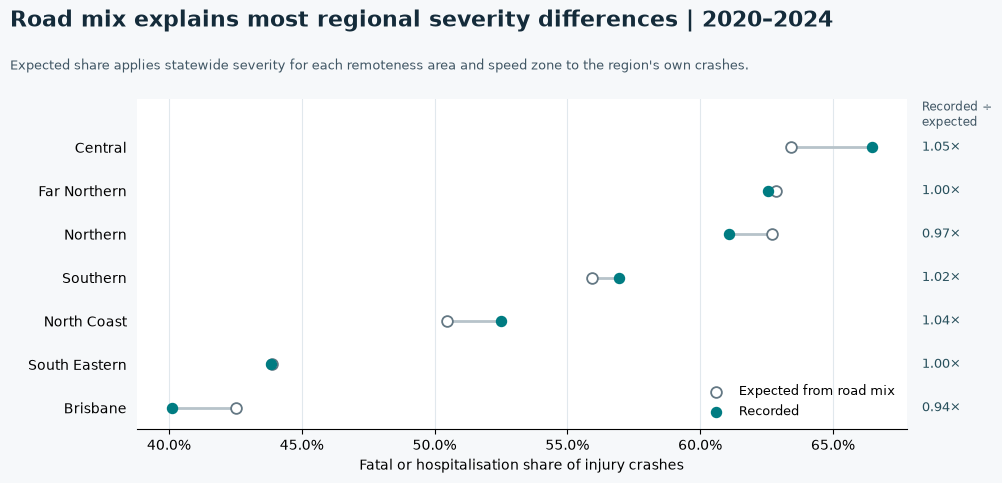

In [19]:
def wilson_interval(successes, totals, z=1.959964):
    """Wilson score interval for a binomial share, returned as fractions."""
    successes, totals = np.asarray(successes, dtype=float), np.asarray(totals, dtype=float)
    share = successes / totals
    centre = (share + z**2 / (2 * totals)) / (1 + z**2 / totals)
    half = z * np.sqrt(share * (1 - share) / totals + z**2 / (4 * totals**2)) / (1 + z**2 / totals)
    return centre - half, centre + half


mix_fields = ['Loc_ABS_Remoteness', 'Crash_Speed_Limit']
mix_records = location_injury.loc[
    location_injury['Crash_Year'].isin(recent_years) & location_injury['Police_Region'].ne('Unknown')
].dropna(subset=mix_fields).assign(Serious=lambda frame: frame['Crash_Severity'].isin(severe_labels))
# Each crash's expected chance of a serious outcome is the statewide share for its road setting.
mix_records['Expected'] = mix_records.groupby(mix_fields)['Serious'].transform('mean')
region_mix = mix_records.groupby('Police_Region').agg(
    **{'Injury crashes': ('Serious', 'size'), 'Recorded serious crashes': ('Serious', 'sum'),
       'Expected serious crashes': ('Expected', 'sum')}
)
assert np.isclose(region_mix['Recorded serious crashes'].sum(), region_mix['Expected serious crashes'].sum())
region_mix['Recorded share (%)'] = 100 * region_mix['Recorded serious crashes'] / region_mix['Injury crashes']
region_mix['Expected share from road mix (%)'] = 100 * region_mix['Expected serious crashes'] / region_mix['Injury crashes']
region_mix['Recorded ÷ expected'] = region_mix['Recorded serious crashes'] / region_mix['Expected serious crashes']
# Interval for the ratio: the Wilson interval for the recorded share divided by the expected share.
low, high = wilson_interval(region_mix['Recorded serious crashes'], region_mix['Injury crashes'])
expected_share = region_mix['Expected share from road mix (%)'] / 100
region_mix['Ratio 95% low'], region_mix['Ratio 95% high'] = low / expected_share, high / expected_share
region_mix['Outer regional or remote (%)'] = 100 * mix_records['Loc_ABS_Remoteness'].isin(
    ['Outer Regional', 'Remote', 'Very Remote']).groupby(mix_records['Police_Region']).mean()
region_mix = region_mix.sort_values('Recorded share (%)', ascending=False)
display(region_mix.round({'Expected serious crashes': 0, 'Recorded share (%)': 1,
                          'Expected share from road mix (%)': 1, 'Recorded ÷ expected': 3,
                          'Ratio 95% low': 3, 'Ratio 95% high': 3, 'Outer regional or remote (%)': 1}))
recorded_spread = region_mix['Recorded share (%)'].max() - region_mix['Recorded share (%)'].min()
residual_spread = (region_mix['Recorded share (%)'] - region_mix['Expected share from road mix (%)'])
print(f"Recorded shares span {recorded_spread:.1f} percentage points across regions. "
      f"After allowing for road mix, the gaps range from {residual_spread.min():+.1f} to {residual_spread.max():+.1f} points.")

fig, ax = plt.subplots(figsize=(11, 5), facecolor='#f6f8fa')
fig.subplots_adjust(left=.16, right=.86, bottom=.14, top=.80)
fig.suptitle(f'Road mix explains most regional severity differences | {recent_years.min()}–{recent_years.max()}',
             x=.045, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.045, .86, 'Expected share applies statewide severity for each remoteness area and speed zone to the region\'s own crashes.',
         fontsize=9.5, color='#405664')
positions = np.arange(len(region_mix))
recorded_share, road_mix_share = region_mix['Recorded share (%)'], region_mix['Expected share from road mix (%)']
ax.hlines(positions, np.minimum(recorded_share, road_mix_share), np.maximum(recorded_share, road_mix_share),
          color='#b7c3ca', linewidth=2)
ax.scatter(road_mix_share, positions, facecolor='white', edgecolor='#647884', linewidth=1.3, s=60,
           label='Expected from road mix', zorder=3)
ax.scatter(recorded_share, positions, color='#007c82', s=52, label='Recorded', zorder=4)
for y, (_, row) in zip(positions, region_mix.iterrows()):
    ax.annotate(f"{row['Recorded ÷ expected']:.2f}×", (1.02, y), xycoords=('axes fraction', 'data'),
                va='center', fontsize=9.5, color='#28505c')
ax.annotate('Recorded ÷\nexpected', (1.02, -.75), xycoords=('axes fraction', 'data'), va='center',
            fontsize=8.5, color='#405664', annotation_clip=False)
ax.set(yticks=positions, yticklabels=region_mix.index, ylim=(len(positions) - .5, -1.1),
       xlabel='Fatal or hospitalisation share of injury crashes')
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.grid(axis='x', color='#e1e8ed')
ax.set_axisbelow(True)
ax.legend(loc='lower right', frameon=False, fontsize=9)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0, pad=7)
plt.show()

**What this achieved.** Recorded serious-crash shares ranged from 40.1% in Brisbane to 66.5% in Central, a spread of 26.4 percentage points. After allowing for each region's mix of remoteness area and speed zone, recorded shares were within −2.4 to +3.0 points of the expected shares, and recorded serious crashes were between 0.94 (Brisbane) and 1.05 (Central) times the expected number. The intervals for Central (1.03–1.07), North Coast (1.02–1.06) and Brisbane (0.93–0.96) exclude 1, so small differences remain. Most of the regional ranking reflects where crashes happen.

#### Export a flat file for casualty, restraint, driver and crash context

The CSV has one row per **crash year and police region**. Each set of columns is calculated from its own source before joining. The casualty and restraint files can be checked at a finer shared level using age group, recorded gender, road-user type, injury severity, year, and region. Road casualties reports drivers and passengers separately. The restraint file groups them as vehicle occupants.

The column prefixes identify their units and source:

- `casualty_` counts casualties from Road casualties, including separate driver and passenger totals by recorded gender.
- `seatbelt_`, `bicycle_helmet_`, and `motorcycle_helmet_` count casualties by equipment status and recorded gender from the restraint file. Columns ending in `_fatalities` count only fatalities within that category. Unknown and inapplicable status have their own columns.
- `driver_` and `factor_` count crashes with a reported flag from their respective files. A crash can meet more than one flag.
- `weather_` counts crashes and people killed by the atmospheric condition recorded in Road crash locations. Weather totals are available for the region and year as a whole.

A zero means the source reports the group and no records meet the condition. A blank means the source lacks that year-region group. Pool counts before calculating percentages. This dataset supports restraint-by-gender analysis among vehicle-occupant casualties and weather-by-fatality analysis overall. The files contain no joint breakdown linking gender, restraint status, and weather for the same casualty.

**In this cell.** Reconcile the casualty and restraint files by year, region, age, gender, road user, and injury severity. Aggregate the aligned data and the separate driver, crash-factor, and weather measures into a flat year–region export.

In [20]:
# Sum a count column under several named conditions for each year and police region.
def count_flows_by_region(frame, value_column, masks):
    measures = pd.DataFrame({
        name: frame[value_column].where(mask, 0) for name, mask in masks.items()
    }, index=frame.index)
    return measures.groupby([frame[key] for key in group_fields], dropna=False).sum(min_count=1)


casualty_source = regional_sources['Casualties']
equipment_source = regional_sources['Restraints']
road_user_column = 'Casualty_Road_User_Type'
# Treat drivers and passengers as vehicle occupants so the two casualty files share road-user categories.
casualty_for_alignment = casualty_source.rename(columns={'Casualty_RoadUserType': road_user_column}).copy()
casualty_for_alignment[road_user_column] = casualty_for_alignment[road_user_column].replace(
    {'Driver': 'Vehicle Occupant', 'Passenger': 'Vehicle Occupant'}
)
equipment_users = equipment_source[road_user_column].unique()
detail_key = [*group_fields, 'Casualty_AgeGroup', 'Casualty_Gender', road_user_column, 'Casualty_Severity']
casualty_equipment_detail = pd.concat({
    'Road casualties': casualty_for_alignment.loc[casualty_for_alignment[road_user_column].isin(equipment_users)]
        .groupby(detail_key, dropna=False)['Casualty_Count'].sum(),
    'Restraint and helmet records': equipment_source.groupby(detail_key, dropna=False)['Casualty_Count'].sum(),
}, axis=1).sort_index().astype('Int64')
detail_matches = casualty_equipment_detail['Road casualties'].fillna(0).eq(
    casualty_equipment_detail['Restraint and helmet records'].fillna(0)
)
print(f'Detailed casualty/equipment reconciliation: {int(detail_matches.sum()):,} of {len(detail_matches):,} groups match.')

gender_groups = ['Female', 'Male', 'Unknown']
any_casualty = casualty_source['Casualty_Count'].notna()
fatal_casualty = casualty_source['Casualty_Severity'].eq('Fatality')
casualty_masks = {'casualty_total': any_casualty, 'casualty_fatalities': fatal_casualty}
for gender in gender_groups:
    group = casualty_source['Casualty_Gender'].eq(gender)
    casualty_masks[f'casualty_{gender.lower()}_total'] = group
    casualty_masks[f'casualty_{gender.lower()}_fatalities'] = group & fatal_casualty
    for user in ['Driver', 'Passenger', 'Pedestrian', 'Bicyclist', 'Motorcyclist', 'Other']:
        belongs = group & casualty_source['Casualty_RoadUserType'].eq(user)
        prefix = f'casualty_{gender.lower()}_{user.lower()}'
        casualty_masks[f'{prefix}_total'] = belongs
        casualty_masks[f'{prefix}_fatalities'] = belongs & fatal_casualty
casualty_by_region = count_flows_by_region(casualty_source, 'Casualty_Count', casualty_masks)

seatbelt_labels = {
    'Restrained': 'restrained', 'Unrestrained': 'unrestrained',
    'Restraint Use Not determined': 'status_unknown', 'Not applicable': 'not_applicable',
}
helmet_labels = {
    'Helmet Worn': 'worn', 'Helmet Not Worn': 'not_worn',
    'Helmet Use Not determined': 'status_unknown', 'Not applicable': 'not_applicable',
}
equipment_masks = {}
equipment_fatal = equipment_source['Casualty_Severity'].eq('Fatality')
for road_user_type, prefix, labels in [
    ('Vehicle Occupant', 'seatbelt', seatbelt_labels),
    ('Bicyclist', 'bicycle_helmet', helmet_labels),
    ('Motorcyclist', 'motorcycle_helmet', helmet_labels),
]:
    for gender in gender_groups:
        group = equipment_source[road_user_column].eq(road_user_type) & equipment_source['Casualty_Gender'].eq(gender)
        equipment_masks[f'{prefix}_{gender.lower()}_total'] = group
        for reported, name in labels.items():
            state = group & equipment_source['Casualty_Restraint_Helmet_Use'].eq(reported)
            column = f'{prefix}_{gender.lower()}_{name}'
            equipment_masks[column] = state
            equipment_masks[f'{column}_fatalities'] = state & equipment_fatal
equipment_by_region = count_flows_by_region(equipment_source, 'Casualty_Count', equipment_masks)

# Driver and crash-factor flags counted in crashes, each from its own source.
crash_context = []
for source_name, prefix in [('Demographics', 'driver'), ('Factors', 'factor')]:
    frame = regional_sources[source_name]
    masks = {f'{prefix}_total_crashes': frame['Count_Crashes'].notna()}
    for field in frame.columns[frame.columns.str.startswith('Involving_')]:
        name = field.removeprefix('Involving_').lower().replace('-', '_')
        flagged = frame[field].eq('Yes')
        masks[f'{prefix}_{name}_crashes'] = flagged
        masks[f'{prefix}_{name}_fatal_crashes'] = flagged & frame['Crash_Severity'].eq('Fatal')
    crash_context.append(count_flows_by_region(frame, 'Count_Crashes', masks))

# Weather counts come from the crash-level file: crashes and people killed by atmospheric condition.
weather_source = regional_sources['Locations'].assign(One_Crash=1)
weather_masks = {'weather_total_crashes': weather_source['One_Crash'].eq(1)}
weather_fatality_masks = {'weather_total_fatalities': weather_source['One_Crash'].eq(1)}
for condition in sorted(weather_source['Crash_Atmospheric_Condition'].dropna().unique()):
    suffix = condition.lower().replace('/', '_').replace(' ', '_')
    in_weather = weather_source['Crash_Atmospheric_Condition'].eq(condition)
    weather_masks[f'weather_{suffix}_crashes'] = in_weather
    weather_masks[f'weather_{suffix}_fatal_crashes'] = in_weather & weather_source['Crash_Severity'].eq('Fatal')
    weather_fatality_masks[f'weather_{suffix}_fatalities'] = in_weather
weather_counts = count_flows_by_region(weather_source, 'One_Crash', weather_masks)
weather_fatalities = count_flows_by_region(weather_source, 'Count_Casualty_Fatality', weather_fatality_masks)

# Join every block on year and police region to form the flat export.
casualty_context_flat = pd.concat([
    casualty_by_region, equipment_by_region, *crash_context, weather_counts, weather_fatalities,
], axis=1).sort_index().astype('Int64')
assert casualty_context_flat.index.is_unique and casualty_context_flat.columns.is_unique
assert casualty_context_flat['casualty_total'].sum() == casualty_source['Casualty_Count'].sum()
assert casualty_context_flat[[column for column in equipment_masks if column.endswith('_total')]].sum().sum() == equipment_source['Casualty_Count'].sum()
assert casualty_context_flat['weather_total_crashes'].sum() == len(raw)
assert casualty_context_flat['weather_total_fatalities'].sum() == raw['Count_Casualty_Fatality'].sum()
casualty_context_flat.insert(0, 'Complete_Year_in_Locations', casualty_context_flat.index.get_level_values('Crash_Year').isin(complete_years))
context_export = DATA_DIR / 'Traffic casualty restraint and crash context V5.csv'
write_csv(casualty_context_flat.reset_index(), context_export)
print(f'Exported {len(casualty_context_flat):,} year-region groups to {context_export.name}.')

Detailed casualty/equipment reconciliation: 23,375 of 23,375 groups match.


Exported 186 year-region groups to Traffic casualty restraint and crash context V5.csv.


**What this achieved.** Reconciled the casualty and equipment tables at their shared demographic grain. All 23,375 comparable groups agree. Exported a 186-row context table with one row per year and police region.

##### Examples the flat file can answer

Compare the share of female or male vehicle-occupant casualties who were unrestrained among those with a known seatbelt status. The same table shows outcomes among fatal casualties. For weather, compare total fatalities and fatalities per 100 recorded crashes across atmospheric conditions, for all people combined. Both examples use the latest five complete crash years.

**In this cell.** Pool the latest five complete years before calculating seatbelt non-use shares by recorded gender. Calculate weather-specific fatality counts and rates separately for all people.

In [21]:
context_recent = casualty_context_flat.loc[
    casualty_context_flat.index.get_level_values('Crash_Year').isin(recent_years)
].drop(columns='Complete_Year_in_Locations')
context_totals = context_recent.sum(min_count=1)
# Pool counts across the window before calculating any share.
belt_examples = []
for gender in ['female', 'male']:
    prefix = f'seatbelt_{gender}'
    fastened = int(context_totals[f'{prefix}_restrained'])
    unfastened = int(context_totals[f'{prefix}_unrestrained'])
    fatal_fastened = int(context_totals[f'{prefix}_restrained_fatalities'])
    fatal_unfastened = int(context_totals[f'{prefix}_unrestrained_fatalities'])
    belt_examples.append({
        'Recorded gender': gender.title(),
        'Occupant casualties with known status': fastened + unfastened,
        'Unrestrained': unfastened,
        'Unrestrained share (%)': 100 * unfastened / (fastened + unfastened),
        'Fatalities with known status': fatal_fastened + fatal_unfastened,
        'Unrestrained fatalities': fatal_unfastened,
        'Unrestrained share of fatalities with known status (%)': 100 * fatal_unfastened / (fatal_fastened + fatal_unfastened),
    })
display(pd.DataFrame(belt_examples).set_index('Recorded gender').round(2))

# Fatalities per 100 recorded crashes for each atmospheric condition.
weather_examples = []
for condition in sorted(weather_source['Crash_Atmospheric_Condition'].dropna().unique()):
    field = condition.lower().replace('/', '_').replace(' ', '_')
    crashes = int(context_totals[f'weather_{field}_crashes'])
    deaths = int(context_totals[f'weather_{field}_fatalities'])
    weather_examples.append({
        'Atmospheric condition': condition,
        'Crashes': crashes,
        'Fatalities, all people': deaths,
        'Fatalities per 100 recorded crashes': 100 * deaths / crashes if crashes else np.nan,
    })
display(pd.DataFrame(weather_examples).set_index('Atmospheric condition').sort_values('Crashes', ascending=False).round(2))

,Occupant casualties with known status,Unrestrained,Unrestrained share (%),Fatalities with known status,Unrestrained fatalities,Unrestrained share of fatalities with known status (%)
Recorded gender,,,,,,
Female,31696,778,2.45,232,48,20.69
Male,28440,1116,3.92,464,140,30.17


,Crashes,"Fatalities, all people",Fatalities per 100 recorded crashes
Atmospheric condition,,,
Clear,59763,1264,2.12
Raining,6382,140,2.19
Fog,375,17,4.53
Smoke/Dust,104,3,2.88
Unknown,0,0,NaN


**What this achieved.** Calculated separate restraint and weather examples for 2020–2024. Among female occupant casualties with known restraint status, 778 of 31,696 were unrestrained. Weather counts cover all people in the locations file.

##### Fatalities per 100 casualties by protective equipment, age and road user

A share of fatalities answers "what fraction of the people who died were unrestrained". A fatality rate answers "how often did an unrestrained casualty die". The second question is closer to what a campaign needs. This section calculates fatalities per 100 recorded casualties for each restraint or helmet status, keeping the "not determined" group visible, and then for each age group and road-user type. It pools the latest ten complete years so that the smaller groups have enough casualties.

These are rates among people recorded as casualties. Uninjured occupants are not in the data, and restraint status is likely to be established more thoroughly after a fatal crash, so the gap between restrained and unrestrained occupants overstates the protective effect.

**In this cell.** Sum casualties and fatalities by road-user type and equipment status, and by age group and road-user type, for the latest ten complete years. Convert each to fatalities per 100 casualties with a Wilson 95% interval and plot both views.

Casualties  Fatalities  \
Casualty_Road_User_Type Casualty_Restraint_Helmet_Use                           
Vehicle Occupant        Restrained                         112807         956   
                        Restraint Use Not determined        23896         363   
                        Unrestrained                         3651         334   
Motorcyclist            Helmet Worn                         15159         553   
                        Helmet Use Not determined             508           6   
                        Helmet Not Worn                       594          45   
Bicyclist               Helmet Worn                          6069          54   
                        Helmet Use Not determined             541           1   
                        Helmet Not Worn                       881          12   

                                                       Fatalities per 100 casualties  \
Casualty_Road_User_Type Casualty_Restraint_Helmet_Use                                  
Vehicle Occupant        Restrained                                              0.85   
                        Restraint Use Not determined                            1.52   
                        Unrestrained                                            9.15   
Motorcyclist            Helmet Worn                                             3.65   
                        Helmet Use Not determined                               1.18   
                        Helmet Not Worn                                         7.58   
Bicyclist               Helmet Worn                                             0.89   
                        Helmet Use Not determined                               0.18   
                        Helmet Not Worn                                         1.36   

                                                       95% low  95% high  
Casualty_Road_User_Type Casualty_Restraint_Helmet_Use                     
Vehicle Occupant        Restrained                        0.80      0.90  
                        Restraint Use Not determined      1.37      1.68  
                        Unrestrained                      8.26     10.13  
Motorcyclist            Helmet Worn                       3.36      3.96  
                        Helmet Use Not determined         0.54      2.55  
                        Helmet Not Worn                   5.71      9.99  
Bicyclist               Helmet Worn                       0.68      1.16  
                        Helmet Use Not determined         0.03      1.04  
                        Helmet Not Worn                   0.78      2.37

Vehicle occupants: unrestrained 9.15 and restrained 0.85 fatalities per 100 casualties, a ratio of 10.8. Not determined: 1.52.
Motorcyclists: helmet not worn 7.58 and worn 3.65, a ratio of 2.1.


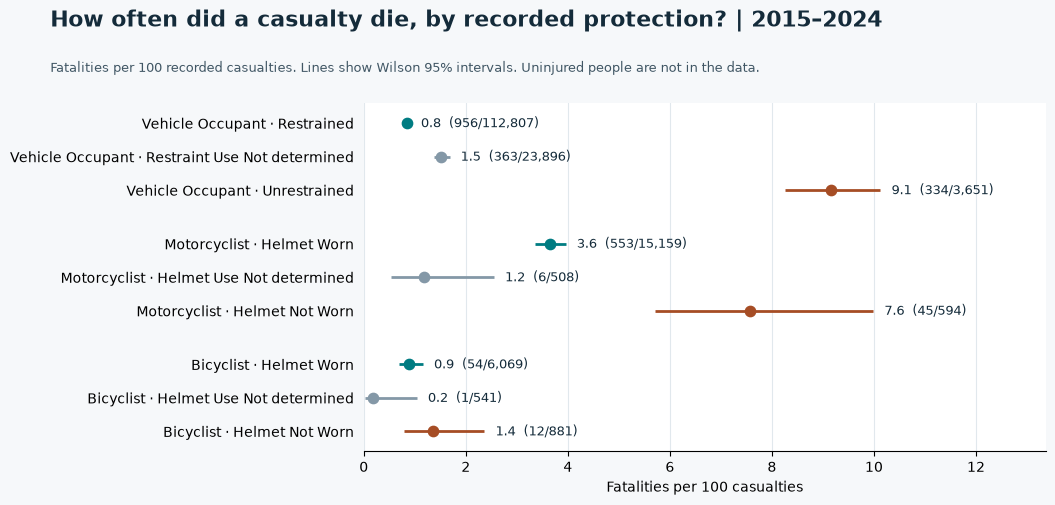

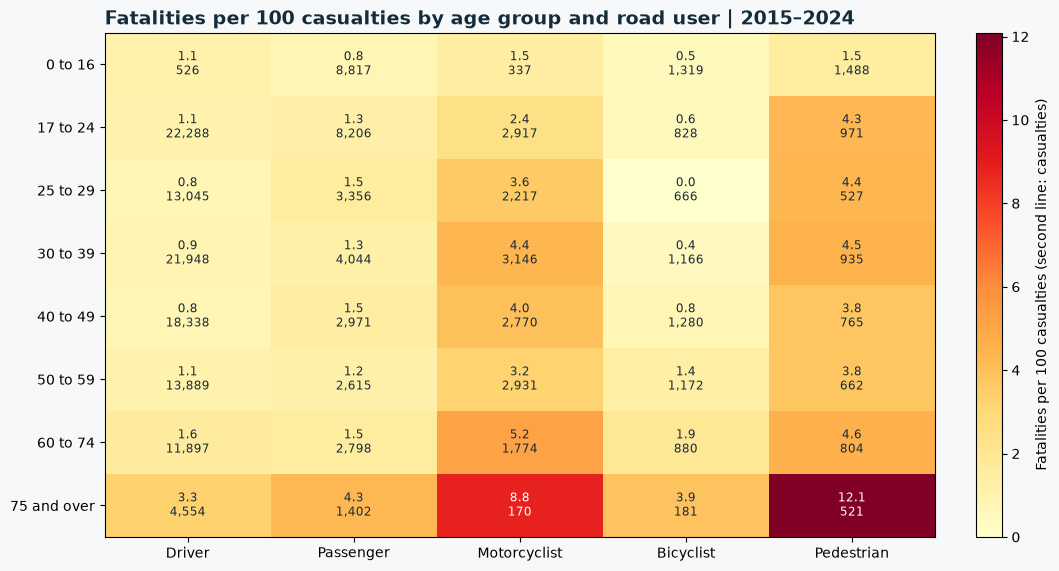

Pedestrians aged 75 and over: 12.1 fatalities per 100 casualties (63/521). Pedestrians aged 17–74: 4.2.


In [22]:
rate_years = complete_years[-10:]
rate_period = f'{rate_years.min()}–{rate_years.max()}'


# Casualties, fatalities and fatalities per 100 casualties with a Wilson interval, for the given grouping.
def fatality_rates(frame, keys):
    counts = frame.assign(Fatalities=frame['Casualty_Count'].where(frame['Casualty_Severity'].eq('Fatality'), 0)
                          ).groupby(keys)[['Casualty_Count', 'Fatalities']].sum()
    counts = counts.rename(columns={'Casualty_Count': 'Casualties'})
    low, high = wilson_interval(counts['Fatalities'], counts['Casualties'])
    return counts.assign(**{'Fatalities per 100 casualties': 100 * counts['Fatalities'] / counts['Casualties'],
                            '95% low': 100 * low, '95% high': 100 * high})


equipment_decade = equipment_source.loc[equipment_source['Crash_Year'].isin(rate_years)
                                        & equipment_source['Casualty_Restraint_Helmet_Use'].ne('Not applicable')]
equipment_rates = fatality_rates(equipment_decade, [road_user_column, 'Casualty_Restraint_Helmet_Use'])
equipment_layout = [
    ('Vehicle Occupant', 'Restrained'), ('Vehicle Occupant', 'Restraint Use Not determined'),
    ('Vehicle Occupant', 'Unrestrained'), ('Motorcyclist', 'Helmet Worn'),
    ('Motorcyclist', 'Helmet Use Not determined'), ('Motorcyclist', 'Helmet Not Worn'),
    ('Bicyclist', 'Helmet Worn'), ('Bicyclist', 'Helmet Use Not determined'), ('Bicyclist', 'Helmet Not Worn'),
]
assert set(equipment_layout) == set(equipment_rates.index)
equipment_rates = equipment_rates.loc[equipment_layout]
display(equipment_rates.round(2))
occupant_rate = equipment_rates.loc['Vehicle Occupant', 'Fatalities per 100 casualties']
rider_rate = equipment_rates.loc['Motorcyclist', 'Fatalities per 100 casualties']
print(f"Vehicle occupants: unrestrained {occupant_rate['Unrestrained']:.2f} and restrained {occupant_rate['Restrained']:.2f} "
      f"fatalities per 100 casualties, a ratio of {occupant_rate['Unrestrained'] / occupant_rate['Restrained']:.1f}. "
      f"Not determined: {occupant_rate['Restraint Use Not determined']:.2f}.")
print(f"Motorcyclists: helmet not worn {rider_rate['Helmet Not Worn']:.2f} and worn {rider_rate['Helmet Worn']:.2f}, "
      f"a ratio of {rider_rate['Helmet Not Worn'] / rider_rate['Helmet Worn']:.1f}.")

fig, ax = plt.subplots(figsize=(11, 5.2), facecolor='#f6f8fa')
fig.subplots_adjust(left=.33, right=.95, bottom=.13, top=.80)
fig.suptitle(f'How often did a casualty die, by recorded protection? | {rate_period}',
             x=.045, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.045, .86, 'Fatalities per 100 recorded casualties. Lines show Wilson 95% intervals. Uninjured people are not in the data.',
         fontsize=9.5, color='#405664')
status_colors = {'Restrained': '#007c82', 'Helmet Worn': '#007c82', 'Unrestrained': '#a64d25',
                 'Helmet Not Worn': '#a64d25'}
positions = np.arange(len(equipment_rates)) + np.repeat([0, .6, 1.2], 3)
for y, ((user, status), row) in zip(positions, equipment_rates.iterrows()):
    color = status_colors.get(status, '#8498a7')
    ax.hlines(y, row['95% low'], row['95% high'], color=color, linewidth=2)
    ax.scatter(row['Fatalities per 100 casualties'], y, color=color, s=55, zorder=3)
    ax.annotate(f"{row['Fatalities per 100 casualties']:.1f}  ({int(row['Fatalities']):,}/{int(row['Casualties']):,})",
                (row['95% high'], y), xytext=(8, 0), textcoords='offset points', va='center', fontsize=9,
                color='#142b3a')
ax.set(yticks=positions, yticklabels=[f'{user} · {status}' for user, status in equipment_rates.index],
       ylim=(positions.max() + .6, -.6), xlim=(0, equipment_rates['95% high'].max() * 1.32),
       xlabel='Fatalities per 100 casualties')
ax.grid(axis='x', color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0, pad=7)
plt.show()

age_order = ['0 to 16', '17 to 24', '25 to 29', '30 to 39', '40 to 49', '50 to 59', '60 to 74', '75 and over']
user_order = ['Driver', 'Passenger', 'Motorcyclist', 'Bicyclist', 'Pedestrian']
casualty_decade = casualty_source.loc[casualty_source['Crash_Year'].isin(rate_years)]
age_rates = fatality_rates(casualty_decade, ['Casualty_AgeGroup', 'Casualty_RoadUserType'])
assert set(age_order) <= set(age_rates.index.get_level_values(0))
age_rate_grid = age_rates['Fatalities per 100 casualties'].unstack().reindex(index=age_order, columns=user_order)
age_count_grid = age_rates['Casualties'].unstack().reindex(index=age_order, columns=user_order).fillna(0).astype(int)
# Blank any cell with fewer than 100 casualties.
age_rate_grid = age_rate_grid.where(age_count_grid.ge(100))
fig, ax = plt.subplots(figsize=(10.5, 5.6), layout='constrained', facecolor='#f6f8fa')
image = ax.imshow(age_rate_grid, cmap='YlOrRd', aspect='auto')
ax.set(xticks=range(len(user_order)), xticklabels=user_order, yticks=range(len(age_order)), yticklabels=age_order)
ax.set_title(f'Fatalities per 100 casualties by age group and road user | {rate_period}', loc='left',
             fontsize=14, fontweight='bold', color='#142b3a')
for row, col in np.ndindex(age_rate_grid.shape):
    value, count = age_rate_grid.iat[row, col], age_count_grid.iat[row, col]
    label = f'{value:.1f}\n{count:,}' if np.isfinite(value) else 'n<100'
    ax.text(col, row, label, ha='center', va='center', fontsize=8.5,
            color='white' if np.isfinite(value) and value > 6 else '#172b38')
fig.colorbar(image, ax=ax, label='Fatalities per 100 casualties (second line: casualties)')
plt.show()
oldest_walkers = age_rates.loc[('75 and over', 'Pedestrian')]
other_adult_walkers = age_rates.loc[[(age, 'Pedestrian') for age in age_order[1:-1]]].sum()
print(f"Pedestrians aged 75 and over: {oldest_walkers['Fatalities per 100 casualties']:.1f} fatalities per 100 casualties "
      f"({int(oldest_walkers['Fatalities'])}/{int(oldest_walkers['Casualties'])}). Pedestrians aged 17–74: "
      f"{100 * other_adult_walkers['Fatalities'] / other_adult_walkers['Casualties']:.1f}.")

**What this achieved.** For 2015–2024, unrestrained vehicle occupants had 9.15 fatalities per 100 casualties (334 of 3,651) and restrained occupants 0.85 (956 of 112,807), a ratio of 10.8. Occupants whose restraint use was not determined had 1.52 per 100, higher than restrained occupants, so an analysis limited to known status leaves out a group with worse outcomes. Motorcyclists without a helmet had 7.58 per 100 compared with 3.65 with one. Pedestrians aged 75 and over had 12.1 fatalities per 100 casualties (63 of 521), compared with 4.2 for pedestrians aged 17–74.

##### Charts and Esri maps for the flat file

These visuals use the latest five complete years. The seatbelt chart and bubble map use **vehicle-occupant casualties with known seatbelt status**. The weather chart and shaded police-region map describe **fatalities among all people**. The maps display the 2026 QPS boundary layer for the named police regions.

**In this cell.** Draw paired bars for known-status seatbelt non-use among all and fatal occupant casualties. Plot weather conditions as bubbles, with recorded crash volume on the horizontal axis and fatalities represented by bubble area. Add an exact Poisson 95% interval to each weather rate so the conditions with few fatalities can be read with their uncertainty.

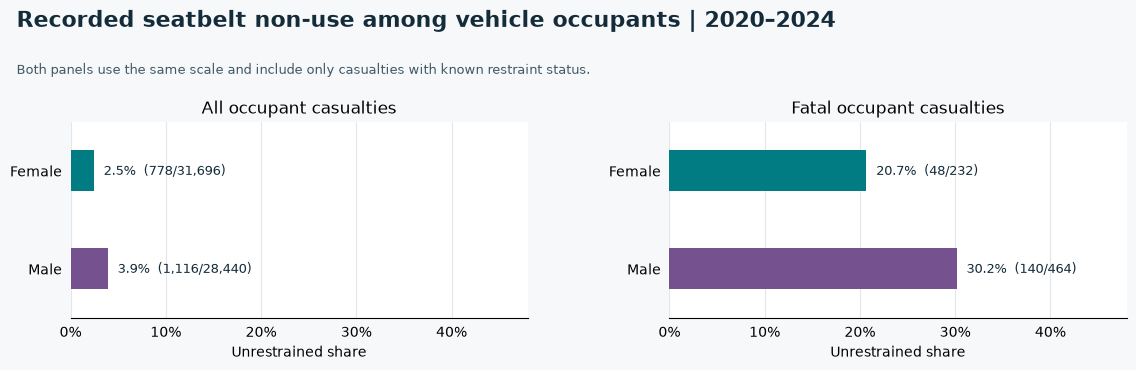

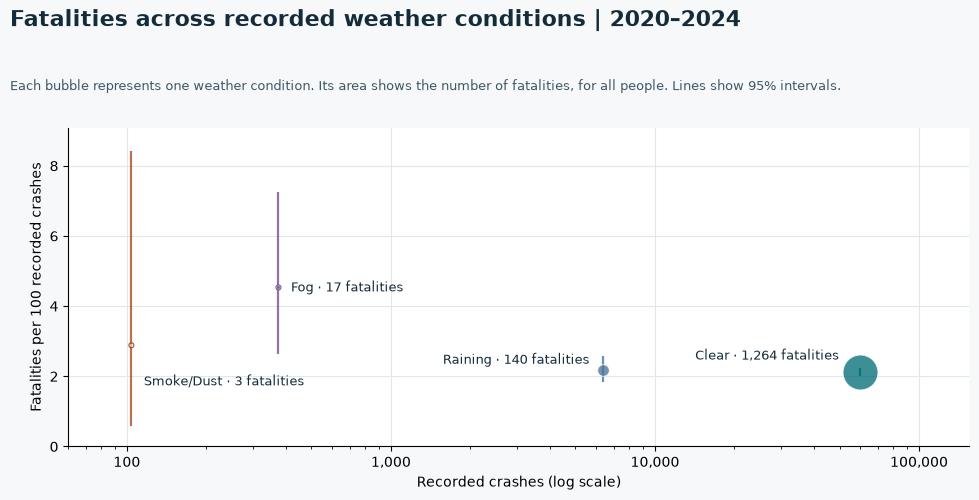

,95% low,95% high
Fatalities per 100 recorded crashes,,
Clear,2.00,2.23
Fog,2.64,7.26
Raining,1.85,2.59
Smoke/Dust,0.59,8.43


In [23]:
# Use the flat-file aggregates and pool counts before deriving shares.
context_period = f'{recent_years.min()}–{recent_years.max()}'
belt_chart = pd.DataFrame(belt_examples).set_index('Recorded gender')
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor='#f6f8fa')
fig.subplots_adjust(left=.10, right=.98, bottom=.21, top=.70, wspace=.31)
fig.suptitle(f'Recorded seatbelt non-use among vehicle occupants | {context_period}',
             x=.055, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.055,.82,'Both panels use the same scale and include only casualties with known restraint status.',
         fontsize=9.5,color='#405664')
for ax, percent, numerator, denominator, title in [
    (axes[0], 'Unrestrained share (%)', 'Unrestrained', 'Occupant casualties with known status',
     'All occupant casualties'),
    (axes[1], 'Unrestrained share of fatalities with known status (%)',
     'Unrestrained fatalities', 'Fatalities with known status', 'Fatal occupant casualties'),
]:
    y=np.arange(len(belt_chart))
    ax.barh(y,belt_chart[percent],height=.42,color=['#007c82','#76518f'])
    ax.set(yticks=y, yticklabels=belt_chart.index, ylim=(len(y)-.5,-.5),
           xlim=(0, 48),title=title,xlabel='Unrestrained share')
    for pos, (_, row) in enumerate(belt_chart.iterrows()):
        ax.annotate(f"{row[percent]:.1f}%  ({int(row[numerator]):,}/{int(row[denominator]):,})",
                    (row[percent],pos),xytext=(7,0),textcoords='offset points',
                    color='#142b3a',va='center',fontsize=9)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.spines[['top','right','left']].set_visible(False)
    ax.grid(axis='x',color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.tick_params(length=0,pad=6)
plt.show()

weather_chart = pd.DataFrame(weather_examples).loc[lambda d:d['Crashes'].gt(0)]
weather_palette = {'Clear':'#006d75','Raining':'#4a729b','Fog':'#76518f','Smoke/Dust':'#a64d25'}
fig, ax = plt.subplots(figsize=(10.6,5.4),facecolor='#f6f8fa')
fig.subplots_adjust(left=.11,right=.96,bottom=.17,top=.76)
fig.suptitle(f'Fatalities across recorded weather conditions | {context_period}',
             x=.055,ha='left',fontsize=16,fontweight='bold',color='#142b3a')
fig.text(.055,.83,'Each bubble represents one weather condition. Its area shows the number of fatalities, for all people. Lines show 95% intervals.',
         fontsize=9.5,color='#405664')
from scipy.stats import chi2

weather_intervals = {}
weather_offsets = {'Clear':(-15,12),'Raining':(-10,7),'Fog':(9,0),'Smoke/Dust':(9,-26)}
for row in weather_chart.to_dict('records'):
    label = row['Atmospheric condition']
    x, y = row['Crashes'], row['Fatalities per 100 recorded crashes']
    color = weather_palette[label]
    deaths = row['Fatalities, all people']
    # Exact Poisson 95% interval for the count of fatalities, expressed per 100 crashes.
    interval_low = 100 * (chi2.ppf(.025, 2 * deaths) / 2 if deaths else 0) / x
    interval_high = 100 * chi2.ppf(.975, 2 * (deaths + 1)) / 2 / x
    weather_intervals[label] = (interval_low, interval_high)
    ax.vlines(x, interval_low, interval_high, color=color, linewidth=1.6, alpha=.8, zorder=3)
    ax.scatter(x, y, s=row['Fatalities, all people']/2, color=color, alpha=.77,
               edgecolor='white', linewidth=.7, zorder=4)
    if row['Fatalities, all people'] < 20:
        ax.scatter(x, y, s=13, facecolor='none', edgecolor=color, linewidth=.75, zorder=5)
    dx, dy = weather_offsets[label]
    ax.annotate(f"{label} · {row['Fatalities, all people']:,} fatalities", (x,y), xytext=(dx,dy),
                textcoords='offset points', ha='right' if dx<0 else 'left', va='center',
                fontsize=9, color='#142b3a')
ax.set(xscale='log', xlim=(60,155000), 
       xlabel='Recorded crashes (log scale)',ylabel='Fatalities per 100 recorded crashes')
ax.set_ylim(0, max(high for _, high in weather_intervals.values()) + .65)
ax.xaxis.set_major_locator(mticker.FixedLocator([100,1000,10000,100000]))
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.grid(color='#e1e8ed')
ax.set_axisbelow(True)
ax.spines[['top','right']].set_visible(False)
plt.show()
display(pd.DataFrame(weather_intervals, index=['95% low', '95% high']).T.round(2)
        .rename_axis('Fatalities per 100 recorded crashes'))

**What this achieved.** Plotted known-status restraint shares for all and fatal occupant casualties and compared all-person fatality counts and rates by weather. The fog rate rests on 17 fatalities and has a 95% interval of 2.6 to 7.3 fatalities per 100 crashes, which sits just above the intervals for clear conditions (2.0–2.2) and rain (1.9–2.6). Smoke or dust has 3 fatalities and an interval of 0.6 to 8.4, which supports no conclusion.

##### Map restraint and weather patterns by region

**In this cell.** Build two Esri maps using police-region boundaries and pooled counts. Size the restraint bubbles by the number of female occupant casualties with known status, and shade regions in the weather map by the share of all fatalities recorded in rain.

In [24]:
import folium
from branca.colormap import LinearColormap
from html import escape as escape_map_text
from shapely.geometry import mapping

# Pool the window by police region and leave out the Unknown region.
context_regions = context_recent.groupby(level='Police_Region').sum(min_count=1)
context_regions = context_regions.loc[context_regions.index != 'Unknown']
context_regions['female_known'] = context_regions['seatbelt_female_restrained'] + context_regions['seatbelt_female_unrestrained']
context_regions['female_unrestrained_share'] = (
    context_regions['seatbelt_female_unrestrained']
    .div(context_regions['female_known'].where(context_regions['female_known'].gt(0))).mul(100)
)
context_regions['rain_fatality_share'] = (
    context_regions['weather_raining_fatalities']
    .div(context_regions['weather_total_fatalities'].where(context_regions['weather_total_fatalities'].gt(0))).mul(100)
)

# Merge the police-region polygons and simplify them for display.
region_shapes = {}
for (region,), geometry in shapefile_polygons(SPATIAL_DIR / 'police.zip', ('REGION',)):
    region_shapes.setdefault(region.title(), []).append(geometry)
region_shapes = {
    region: union_all(parts).simplify(.008, preserve_topology=True)
    for region, parts in region_shapes.items() if region in context_regions.index
}
assert set(region_shapes) == set(context_regions.index)


# Esri basemap with a small title panel.
def context_esri_map(title, detail):
    view = folium.Map(location=[-22.6, 146.8], zoom_start=5, tiles='Esri.WorldStreetMap',
                      control_scale=True)
    header = folium.Element(
        '<div style="position:absolute;top:12px;left:52px;z-index:1000;max-width:340px;'
        'padding:8px 11px;background:#fbfdff;color:#173347;'
        'border:1px solid #b9c9d5;border-radius:5px;box-shadow:0 1px 4px #33445550;font-size:12px">'
        f'<strong>{escape_map_text(title)}</strong><br>{escape_map_text(detail)}</div>'
    )
    view.get_root().html.add_child(header)
    return view


belt_bubble_map = context_esri_map(
    f'Female occupant restraint records | {context_period}',
    'Bubble area shows casualties with known status. Colour shows the unrestrained share.',
)
belt_scale = LinearColormap(['#e9f3f5','#55a6aa','#056572'], vmin=0,
                            vmax=float(context_regions['female_unrestrained_share'].max()),
                            caption='% of female occupant casualties unrestrained among known status')
folium.GeoJson({
    'type':'FeatureCollection',
    'features':[{'type':'Feature','geometry':mapping(shape),'properties':{'region':region}}
                for region,shape in region_shapes.items()],
}, style_function=lambda feature: {'fillOpacity':0,'color':'#58788d','weight':1,'opacity':.65},
    name='Police regions').add_to(belt_bubble_map)
max_known = context_regions['female_known'].max()
for region, row in context_regions.iterrows():
    point = region_shapes[region].representative_point()
    rate = float(row['female_unrestrained_share'])
    label = folium.Tooltip(
        f"<b>{escape_map_text(region)}</b><br>{int(row['seatbelt_female_unrestrained']):,} of "
        f"{int(row['female_known']):,} with known status ({rate:.1f}%)"
    )
    folium.CircleMarker([point.y,point.x],radius=25*np.sqrt(row['female_known']/max_known),
                        color='#193e51',weight=1.25,fill=True,fill_color=belt_scale(rate),
                        fill_opacity=.9,tooltip=label).add_to(belt_bubble_map)
belt_scale.add_to(belt_bubble_map)
display(belt_bubble_map)

rain_region_map = context_esri_map(
    f'Fatalities recorded in rain | {context_period}',
    'Each police region is shaded by the share of all recorded fatalities that occurred in rain.',
)
rain_scale = LinearColormap(['#b8d7e8','#5486ad','#234d7c'], vmin=0,
                            vmax=float(context_regions['rain_fatality_share'].max()),
                            caption='% of fatalities recorded in rain, all people')
rain_shapes=[]
for region in context_regions.index:
    row=context_regions.loc[region]
    rate=float(row['rain_fatality_share'])
    rain_shapes.append({
        'type':'Feature','geometry':mapping(region_shapes[region]),
        'properties':{'region':region,'rain':int(row['weather_raining_fatalities']),
                      'total':int(row['weather_total_fatalities']),'percent':f'{rate:.1f}%',
                      'color':rain_scale(rate)},
    })
folium.GeoJson(
    {'type':'FeatureCollection','features':rain_shapes},
    style_function=lambda feature: {'fillColor':feature['properties']['color'],'fillOpacity':.67,
                                    'color':'#23445d','weight':1.15},
    tooltip=folium.GeoJsonTooltip(fields=['region','rain','total','percent'],
                                   aliases=['Police region','Fatalities in rain','All fatalities','Share in rain']),
).add_to(rain_region_map)
rain_scale.add_to(rain_region_map)
display(rain_region_map)

**Static pictures of the maps above.** A saved notebook may show "Make this Notebook Trusted to load map" in place of an interactive map. The pictures below show the same view from the run saved on 20 November 2026. For the interactive version, run the cell above or open `Queensland Traffic V5 - Esri Maps.html` in a browser.

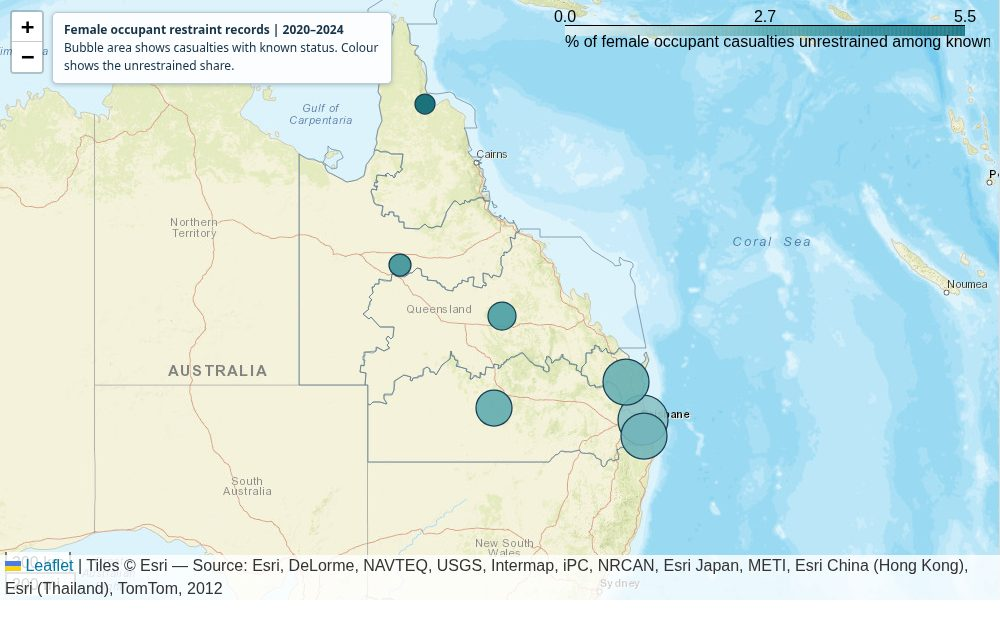

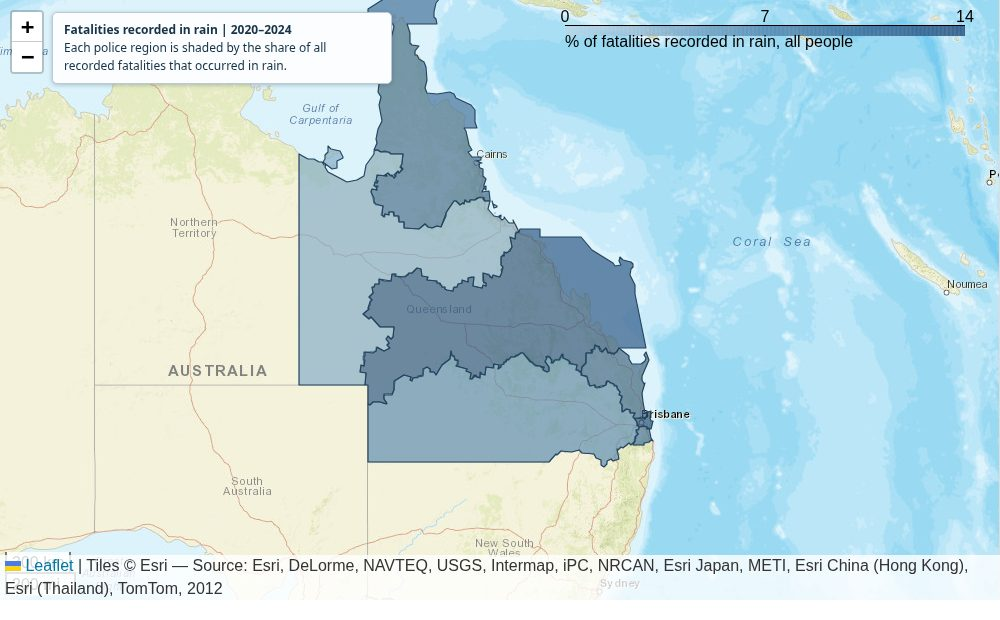

**What this achieved.** Built two interactive Esri maps for the seven named police regions. The bubble map shows female occupant restraint records. The shaded map shows the share of all recorded fatalities that occurred in rain.

#### Two- and three-level Sankey diagrams

Both diagrams cover the latest five complete reporting years. The two-level vehicle diagram assigns every injury crash with at least one of the three vehicle flags to one vehicle group, then shows its crash severity. The three-level safety diagram shows road-user type, reported restraint or helmet status, and injury severity for casualties with known equipment status. Band widths show recorded counts. Adjacent bands summarize the categories on either side of that stage.

**In this cell.** Build Sankey diagrams from weighted counts across two or three categories. Reconcile totals at each stage so the band widths reflect the counts moving between adjacent categories.

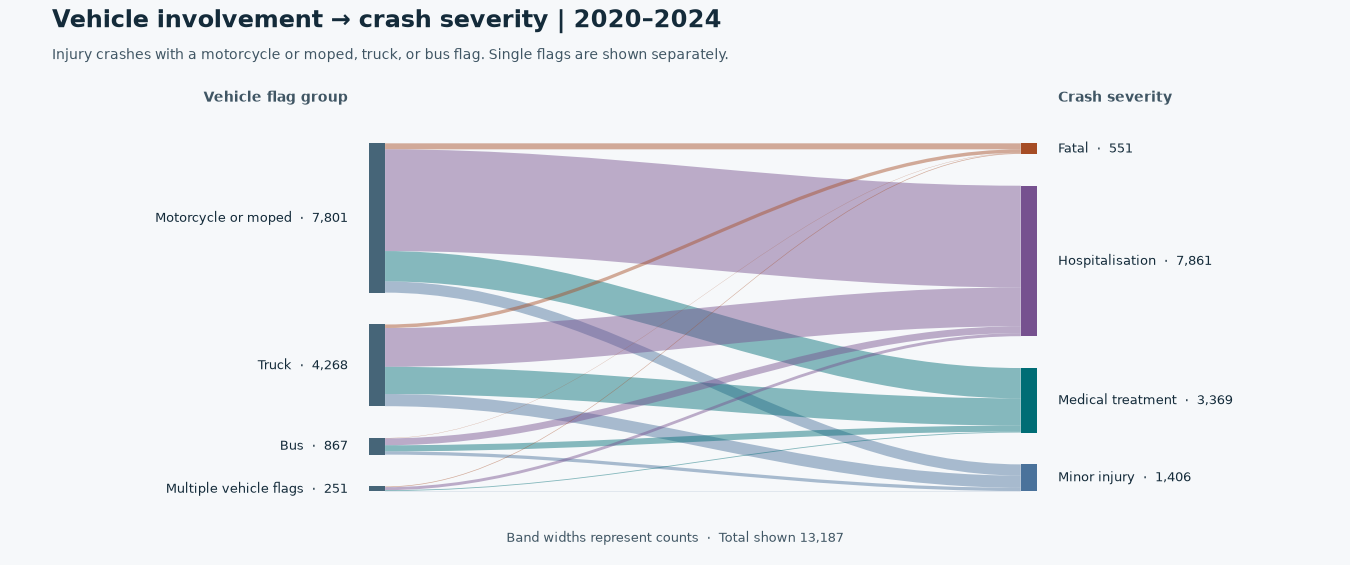

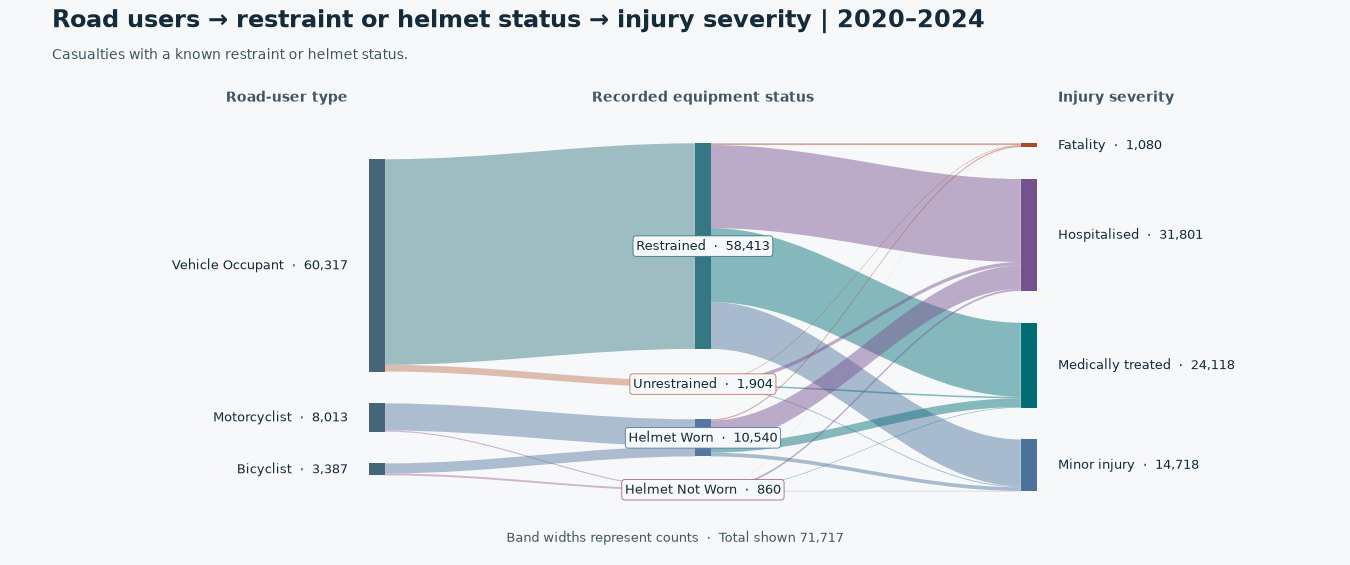

In [25]:
from matplotlib.path import Path as PlotPath
from matplotlib.patches import PathPatch, Rectangle


# Draw a two- or three-level Sankey diagram whose band widths are proportional to counts.
def count_sankey(records, levels, orders, headers, title, caption):
    assert 2 <= len(levels) <= 3
    total = int(records['Count'].sum())
    node_totals = [
        records.groupby(field)['Count'].sum().reindex(order).fillna(0).astype(int)
        for field, order in zip(levels, orders)
    ]
    node_totals = [values.loc[values.gt(0)] for values in node_totals]
    assert total > 0 and all(values.sum() == total for values in node_totals)

    outcome_colors = dict(zip(orders[-1], ['#a64d25', '#76518f', '#006d75', '#4a729b']))
    equipment_colors = dict(zip(orders[-2], ['#357884', '#c27754', '#5678a0', '#a06693']))
    stage_colors = ([{}, outcome_colors] if len(levels) == 2 else
                    [{}, equipment_colors, outcome_colors])
    gap, width = .065, .012
    height_per_record = (.71 - gap * (max(map(len, node_totals)) - 1)) / total
    xs = np.linspace(.27, .76, len(levels))

    def node_bottoms(totals):
        heights = totals * height_per_record
        occupied = heights.sum() + gap * (len(heights) - 1)
        return .485 + occupied / 2 - (heights + gap).cumsum() + gap

    bottoms = [node_bottoms(totals) for totals in node_totals]
    fig, ax = plt.subplots(figsize=(14, 5.8), facecolor='#f6f8fa')
    fig.subplots_adjust(left=.025, right=.975, bottom=.035, top=.88)
    fig.text(.055, .945, title, fontsize=17, fontweight='bold', color='#142b3a')
    fig.text(.055, .89, caption, fontsize=10, color='#405664')
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.axis('off')

    for stage, (left_field, right_field) in enumerate(zip(levels, levels[1:])):
        left_totals, right_totals = node_totals[stage:stage+2]
        links = records.pivot_table(index=left_field, columns=right_field, values='Count',
                                    aggfunc='sum', fill_value=0)
        links = links.reindex(index=left_totals.index, columns=right_totals.index, fill_value=0)
        assert links.sum(axis=1).equals(left_totals) and links.sum(axis=0).equals(right_totals)
        left_top = bottoms[stage] + left_totals * height_per_record
        right_top = bottoms[stage + 1] + right_totals * height_per_record
        x0, x1 = xs[stage] + width, xs[stage + 1]
        control0, control1 = x0 + .36 * (x1 - x0), x1 - .36 * (x1 - x0)
        for start, destinations in links.iterrows():
            for end, count in destinations.items():
                if count <= 0:
                    continue
                height = count * height_per_record
                a, b = left_top[start], right_top[end]
                vertices = [(x0, a), (control0, a), (control1, b), (x1, b),
                            (x1, b-height), (control1, b-height),
                            (control0, a-height), (x0, a-height), (x0, a)]
                path = PlotPath(vertices, [PlotPath.MOVETO, *([PlotPath.CURVE4] * 3),
                                           PlotPath.LINETO, *([PlotPath.CURVE4] * 3), PlotPath.CLOSEPOLY])
                ax.add_patch(PathPatch(path, facecolor=stage_colors[stage + 1][end],
                                       edgecolor='none', alpha=.46))
                left_top[start] -= height
                right_top[end] -= height

    for stage, (x, totals, header, colors) in enumerate(zip(xs, node_totals, headers, stage_colors)):
        align = 'right' if stage == 0 else 'left' if stage == len(levels) - 1 else 'center'
        label_x = x - .016 if align == 'right' else x + width + .016 if align == 'left' else x + width / 2
        ax.text(label_x, .925, header, ha=align, color='#405664', fontweight='bold')
        for label, count in totals.items():
            bottom = bottoms[stage][label]
            height = count * height_per_record
            ax.add_patch(Rectangle((x, bottom), width, height, facecolor=colors.get(label, '#466578')))
            box = {'facecolor': '#f6f8fa', 'edgecolor': colors.get(label, '#466578'),
                   'boxstyle': 'round,pad=.24', 'linewidth': .6} if align == 'center' else None
            ax.text(label_x, bottom + height / 2, f'{label}  ·  {count:,}',
                    ha=align, va='center', fontsize=9.5, color='#142b3a', bbox=box)
    ax.text(.5, .035, f'Band widths represent counts  ·  Total shown {total:,}',
            ha='center', va='center', fontsize=9, color='#405664')
    plt.show()


# Assign each flagged injury crash to one vehicle group so that every crash is counted once.
vehicle_groups = ['Motorcycle or moped', 'Truck', 'Bus', 'Multiple vehicle flags']
vehicle_flag_values = vehicle_recent[list(vehicle_flags.values())].eq('Yes')
flag_counts = vehicle_flag_values.sum(axis=1)
vehicle_group = pd.Series(pd.NA, dtype='string', index=vehicle_recent.index)
for label, column in vehicle_flags.items():
    vehicle_group.loc[flag_counts.eq(1) & vehicle_flag_values[column]] = label
vehicle_group.loc[flag_counts.gt(1)] = vehicle_groups[-1]
vehicle_records = (vehicle_recent.assign(Vehicle_group=vehicle_group)
                   .dropna(subset='Vehicle_group')
                   .rename(columns={'Count_Crashes': 'Count'}))
assert int(vehicle_records['Count'].sum()) == vehicle_recent.loc[flag_counts.gt(0), 'Count_Crashes'].sum()
period = f'{recent_years.min()}–{recent_years.max()}'
count_sankey(
    vehicle_records, ['Vehicle_group', 'Crash_Severity'], [vehicle_groups, injury_labels],
    ['Vehicle flag group', 'Crash severity'],
    f'Vehicle involvement → crash severity | {period}',
    'Injury crashes with a motorcycle or moped, truck, or bus flag. Single flags are shown separately.',
)

# Casualties with a known restraint or helmet status.
restraint_categories = ['Restrained', 'Unrestrained', 'Helmet Worn', 'Helmet Not Worn']
restraint_window = safety_rows.loc[
    safety_rows['Crash_Year'].isin(recent_years)
    & safety_rows['Casualty_Restraint_Helmet_Use'].isin(restraint_categories)
].rename(columns={'Casualty_Count': 'Count'})
count_sankey(
    restraint_window, ['Casualty_Road_User_Type', 'Casualty_Restraint_Helmet_Use', 'Casualty_Severity'],
    [['Vehicle Occupant', 'Motorcyclist', 'Bicyclist'], restraint_categories,
     ['Fatality', 'Hospitalised', 'Medically treated', 'Minor injury']],
    ['Road-user type', 'Recorded equipment status', 'Injury severity'],
    f'Road users → restraint or helmet status → injury severity | {period}',
    'Casualties with a known restraint or helmet status.',
)


**What this achieved.** Plotted weighted flows from the recorded vehicle flag group to crash severity, and from road-user type through equipment status to injury severity.

##### Sankey of recorded gender, seatbelt status and injury severity

Flow widths use observed casualty counts for vehicle occupants with known restraint status. The restraint file directly records all three variables. The road casualties file reconciles the totals at a shared demographic level. Driver flags, crash factors, and weather remain year-and-region context.

**In this cell.** Filter to vehicle-occupant casualties with a known restraint status. Reconcile the female and male totals against the flat file, then plot flows from recorded gender through belt status to injury severity.

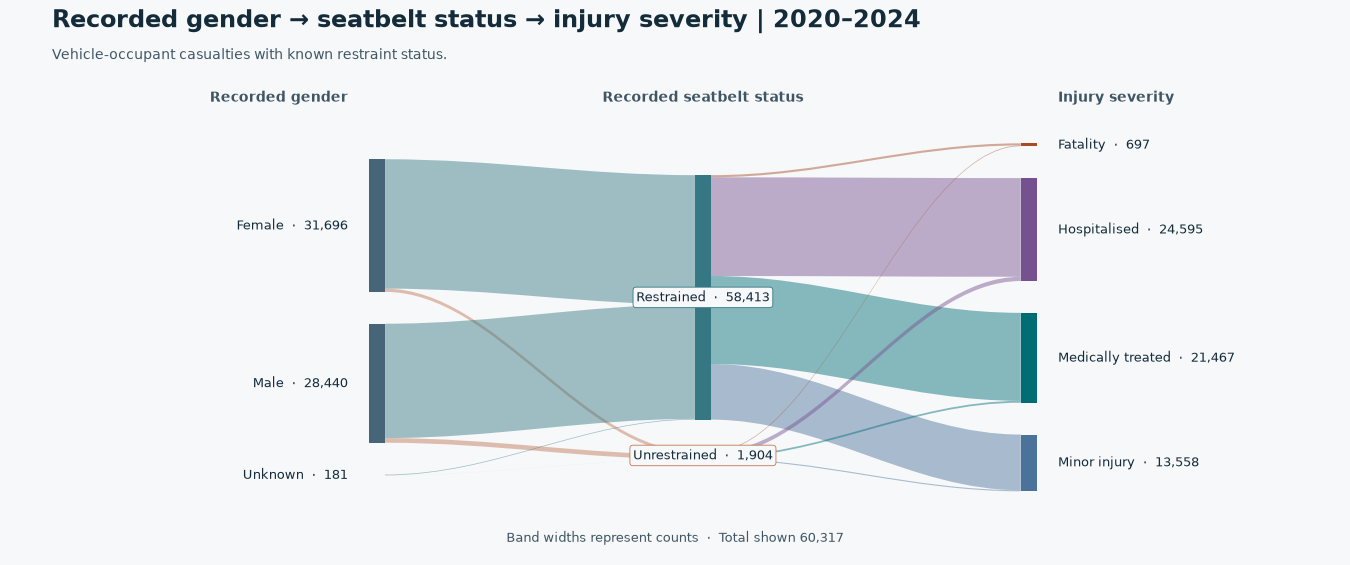

In [26]:
# Vehicle occupants with a known seatbelt status in the comparison window.
belt_sankey_records = equipment_source.loc[
    equipment_source['Crash_Year'].isin(recent_years)
    & equipment_source[road_user_column].eq('Vehicle Occupant')
    & equipment_source['Casualty_Restraint_Helmet_Use'].isin(['Restrained','Unrestrained'])
].rename(columns={'Casualty_Count':'Count'})
belt_record_counts = belt_sankey_records.groupby('Casualty_Gender')['Count'].sum()
assert belt_record_counts['Female'] == context_totals['seatbelt_female_restrained'] + context_totals['seatbelt_female_unrestrained']
assert belt_record_counts['Male'] == context_totals['seatbelt_male_restrained'] + context_totals['seatbelt_male_unrestrained']
count_sankey(
    belt_sankey_records, ['Casualty_Gender','Casualty_Restraint_Helmet_Use','Casualty_Severity'],
    [['Female','Male','Unknown'],['Restrained','Unrestrained'],
     ['Fatality','Hospitalised','Medically treated','Minor injury']],
    ['Recorded gender','Recorded seatbelt status','Injury severity'],
    f'Recorded gender → seatbelt status → injury severity | {context_period}',
    'Vehicle-occupant casualties with known restraint status.',
)

**What this achieved.** Plotted recorded gender, known seatbelt status and injury severity together using occupant casualty counts. The female and male totals agree with the flat-file values.

#### Treemaps of crash counts and severity

Each outlined group contains smaller tiles for the severity categories. Areas are proportional to recorded injury crash counts and colours identify severity. The regional treemap shows the named police regions. The vehicle treemap shows crashes with at least one motorcycle or moped, truck, or bus flag. Single-flag crashes and crashes with multiple flags occupy separate groups.

**In this cell.** Lay out nested treemap tiles proportional to recorded injury crash counts. Group tiles by police region or vehicle flag group, with severity shown by colour.

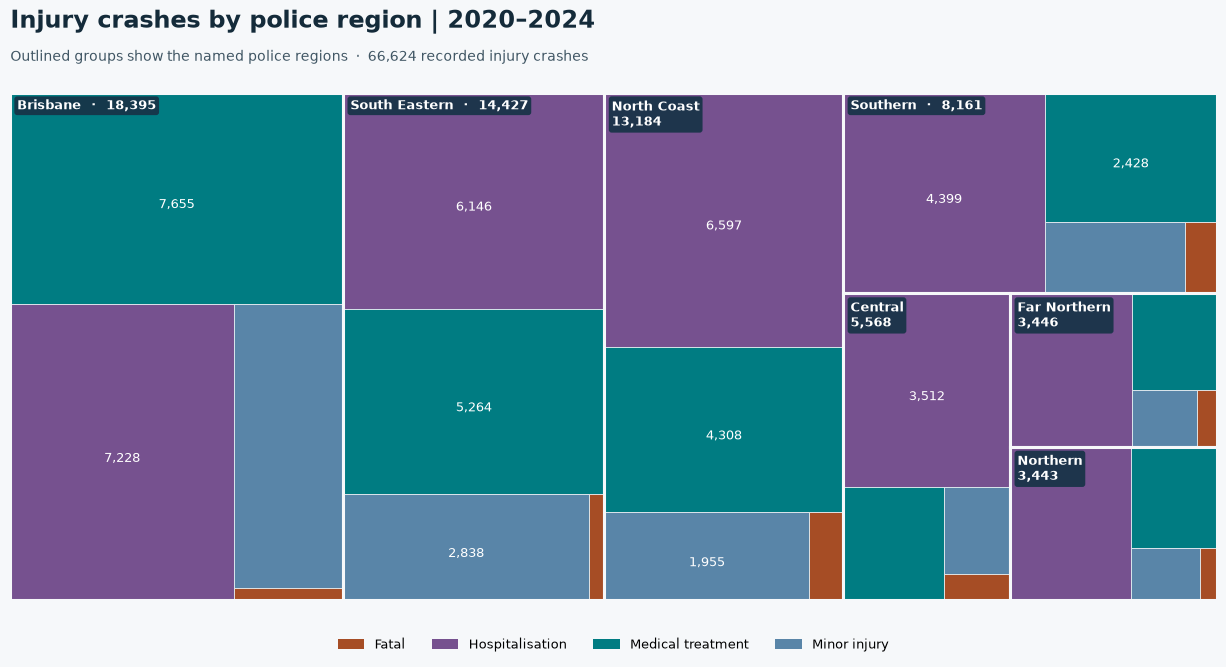

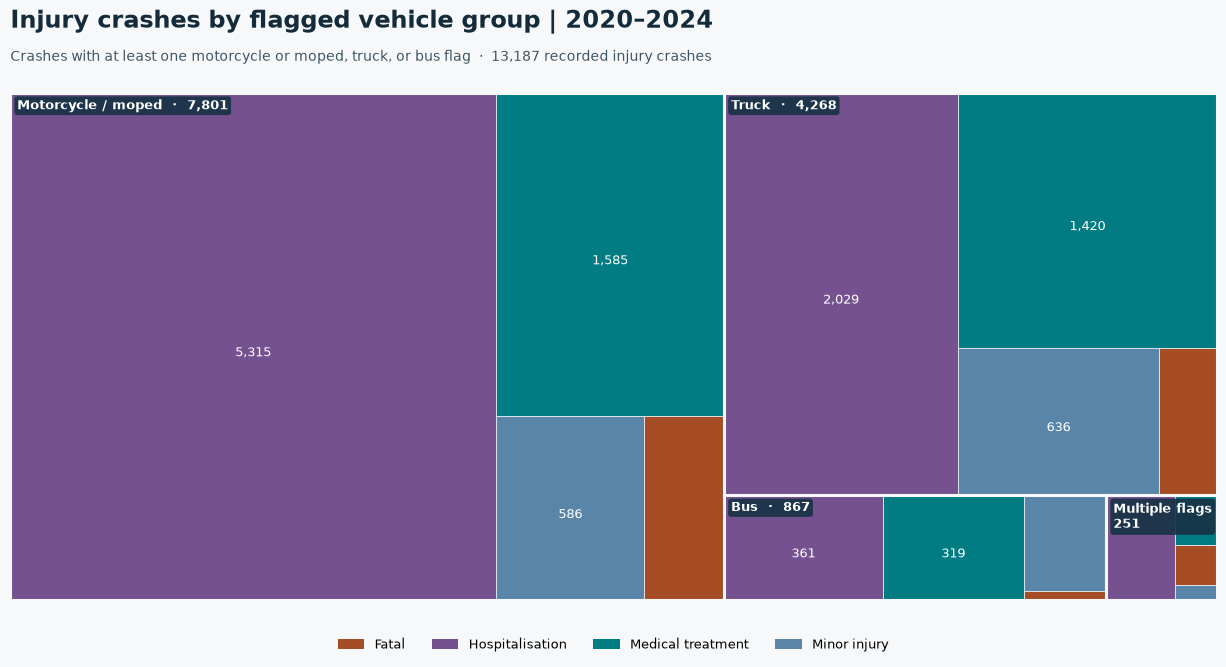

In [27]:
from matplotlib.patches import Patch


# Recursively split a rectangle into tiles with areas proportional to the counts.
def area_tiles(groups, x, y, width, height):
    # Split the larger dimension in proportion to recorded counts.
    if len(groups) == 1:
        yield groups[0][0], x, y, width, height
        return
    values = np.array([count for _, count in groups])
    total = values.sum()
    split = int(np.abs(values.cumsum()[:-1] - total / 2).argmin()) + 1
    fraction = values[:split].sum() / total
    if width >= height:
        edge = width * fraction
        yield from area_tiles(groups[:split], x, y, edge, height)
        yield from area_tiles(groups[split:], x + edge, y, width - edge, height)
    else:
        edge = height * fraction
        yield from area_tiles(groups[:split], x, y + height - edge, width, edge)
        yield from area_tiles(groups[split:], x, y, width, height - edge)


# Draw a nested treemap: one outlined group per category, with a tile per severity level.
def count_treemap(counts, title, subtitle):
    colors = {'Fatal': '#a64d25', 'Hospitalisation': '#76518f',
              'Medical treatment': '#007c82', 'Minor injury': '#5985a8'}
    totals = counts.sum(axis=1)
    groups = totals.loc[totals.gt(0)].sort_values(ascending=False)
    assert len(groups) and counts.ge(0).all(axis=None)
    total = int(groups.sum())
    width, height = 12.6, 5.3
    fig, ax = plt.subplots(figsize=(13.4, 7.05), facecolor='#f6f8fa')
    fig.subplots_adjust(left=.035, right=.965, bottom=.135, top=.855)
    fig.text(.05, .947, title, fontsize=17, fontweight='bold', color='#142b3a')
    fig.text(.05, .9, f'{subtitle}  ·  {total:,} recorded injury crashes',
             fontsize=10, color='#405664')
    ax.set(xlim=(0, width), ylim=(0, height), aspect='equal')
    ax.axis('off')
    outer_area = 0
    for group, x, y, group_width, group_height in area_tiles(list(groups.items()), 0, 0, width, height):
        outer_area += group_width * group_height
        values = counts.loc[group].loc[lambda row: row.gt(0)].sort_values(ascending=False)
        assert np.isclose(group_width * group_height, width * height * groups[group] / total)
        for severity_label, sx, sy, sw, sh in area_tiles(list(values.items()), x, y, group_width, group_height):
            assert np.isclose(sw * sh, width * height * values[severity_label] / total)
            ax.add_patch(Rectangle((sx, sy), sw, sh, facecolor=colors[severity_label],
                                   edgecolor='#e4edf1', linewidth=.6))
            if sw >= 1.30 and sh >= .85:
                ax.text(sx + sw / 2, sy + sh / 2 - .07, f'{values[severity_label]:,}',
                        color='white', ha='center', va='center', fontsize=9)
        ax.add_patch(Rectangle((x, y), group_width, group_height, fill=False,
                               edgecolor='#f6f8fa', linewidth=2.2))
        short_names = {'Motorcycle or moped': 'Motorcycle / moped',
                       'Multiple vehicle flags': 'Multiple flags'}
        name = short_names.get(group, group)
        label = f'{name}  ·  {groups[group]:,}'
        if group_width < 2.65:
            label = f'{name}\n{groups[group]:,}'
        ax.text(x + .075, y + group_height - .07, label, ha='left', va='top',
                color='white', fontsize=9, fontweight='bold', zorder=5,
                bbox=dict(facecolor='#173347', edgecolor='none', boxstyle='round,pad=.23', alpha=.92))
    assert np.isclose(outer_area, width * height)
    fig.legend(handles=[Patch(facecolor=color, label=label) for label, color in colors.items()],
               loc='lower center', bbox_to_anchor=(.5, .045), ncols=4, frameon=False, fontsize=9.5)
    plt.show()


treemap_region = location_injury.loc[
    location_injury['Crash_Year'].isin(recent_years) & location_injury['Police_Region'].ne('Unknown')
]
region_tiles = pd.crosstab(treemap_region['Police_Region'], treemap_region['Crash_Severity'])
assert region_tiles.to_numpy().sum() == len(treemap_region)
count_treemap(region_tiles, f'Injury crashes by police region | {period}',
              'Outlined groups show the named police regions')

vehicle_tiles = vehicle_records.pivot_table(
    index='Vehicle_group', columns='Crash_Severity', values='Count', aggfunc='sum', fill_value=0,
)
assert vehicle_tiles.to_numpy().sum() == vehicle_records['Count'].sum()
count_treemap(vehicle_tiles, f'Injury crashes by flagged vehicle group | {period}',
              'Crashes with at least one motorcycle or moped, truck, or bus flag')

**What this achieved.** Built treemaps sized by injury crash counts. Tiles show the severity mix within each named police region and flagged vehicle group.

#### Associations that change when we compare like with like

These figures use 2020–2024, the latest five complete years. They compare regional patterns, crash-level combinations of lighting and road surface, and flag associations within their original source tables. These are descriptive comparisons. Travel exposure and many other differences between crashes are unavailable.

**In this cell.** Compare the pooled speed–severity correlation across region-years with the correlation of residuals after accounting for region and year using least squares. Plot both views side by side.

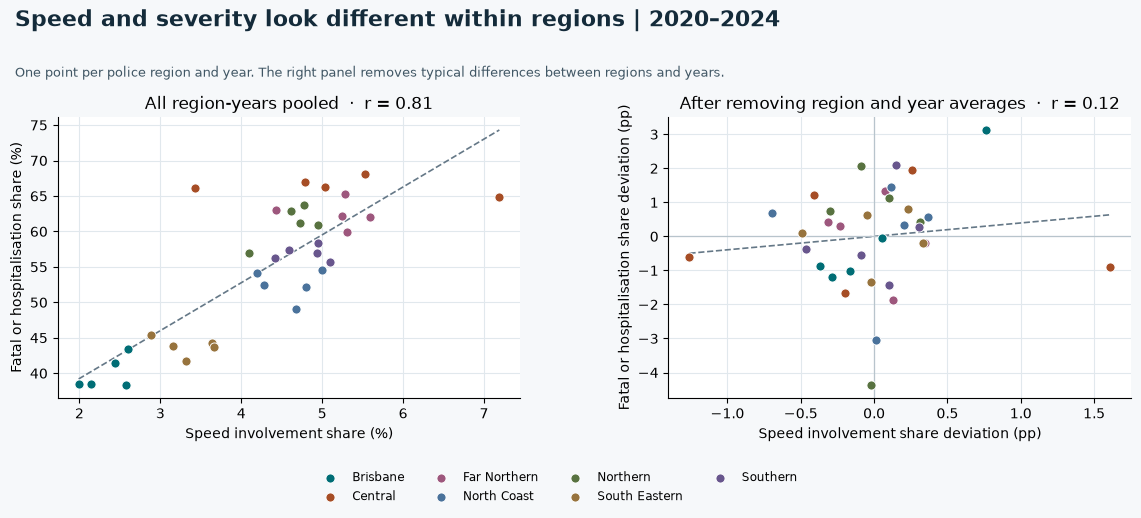

In [28]:
# Compare the pooled region-year pattern with deviations from typical region and year levels.
within_fields = ['Speed', 'Serious crash']
regional_rates = pd.DataFrame({
    label: regional_window[f'{label} numerator'].div(
        regional_window[f'{label} denominator'].where(regional_window[f'{label} denominator'].gt(0))
    ).mul(100) for label in within_fields
}).dropna().reset_index()
# Region and year indicator variables. Residuals from this fit are the within-region, within-year deviations.
indicators = pd.get_dummies(
    regional_rates[['Crash_Year', 'Police_Region']].astype(str), drop_first=True, dtype=float
)
design = np.column_stack([np.ones(len(indicators)), indicators.to_numpy()])
observed_rates = regional_rates[within_fields].to_numpy()
residual_rates = observed_rates - design @ np.linalg.lstsq(design, observed_rates, rcond=None)[0]
pooled_r = float(np.corrcoef(observed_rates.T)[0, 1])
within_r = float(np.corrcoef(residual_rates.T)[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.4), facecolor='#f6f8fa')
fig.subplots_adjust(left=.09, right=.97, bottom=.26, top=.78, wspace=.32)
fig.suptitle(f'Speed and severity look different within regions | {recent_years.min()}–{recent_years.max()}',
             x=.055, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.055, .855, 'One point per police region and year. The right panel removes typical differences between regions and years.',
         fontsize=9.5, color='#405664')
for ax, values, heading, r, suffix in [
    (axes[0], observed_rates, 'All region-years pooled', pooled_r, ' (%)'),
    (axes[1], residual_rates, 'After removing region and year averages', within_r, ' deviation (pp)'),
]:
    for region, rows in regional_rates.groupby('Police_Region'):
        positions = rows.index
        ax.scatter(values[positions, 0], values[positions, 1], s=43,
                   color=region_colors[region], edgecolor='white', linewidth=.65, label=region, zorder=3)
    x_values = np.array([values[:, 0].min(), values[:, 0].max()])
    ax.plot(x_values, np.polyval(np.polyfit(values[:, 0], values[:, 1], 1), x_values),
            linestyle='--', color='#657887', linewidth=1.2)
    ax.set(title=f'{heading}  ·  r = {r:.2f}', xlabel=f'Speed involvement share{suffix}',
           ylabel=f'Fatal or hospitalisation share{suffix}')
    ax.grid(color='#e1e8ed')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
axes[1].axhline(0, color='#b8c4cc', linewidth=.9)
axes[1].axvline(0, color='#b8c4cc', linewidth=.9)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(.5, .045),
           ncols=4, frameon=False, fontsize=8.8)
plt.show()

**What this achieved.** Compared pooled region-year speed and severity shares with their deviations after accounting for region and year. The correlation fell from 0.81 to 0.12.

##### Lighting and wet-road comparisons

**In this cell.** Use direct standardisation to compare wet and dry sealed roads under the same police-region and speed-zone mix. Show severe crash shares and the wet-minus-dry difference for each lighting condition.

Crash_Road_Surface_Condition,Sealed - Dry,Sealed - Wet,Wet − dry (pp)
Crash_Lighting_Condition,,,
Daylight,44.3,46.1,1.8
Darkness - Lighted,54.7,51.9,-2.9
Darkness - Not lighted,64.3,64.0,-0.2


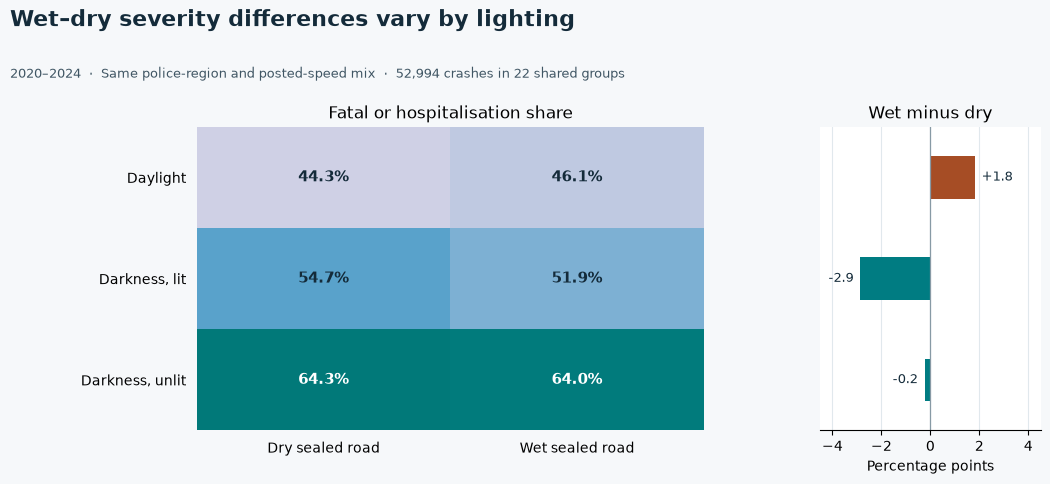

In [29]:
# Compare six lighting/surface combinations under one regional and speed-zone mix.
lights = ['Daylight', 'Darkness - Lighted', 'Darkness - Not lighted']
surfaces = ['Sealed - Dry', 'Sealed - Wet']
light_field, surface_field = 'Crash_Lighting_Condition', 'Crash_Road_Surface_Condition'
road_conditions = location_injury.loc[
    location_injury['Crash_Year'].isin(recent_years) & location_injury['Police_Region'].ne('Unknown')
    & location_injury[light_field].isin(lights) & location_injury[surface_field].isin(surfaces)
    & location_injury['Crash_Speed_Limit'].notna()
].copy()
condition_order = pd.MultiIndex.from_product([surfaces, lights], names=[surface_field, light_field])
condition_counts = road_conditions.assign(Serious=road_conditions['Crash_Severity'].isin(severe_labels)).groupby(
    ['Police_Region', 'Crash_Speed_Limit', surface_field, light_field]
)['Serious'].agg(['size', 'sum'])
counts = condition_counts['size'].unstack([surface_field, light_field]).reindex(columns=condition_order)
serious = condition_counts['sum'].unstack([surface_field, light_field]).reindex(columns=condition_order)
# Use only region and speed-zone groups with at least 10 crashes in all six lighting/surface combinations.
common = counts.ge(10).all(axis=1)
supported = counts.loc[common]
weighted_count = supported.sum(axis=1)
# Direct standardisation: weight each group by its share of all crashes in the shared groups.
weight = weighted_count / weighted_count.sum()
standardised = serious.loc[common].div(supported).mul(weight, axis=0).sum().mul(100)
standardised = standardised.unstack(surface_field).reindex(index=lights, columns=surfaces)
contrasts = standardised[surfaces[1]] - standardised[surfaces[0]]
assert standardised.notna().all(axis=None) and supported.ge(10).all(axis=None)
display(standardised.assign(**{'Wet − dry (pp)': contrasts}).round(1))

fig = plt.figure(figsize=(11.4, 4.9), facecolor='#f6f8fa')
grid = fig.add_gridspec(1, 2, width_ratios=[2.3, 1], left=.22, right=.96, bottom=.12, top=.74, wspace=.32)
ax, contrast_ax = [fig.add_subplot(grid[0, i]) for i in range(2)]
fig.suptitle('Wet–dry severity differences vary by lighting', x=.056, ha='left',
             fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.056, .84, f'{recent_years.min()}–{recent_years.max()}  ·  Same police-region and posted-speed mix  ·  '
         f'{int(weighted_count.sum()):,} crashes in {int(common.sum())} shared groups',
         fontsize=9.5, color='#405664')

values = standardised.to_numpy()
ax.imshow(values, cmap='PuBuGn', vmin=35, vmax=72, aspect='auto')
ax.set(xticks=[0, 1], xticklabels=['Dry sealed road', 'Wet sealed road'],
       yticks=range(len(lights)), yticklabels=['Daylight', 'Darkness, lit', 'Darkness, unlit'],
       title='Fatal or hospitalisation share')
for i, j in np.ndindex(values.shape):
    ax.text(j, i, f'{values[i, j]:.1f}%', ha='center', va='center',
            color='white' if values[i, j] > 58 else '#142b3a', fontweight='bold', fontsize=11)
ax.tick_params(length=0, pad=8)
ax.spines[:].set_visible(False)

contrast_ax.barh(range(len(lights)), contrasts,
                 color=np.where(contrasts >= 0, '#a64d25', '#007c82'), height=.42)
contrast_ax.axvline(0, color='#879aa5', lw=.9)
contrast_ax.set(ylim=(len(lights)-.5, -.5), yticks=[], xlim=(-4.5, 4.5),
                xlabel='Percentage points', title='Wet minus dry')
for i, value in enumerate(contrasts):
    contrast_ax.annotate(f'{value:+.1f}', (value, i), xytext=(5 if value>=0 else -5, 0),
                         textcoords='offset points', va='center', ha='left' if value>=0 else 'right',
                         color='#142b3a', fontsize=9)
contrast_ax.grid(axis='x', color='#e1e8ed')
contrast_ax.set_axisbelow(True)
contrast_ax.spines[['top','right','left']].set_visible(False)
plt.show()

**What this achieved.** Standardised wet and dry sealed-road severity shares to a common region and speed-zone mix. In unlit darkness, both shares were about 64%.

##### Matched odds of serious crash outcomes

**In this cell.** Build two-by-two tables of flag presence and serious outcomes within each year and police region. Compare pooled odds ratios with Mantel–Haenszel estimates that combine evidence across those groups. Add a 95% interval for each matched estimate using the Robins–Breslow–Greenland variance, so that an estimate can be judged against 1.

Groups compared  Pooled odds ratio  \
Source       Flag                                                      
Vehicles     Motorcycle or moped               35               2.98   
Factors      Speed                             35               3.05   
             Drink driving                     35               2.77   
Demographics Unlicensed driver                 35               1.81   
Factors      Fatigued driver                   35               1.83   
Vehicles     Truck                             35               1.15   
Demographics Young driver                      35               0.85   
Vehicles     Bus                               35               0.82   

                                  Matched-region/year odds ratio  95% low  \
Source       Flag                                                           
Vehicles     Motorcycle or moped                            3.06     2.90   
Factors      Speed                                          2.79     2.55   
             Drink driving                                  2.57     2.41   
Demographics Unlicensed driver                              1.75     1.64   
Factors      Fatigued driver                                1.60     1.44   
Vehicles     Truck                                          1.10     1.04   
Demographics Young driver                                   0.86     0.83   
Vehicles     Bus                                            0.84     0.74   

                                  95% high  Crashes with flag  
Source       Flag                                              
Vehicles     Motorcycle or moped      3.22               8022  
Factors      Speed                    3.06               2534  
             Drink driving            2.75               4938  
Demographics Unlicensed driver        1.88               4001  
Factors      Fatigued driver          1.78               1518  
Vehicles     Truck                    1.18               4482  
Demographics Young driver             0.89              21539  
Vehicles     Bus                      0.96                934

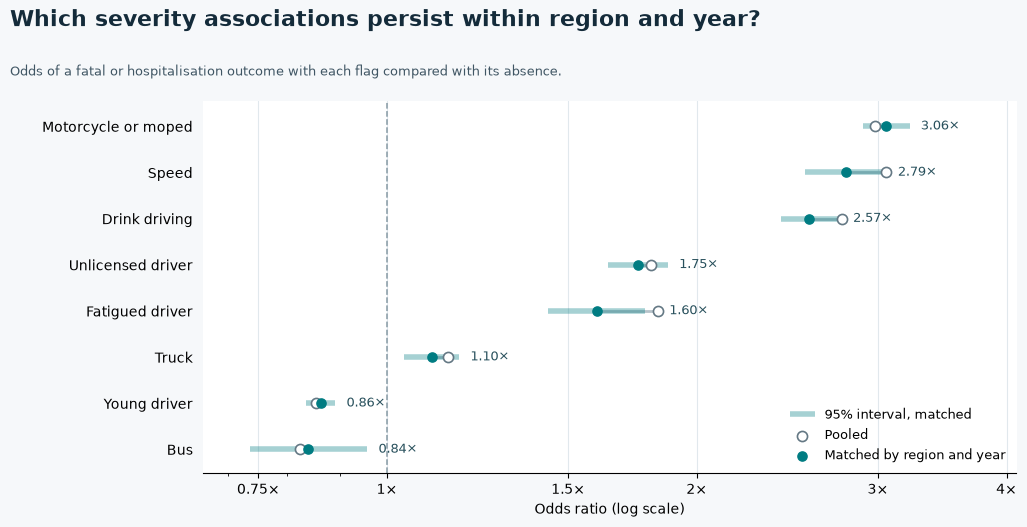

In [30]:
# Mantel–Haenszel odds ratios compare cases within the same year and police region.
association_inputs = [
    ('Factors', factor_injury, 'Involving_Driver_Speed', 'Speed'),
    ('Factors', factor_injury, 'Involving_Drink_Driving', 'Drink driving'),
    ('Factors', factor_injury, 'Involving_Fatigued_Driver', 'Fatigued driver'),
    ('Vehicles', vehicle_injury, vehicle_flags['Motorcycle or moped'], 'Motorcycle or moped'),
    ('Vehicles', vehicle_injury, vehicle_flags['Truck'], 'Truck'),
    ('Vehicles', vehicle_injury, vehicle_flags['Bus'], 'Bus'),
    ('Demographics', driver_injury, 'Involving_Young_Driver_16-24', 'Young driver'),
    ('Demographics', driver_injury, 'Involving_Unlicensed_Driver', 'Unlicensed driver'),
]
# One row of results per flag.
odds_results = []
for source_name, source, flag, label in association_inputs:
    records = source.loc[
        source['Crash_Year'].isin(recent_years) & source['Police_Region'].ne('Unknown')
        & source[flag].isin(['Yes', 'No'])
    ]
    col_order = pd.MultiIndex.from_product([['Yes', 'No'], [True, False]])
    strata = records.assign(Serious=records['Crash_Severity'].isin(severe_labels)).pivot_table(
        index=group_fields, columns=[flag, 'Serious'], values='Count_Crashes', aggfunc='sum', fill_value=0,
    ).reindex(columns=col_order, fill_value=0)
    # a, b: flag present with a serious / not serious outcome. c, d: flag absent.
    a, b, c, d = strata.to_numpy(dtype=float).T
    # Keep strata in which both the flag and the outcome vary.
    usable = ((a+b)>0) & ((c+d)>0) & ((a+c)>0) & ((b+d)>0)
    totals = (a+b+c+d)[usable]
    a,b,c,d = a[usable],b[usable],c[usable],d[usable]
    adjusted_denominator = np.sum(b*c/totals)
    # Robins–Breslow–Greenland variance of the log Mantel–Haenszel odds ratio.
    r_terms, s_terms = a*d/totals, b*c/totals
    p_terms, q_terms = (a+d)/totals, (b+c)/totals
    r_sum, s_sum = r_terms.sum(), s_terms.sum()
    log_variance = (np.sum(p_terms*r_terms)/(2*r_sum**2)
                    + np.sum(p_terms*s_terms + q_terms*r_terms)/(2*r_sum*s_sum)
                    + np.sum(q_terms*s_terms)/(2*s_sum**2)) if r_sum and s_sum else np.nan
    crude_denominator = b.sum()*c.sum()
    if adjusted_denominator and crude_denominator:
        odds_results.append({
            'Source': source_name, 'Flag': label, 'Groups compared': int(usable.sum()),
            'Pooled odds ratio': a.sum()*d.sum()/crude_denominator,
            'Matched-region/year odds ratio': np.sum(a*d/totals)/adjusted_denominator,
            '95% low': np.exp(np.log(r_sum/s_sum) - 1.959964*np.sqrt(log_variance)),
            '95% high': np.exp(np.log(r_sum/s_sum) + 1.959964*np.sqrt(log_variance)),
            'Crashes with flag': int((a+b).sum()),
        })

severity_odds = pd.DataFrame(odds_results).sort_values('Matched-region/year odds ratio', ascending=False)
display(severity_odds.set_index(['Source', 'Flag']).round(2))
fig, ax = plt.subplots(figsize=(11.0, 5.4), facecolor='#f6f8fa')
fig.subplots_adjust(left=.23, right=.97, bottom=.12, top=.81)
fig.suptitle('Which severity associations persist within region and year?',
             x=.055, ha='left', fontsize=16, fontweight='bold', color='#142b3a')
fig.text(.055, .857, 'Odds of a fatal or hospitalisation outcome with each flag compared with its absence.',
         fontsize=9.5, color='#405664')
order = np.arange(len(severity_odds))
crude = severity_odds['Pooled odds ratio']
adjusted = severity_odds['Matched-region/year odds ratio']
ax.axvline(1, color='#879aa5', linewidth=1.1, linestyle='--')
ax.hlines(order, np.minimum(crude, adjusted), np.maximum(crude, adjusted), color='#b7c3ca', linewidth=2)
ax.hlines(order, severity_odds['95% low'], severity_odds['95% high'], color='#007c82', linewidth=4,
          alpha=.35, label='95% interval, matched', zorder=2)
ax.scatter(crude, order, facecolor='white', edgecolor='#647884', linewidth=1.2, s=53, label='Pooled', zorder=3)
ax.scatter(adjusted, order, color='#007c82', s=44, label='Matched by region and year', zorder=4)
for y, value, pooled in zip(order, adjusted, crude):
    ax.annotate(f'{value:.2f}×', (max(value, pooled, severity_odds['95% high'].iloc[y]), y), xytext=(8, 0), textcoords='offset points',
                va='center', fontsize=9, color='#28505c')
ax.set(xscale='log', yticks=order, yticklabels=severity_odds['Flag'],
       ylim=(len(order)-.48, -.55), xlabel='Odds ratio (log scale)')
ax.set_xlim(min(.72, float(min(crude.min(), severity_odds['95% low'].min()))*.9),
            float(max(crude.max(), severity_odds['95% high'].max()))*1.27)
ax.xaxis.set_major_locator(mticker.FixedLocator([.75, 1, 1.5, 2, 3, 4]))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: f'{value:g}×'))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.grid(axis='x', color='#e1e8ed')
ax.set_axisbelow(True)
ax.legend(loc='lower right', frameon=False, fontsize=9)
ax.spines[['top','right','left']].set_visible(False)
ax.tick_params(axis='y', length=0, pad=7)
plt.show()

**What this achieved.** Compared pooled and region-year-matched odds ratios for reported flags, with 95% intervals for the matched estimates. The matched fatal-or-hospitalisation odds ratios were 3.06 (2.90–3.22) for motorcycle or moped involvement and 2.79 (2.55–3.06) for recorded speed involvement. Truck involvement was 1.10 (1.04–1.18). Young-driver involvement (0.86, 0.83–0.89) and bus involvement (0.84, 0.74–0.96) were below 1, which means injury crashes with those flags were less often serious. It does not show that the flag lowers risk. Young drivers, for example, may be involved in more lower-speed urban crashes, which the grouped source files cannot separate.

## Phase 3 · Modelling

Develop the supervised severity classifiers, the spatial hotspot search and the association rules. The classifiers use a time-ordered split. The hotspots and rules describe patterns in the recorded data.

### Train the severity classifiers

Fit three Random Forest pipelines. The first uses the original training distribution. The second applies SMOTENC to the training data. The third also applies SMOTENC and adds road-context fields that the exploration showed to be related to severity: remoteness area, crash movement group, roadway feature, horizontal and vertical alignment, and controlling authority. Comparing the second and third models shows what the extra fields contribute with everything else unchanged.

Use four injury severity classes and keep the latest three crash years for evaluation. The models use recorded crash and road conditions, with casualty outcome fields excluded. Crash nature, crash type and movement group describe the crash itself, so these models describe severity given the crash that occurred. They cannot be used before a crash happens.

**In this cell.** Train three Random Forest classifier pipelines using one-hot encoding for categorical features. Apply SMOTENC to the training data for two of them, add the road-context fields to the third, and reserve later crash years for evaluation.

In [31]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

categorical = [
    'Crash_Nature', 'Crash_Type', 'Crash_Day_Of_Week', 'Crash_Speed_Limit',
    'Crash_Lighting_Condition', 'Crash_Atmospheric_Condition',
    'Crash_Road_Surface_Condition', 'Crash_Traffic_Control',
]
road_context = [
    'Loc_ABS_Remoteness', 'Crash_DCA_Group_Description', 'Crash_Roadway_Feature',
    'Crash_Road_Horiz_Align', 'Crash_Road_Vert_Align', 'Crash_Controlling_Authority',
]
numeric = ['Crash_Hour']
target = 'Crash_Severity'
test_years = [int(year) for year in sorted(raw[YEAR].unique())[-3:]]
injury_crashes = raw.loc[raw[target].ne('Property damage only')]
train = injury_crashes.loc[~injury_crashes[YEAR].isin(test_years)]
test = injury_crashes.loc[injury_crashes[YEAR].isin(test_years)]
if len(train) > 60_000:
    train, _ = train_test_split(train, train_size=60_000, stratify=train[target], random_state=SEED)

def predictors(frame, fields=categorical):
    # Use recorded data and explicit unknown categories for the model.
    features = frame[[*numeric, *fields]].copy()
    features[fields] = features[fields].fillna('Unknown').astype(object)
    return features

X_train, X_test = predictors(train), predictors(test)
y_train, y_test = train[target], test[target]
context_model_label = 'Random Forest + SMOTENC + road context'
fitted_models, model_inputs = {}, {}
# Fit the three pipelines. Each keeps its own inputs because the third uses extra fields.
for label, resample, fields in [
    ('Random Forest', False, categorical),
    ('Random Forest + SMOTENC', True, categorical),
    (context_model_label, True, [*categorical, *road_context]),
]:
    encoder = ColumnTransformer([
        ('categories', OneHotEncoder(handle_unknown='ignore'), fields),
        ('hour', 'passthrough', numeric),
    ])
    model = Pipeline([
        ('rebalance', SMOTENC(categorical_features=fields, random_state=SEED) if resample else 'passthrough'),
        ('encode', encoder),
        ('forest', RandomForestClassifier(n_estimators=80, max_depth=15, min_samples_leaf=5,
                                          random_state=SEED, n_jobs=4)),
    ])
    model_inputs[label] = (predictors(train, fields), predictors(test, fields))
    model.fit(model_inputs[label][0], y_train)
    fitted_models[label] = model

print(f"Training rows: {len(train):,} | Test rows: {len(test):,} | Test years: {test_years}")

Training rows: 60,000 | Test rows: 35,009 | Test years: [2023, 2024, 2025]


**What this achieved.** Fitted the three classifier pipelines on 60,000 sampled training rows and held back 35,009 later records. The third pipeline adds six road-context fields to the eight crash and condition fields. The fitted pipelines are available in the session for evaluation.

### Find serious-crash hotspots and test whether they persist

Earlier versions fitted K-Means to longitude, latitude, hour and year. With year as a feature and property-damage-only crashes present only in the early years, the clusters mostly separated the early and late recording periods in south-east Queensland. This version asks a spatial question on a consistent series.

Use DBSCAN on projected coordinates to find compact groups of fatal or hospitalisation crashes. A hotspot needs at least ten serious crashes, each within 50 metres of another in the group, across the complete years after property-damage-only recording ended. Only observed coordinates are used. Counts reflect traffic volume as well as risk, so busy inner-city junctions are expected to lead the list.

A site that ranks highly in one period often ranks lower in the next, because part of a high count is chance. To show how much, count serious crashes in 200-metre grid cells for two consecutive five-year periods and follow the 100 cells that ranked highest in the first.

**In this cell.** Project observed serious-crash locations to metres and fit DBSCAN with a 50-metre neighbourhood and a minimum of ten crashes. Summarise each hotspot by its crash counts, extent and most common locality and street names, and map the largest. Then compare 200-metre grid-cell counts between two five-year periods to measure how far the highest-ranked cells fall back.

529 hotspots contain 7,273 of 83,656 serious crashes with observed coordinates (8.7%), 2011–2024. Largest extent: 222 m.


,Serious crashes,Fatal crashes,Latitude,Longitude,Suburb,Main street,Intersecting street,Police region,First year,Last year,Extent (m)
Rank,,,,,,,,,,,
1,36,0,-27.459653,153.033805,Fortitude Valley,Ann St,Gipps St,Brisbane,2011,2024,128
2,34,0,-27.458808,153.035266,Fortitude Valley,Ann St,Mclachlan St,Brisbane,2011,2024,189
3,32,1,-27.457335,153.031293,Fortitude Valley,Barry Pde,Gipps St,Brisbane,2011,2024,153
4,32,0,-16.923577,145.766870,Parramatta Park,Florence St,Mulgrave Rd,Far Northern,2011,2023,104
5,29,0,-27.885319,153.314946,Oxenford,Hope Island Rd,Pacific Hwy,South Eastern,2011,2024,208
6,27,0,-27.463069,153.035644,Fortitude Valley,Story Bridge,NaN,Brisbane,2011,2024,222
7,27,0,-27.415492,153.036642,Lutwyche,Kedron Park Rd,Lutwyche Rd,Brisbane,2011,2024,83
8,27,0,-27.363861,153.017229,Aspley,Albany Creek Sub-Arterial Rd,Robinson Rd W,Brisbane,2011,2024,82
9,27,0,-27.976763,153.380942,Ashmore,Olsen Av,Southport - Nerang Rd,South Eastern,2011,2024,91


,2015–2019 to 2020–2024
Cells with a serious crash in either period,34283.00
"Top 100 cells, earlier period: serious crashes",930.00
"Same cells, later period: serious crashes",564.00
"Same cells, later ÷ earlier",0.61
"All cells, later ÷ earlier",1.19
Earlier top 100 still in the later top 100,22.00
Earlier top cells with fewer crashes later,82.00


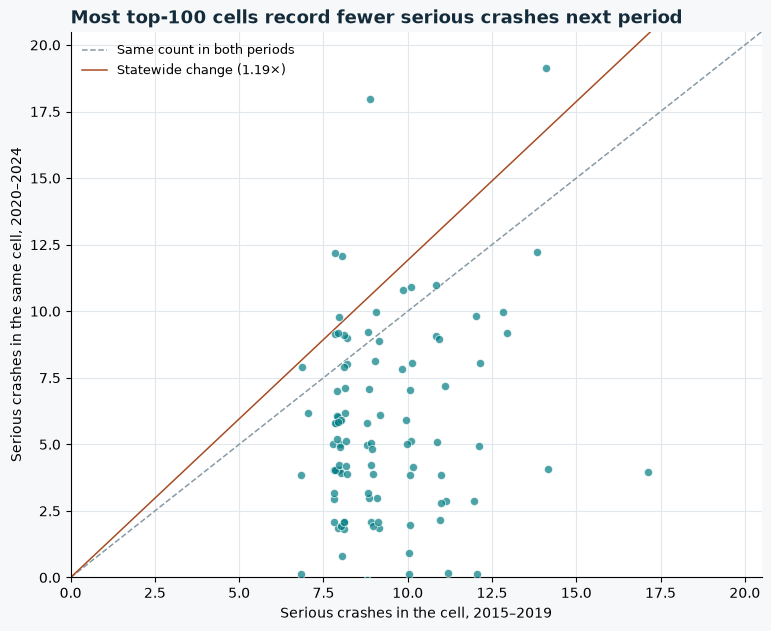

In [32]:
from sklearn.cluster import DBSCAN

# Serious crashes with observed coordinates, in complete years after property-damage recording ended.
hotspot_years = complete_years[complete_years > last_pdo_year]
serious_points = cleaned.loc[
    cleaned['Coordinate_Method'].eq('observed') & cleaned['Crash_Severity'].isin(severe_labels)
    & cleaned['Crash_Year'].isin(hotspot_years)
].dropna(subset=COORDS).copy()
serious_points['x'], serious_points['y'] = FORWARD(serious_points['Crash_Longitude'].to_numpy(),
                                                   serious_points['Crash_Latitude'].to_numpy())
HOTSPOT_RADIUS_M, HOTSPOT_MINIMUM = 50, 10
# DBSCAN labels each crash with a hotspot number, or -1 when it belongs to none.
serious_points['Hotspot'] = DBSCAN(eps=HOTSPOT_RADIUS_M, min_samples=HOTSPOT_MINIMUM).fit_predict(
    serious_points[['x', 'y']].to_numpy())


# Most frequent non-missing value, used to label a hotspot.
def most_common(values):
    values = values.dropna()
    return values.mode().iat[0] if len(values) else pd.NA


in_hotspot = serious_points.loc[serious_points['Hotspot'].ge(0)]
hotspots = in_hotspot.groupby('Hotspot').agg(
    **{'Serious crashes': ('Crash_Severity', 'size'),
       'Fatal crashes': ('Crash_Severity', lambda values: int(values.eq('Fatal').sum())),
       'Latitude': ('Crash_Latitude', 'median'), 'Longitude': ('Crash_Longitude', 'median'),
       'Suburb': ('Loc_Suburb', most_common), 'Main street': ('Crash_Street', most_common),
       'Intersecting street': ('Crash_Street_Intersecting', most_common),
       'Police region': ('Loc_Police_Region', most_common),
       'First year': ('Crash_Year', 'min'), 'Last year': ('Crash_Year', 'max')}
)
hotspot_extent = in_hotspot.groupby('Hotspot')[['x', 'y']].agg(['min', 'max'])
hotspots['Extent (m)'] = np.hypot(hotspot_extent[('x', 'max')] - hotspot_extent[('x', 'min')],
                                  hotspot_extent[('y', 'max')] - hotspot_extent[('y', 'min')]).round().astype(int)
hotspots = hotspots.sort_values(['Serious crashes', 'Fatal crashes'], ascending=False).reset_index(drop=True)
hotspots.index = pd.RangeIndex(1, len(hotspots) + 1, name='Rank')
hotspot_period = f'{int(hotspot_years.min())}–{int(hotspot_years.max())}'
print(f"{len(hotspots):,} hotspots contain {len(in_hotspot):,} of {len(serious_points):,} serious crashes "
      f"with observed coordinates ({len(in_hotspot) / len(serious_points):.1%}), {hotspot_period}. "
      f"Largest extent: {hotspots['Extent (m)'].max()} m.")
display(hotspots.head(15))

hotspot_map = folium.Map(location=[-27.47, 153.03], zoom_start=11, tiles='Esri.WorldStreetMap', control_scale=True)
for rank, row in hotspots.head(150).iterrows():
    folium.CircleMarker(
        [row['Latitude'], row['Longitude']], radius=4 + row['Serious crashes'] / 4,
        color='#9d2525' if row['Fatal crashes'] else '#db6820', weight=1.2, fill=True, fill_opacity=.6,
        tooltip=(f"#{rank} · {escape(str(row['Main street']))} / {escape(str(row['Intersecting street']))}, "
                 f"{escape(str(row['Suburb']))}: {row['Serious crashes']} serious crashes, "
                 f"{row['Fatal crashes']} fatal, {hotspot_period}"),
    ).add_to(hotspot_map)
display(hotspot_map)

# Follow the highest-ranked 200 m cells from one five-year period into the next.
CELL_M, TOP_CELLS = 200, 100
earlier_years, later_years = complete_years[-10:-5], complete_years[-5:]
assert earlier_years.min() > last_pdo_year
cell_keys = [np.floor(serious_points['x'] / CELL_M).astype(int), np.floor(serious_points['y'] / CELL_M).astype(int)]
cell_counts = pd.DataFrame({
    'Earlier': serious_points['Crash_Year'].isin(earlier_years).groupby(cell_keys).sum(),
    'Later': serious_points['Crash_Year'].isin(later_years).groupby(cell_keys).sum(),
})
cell_counts = cell_counts.loc[cell_counts.sum(axis=1).gt(0)].sort_index()
# Rank each period on its own counts only. Ties keep grid order, so the other period never decides a rank.
top_earlier = cell_counts.sort_values('Earlier', ascending=False, kind='stable').head(TOP_CELLS)
top_later = cell_counts.sort_values('Later', ascending=False, kind='stable').head(TOP_CELLS)
statewide_ratio = cell_counts['Later'].sum() / cell_counts['Earlier'].sum()
persistence = pd.Series({
    'Cells with a serious crash in either period': len(cell_counts),
    f'Top {TOP_CELLS} cells, earlier period: serious crashes': int(top_earlier['Earlier'].sum()),
    'Same cells, later period: serious crashes': int(top_earlier['Later'].sum()),
    'Same cells, later ÷ earlier': top_earlier['Later'].sum() / top_earlier['Earlier'].sum(),
    'All cells, later ÷ earlier': statewide_ratio,
    f'Earlier top {TOP_CELLS} still in the later top {TOP_CELLS}': int(top_earlier.index.isin(top_later.index).sum()),
    'Earlier top cells with fewer crashes later': int(top_earlier['Later'].lt(top_earlier['Earlier']).sum()),
})
earlier_label = f'{int(earlier_years.min())}–{int(earlier_years.max())}'
later_label = f'{int(later_years.min())}–{int(later_years.max())}'
display(persistence.to_frame(f'{earlier_label} to {later_label}').round(2))

fig, ax = plt.subplots(figsize=(7.6, 6.2), layout='constrained', facecolor='#f6f8fa')
jitter = np.random.default_rng(SEED).uniform(-.22, .22, size=(len(top_earlier), 2))
ax.scatter(top_earlier['Earlier'] + jitter[:, 0], top_earlier['Later'] + jitter[:, 1], s=34, color='#007c82',
           alpha=.7, edgecolor='white', linewidth=.6, zorder=3)
axis_limit = float(top_earlier.to_numpy().max()) + 1.5
ax.plot([0, axis_limit], [0, axis_limit], color='#879aa5', linestyle='--', linewidth=1.1, label='Same count in both periods')
ax.plot([0, axis_limit], [0, axis_limit * statewide_ratio], color='#a64d25', linewidth=1.1,
        label=f'Statewide change ({statewide_ratio:.2f}×)')
ax.set(xlim=(0, axis_limit), ylim=(0, axis_limit), xlabel=f'Serious crashes in the cell, {earlier_label}',
       ylabel=f'Serious crashes in the same cell, {later_label}')
ax.set_title(f'Most top-{TOP_CELLS} cells record fewer serious crashes next period', loc='left',
             fontsize=13, fontweight='bold', color='#142b3a')
ax.grid(color='#e1e8ed')
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

**Static picture of the map above.** A saved notebook may show "Make this Notebook Trusted to load map" in place of an interactive map. The picture below shows the same view from the run saved on 20 November 2026. For the interactive version, run the cell above or open `Queensland Traffic V5 - Esri Maps.html` in a browser.

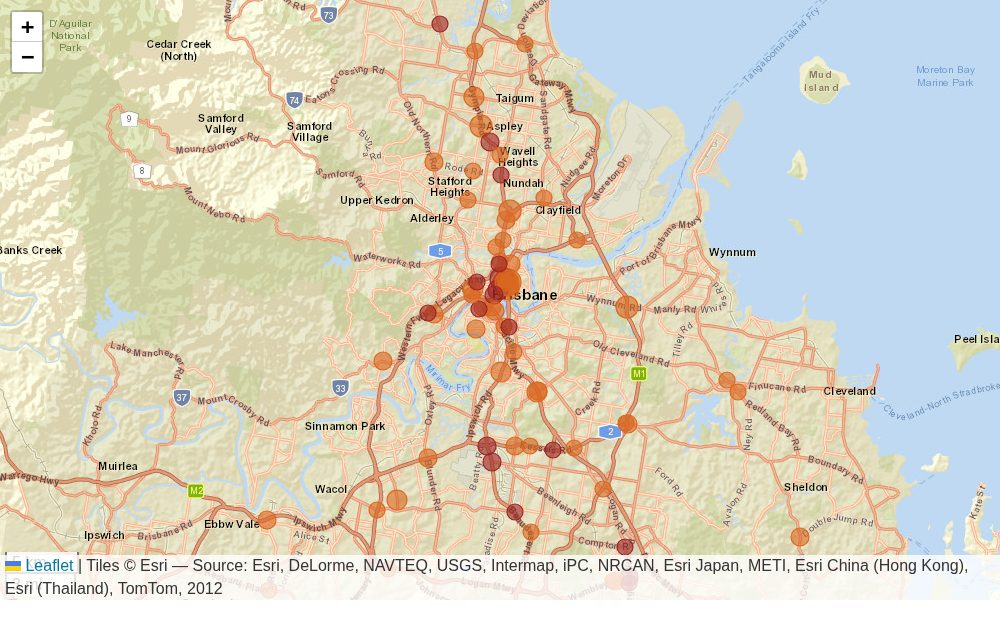

**What this achieved.** Found 529 hotspots holding 7,273 of the 83,656 serious crashes with observed coordinates in 2011–2024 (8.7%). The largest spans 222 metres. Sites around Ann Street and Barry Parade in Fortitude Valley lead the list with up to 36 serious crashes, which reflects traffic and pedestrian volume as well as risk. Of the 100 grid cells with the most serious crashes in 2015–2019, 22 were still in the top 100 in 2020–2024 and 82 recorded fewer serious crashes. Their combined count fell from 930 to 564 (0.61 times) while serious crashes across all cells rose 1.19 times. A site list built from one period overstates how many crashes the same sites will record in the next, so judge any treatment against that expected fall.

### Find combinations associated with serious outcomes

Use Apriori on injury crashes to find combinations of up to two recorded conditions that often occur with a fatal or hospitalisation outcome. The items cover crash nature, lighting, speed zone, remoteness area, roadway feature, horizontal alignment and traffic control. Require a combination and outcome to appear together in at least 0.5% of injury crashes, with at least 60% confidence, then rank by lift. Lift compares the serious share among crashes matching the rule with the serious share among all injury crashes.

Property-damage-only crashes are excluded because they are recorded only in the early years. The rules describe co-occurrence in recorded injury crashes.

**In this cell.** Encode recorded crash characteristics as indicator variables, add the serious-outcome indicator, and use Apriori to find frequent combinations. Keep rules whose consequent is the serious outcome, filter by support and confidence, and rank them by lift.

In [33]:
from mlxtend.frequent_patterns import apriori, association_rules

rule_fields = [
    'Crash_Nature', 'Crash_Lighting_Condition', 'Crash_Speed_Limit', 'Loc_ABS_Remoteness',
    'Crash_Roadway_Feature', 'Crash_Road_Horiz_Align', 'Crash_Traffic_Control',
]
serious_outcome = 'Outcome = Fatal or hospitalisation'
rule_records = cleaned.loc[cleaned['Crash_Severity'].ne('Property damage only')]
# One indicator column per field value, plus the outcome indicator in the first column.
transactions = pd.get_dummies(rule_records[rule_fields].fillna('Unknown'), prefix_sep=' = ', dtype=bool)
transactions.insert(0, serious_outcome, rule_records['Crash_Severity'].isin(severe_labels).to_numpy())
serious_baseline = transactions[serious_outcome].mean()
itemsets = apriori(transactions, min_support=.005, use_colnames=True, max_len=3, low_memory=True)
rules = association_rules(
    itemsets, num_itemsets=len(transactions), metric='confidence', min_threshold=.60
)
# Keep rules that predict the serious outcome and rank them by lift.
severity_rules = rules.loc[rules['consequents'].map(lambda items: items == frozenset({serious_outcome}))
                           ].sort_values(['lift', 'support'], ascending=False)
rule_table = severity_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(12).copy()
for column in ['antecedents', 'consequents']:
    rule_table[column] = rule_table[column].map(lambda items: ' + '.join(sorted(items)))
rule_table.insert(2, 'serious crashes', (rule_table['support'] * len(transactions)).round().astype(int))
print(f"{len(transactions):,} injury crashes | serious share {serious_baseline:.1%} | "
      f"{len(severity_rules)} rules meet the thresholds")
display(rule_table.round(3).reset_index(drop=True))

327,975 injury crashes | serious share 42.6% | 40 rules meet the thresholds


,antecedents,consequents,serious crashes,support,confidence,lift
0,Crash_Nature = Head-on + Crash_Speed_Limit = 1...,Outcome = Fatal or hospitalisation,2003,0.006,0.801,1.881
1,Crash_Nature = Head-on + Loc_ABS_Remoteness = ...,Outcome = Fatal or hospitalisation,1933,0.006,0.705,1.657
2,Crash_Nature = Head-on + Crash_Road_Horiz_Alig...,Outcome = Fatal or hospitalisation,2144,0.007,0.692,1.624
3,Crash_Nature = Head-on + Crash_Roadway_Feature...,Outcome = Fatal or hospitalisation,5186,0.016,0.687,1.614
4,Crash_Nature = Head-on + Crash_Traffic_Control...,Outcome = Fatal or hospitalisation,5945,0.018,0.675,1.585
5,Crash_Nature = Fall from vehicle + Crash_Road_...,Outcome = Fatal or hospitalisation,2153,0.007,0.672,1.578
6,Crash_Nature = Head-on + Crash_Road_Horiz_Alig...,Outcome = Fatal or hospitalisation,3143,0.010,0.671,1.577
7,Crash_Nature = Head-on,Outcome = Fatal or hospitalisation,6395,0.019,0.667,1.566
8,Crash_Lighting_Condition = Daylight + Crash_Na...,Outcome = Fatal or hospitalisation,4379,0.013,0.660,1.551
9,Crash_Nature = Fall from vehicle + Loc_ABS_Rem...,Outcome = Fatal or hospitalisation,2126,0.006,0.653,1.533


**What this achieved.** Ranked Apriori rules for serious outcomes among 327,975 injury crashes, of which 42.6% were fatal or led to hospitalisation. Forty rules met the thresholds. The leading rule linked head-on crashes in 100–110 km/h zones with a serious outcome in 80.1% of cases (2,003 serious crashes, lift 1.88). Head-on crashes appear in eight of the twelve displayed rules, and 66.7% of all head-on injury crashes were serious.

## Phase 4 · Evaluation and quality decisions

Evaluate the classifier on its held-out later records. Review the trade-off between fatal-class detection and false positives before choosing a model or threshold.

### Evaluate held-out severity predictions

Compare the three forests with a baseline that always predicts the most frequent training class. Inspect accuracy, macro F1, fatal precision, fatal recall and false alerts by test year, and review the confusion matrix. The test spans 2023–2025 and includes the partial 2025 release.

Two further views support a threshold decision. The precision–recall curve shows every trade-off between fatal recall and fatal precision that each model offers, with the default prediction marked. Average precision summarises the curve, and the share of fatal crashes in the test set is the level a random ranking would achieve. Permutation importance measures how much the fatal-class average precision falls when one input field is shuffled in the test data. Unlike impurity-based importance, it is measured on held-out records and does not favour fields with many distinct values.

**In this cell.** Score the classifiers on the held-out later years. Compare accuracy, macro F1, and fatal-class recall, then inspect the class-level report and normalised confusion matrix. Score a majority-class baseline on the same test rows. Break out fatal detections, misses and false positives for each year and identify partial reporting periods. Plot fatal-class precision–recall curves and calculate permutation importance for the road-context model on a sample of the test rows.

,Model,Test year,Coverage,Test crashes,Actual fatal crashes,Fatal predictions,Correct fatal predictions,Missed fatal crashes,False fatal alerts,Fatal precision (%),Fatal recall (%)
0,Training majority class,2023,12 months,13622,260,0,0,260,0,NaN,0.0
1,Training majority class,2024,12 months,14358,273,0,0,273,0,NaN,0.0
2,Training majority class,2025,Partial year,7029,127,0,0,127,0,NaN,0.0
3,Random Forest,2023,12 months,13622,260,0,0,260,0,NaN,0.0
4,Random Forest,2024,12 months,14358,273,0,0,273,0,NaN,0.0
5,Random Forest,2025,Partial year,7029,127,0,0,127,0,NaN,0.0
6,Random Forest + SMOTENC,2023,12 months,13622,260,2615,131,129,2484,5.0,50.4
7,Random Forest + SMOTENC,2024,12 months,14358,273,2659,132,141,2527,5.0,48.4
8,Random Forest + SMOTENC,2025,Partial year,7029,127,1215,64,63,1151,5.3,50.4
9,Random Forest + SMOTENC + road context,2023,12 months,13622,260,1738,113,147,1625,6.5,43.5


,Accuracy,Macro F1,Fatal recall,Fatal precision,Fatal average precision
Model,,,,,
Training majority class,0.318,0.121,0.000,NaN,NaN
Random Forest,0.499,0.274,0.000,NaN,0.088
Random Forest + SMOTENC,0.335,0.284,0.495,0.050,0.081
Random Forest + SMOTENC + road context,0.381,0.309,0.441,0.065,0.091


,precision,recall,f1-score,support
Crash_Severity,,,,
Hospitalisation,0.597,0.347,0.439,17202.0
Medical treatment,0.374,0.290,0.327,11126.0
Minor injury,0.223,0.367,0.277,6021.0
Fatal,0.050,0.495,0.091,660.0


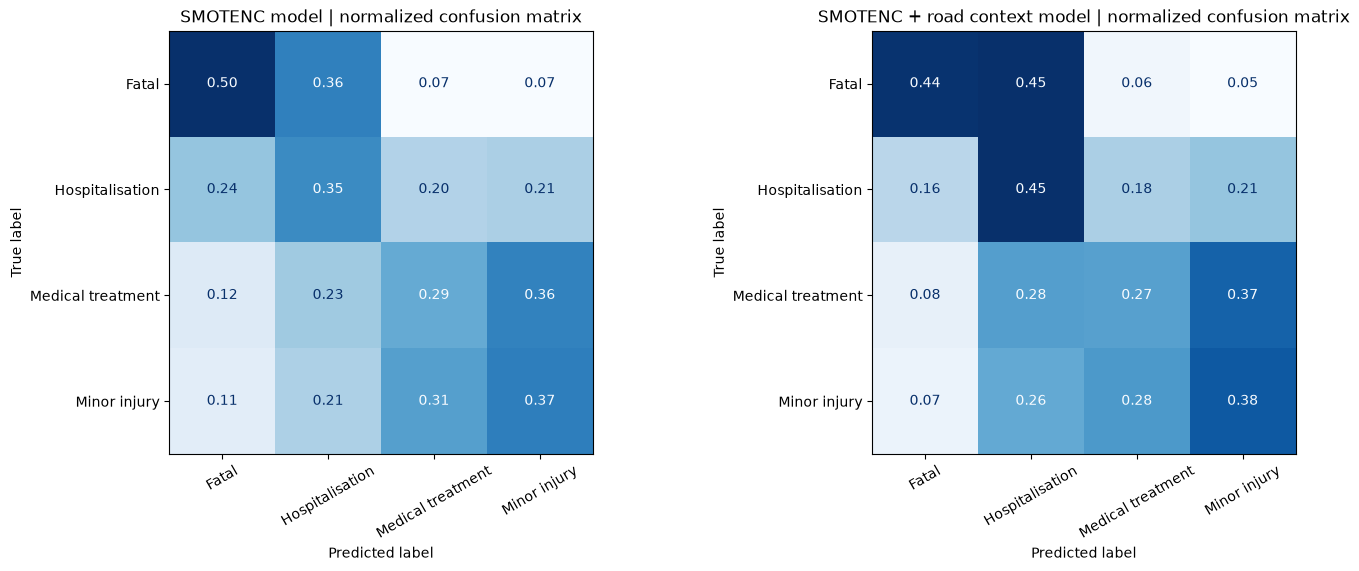

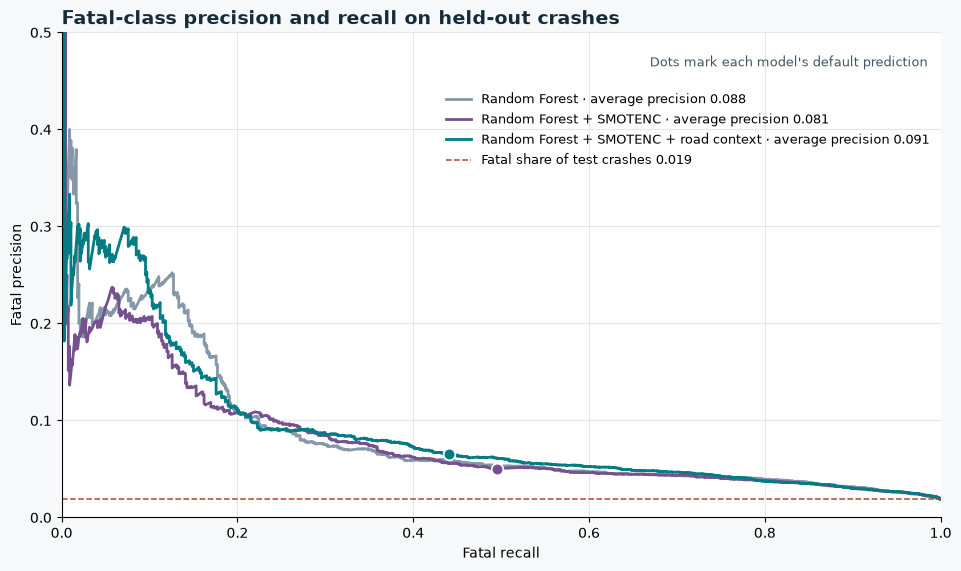

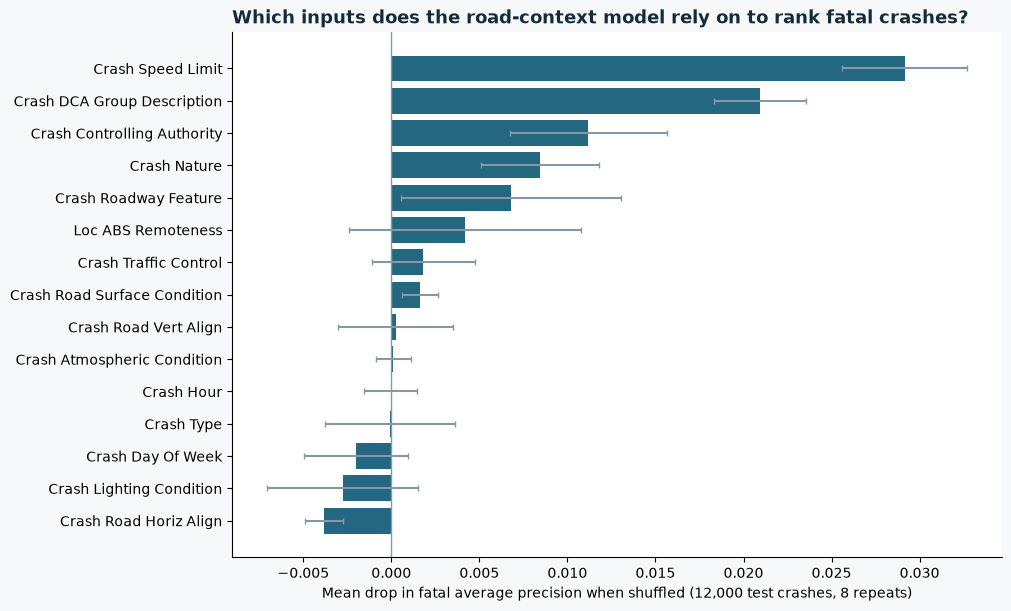

,Mean drop in fatal average precision,Standard deviation
Crash_Speed_Limit,0.0291,0.0035
Crash_DCA_Group_Description,0.0209,0.0026
Crash_Controlling_Authority,0.0112,0.0045
Crash_Nature,0.0084,0.0033
Crash_Roadway_Feature,0.0068,0.0062
Loc_ABS_Remoteness,0.0042,0.0066
Crash_Traffic_Control,0.0018,0.0029
Crash_Road_Surface_Condition,0.0016,0.0010
Crash_Road_Vert_Align,0.0003,0.0033
Crash_Atmospheric_Condition,0.0001,0.0010


In [34]:
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
                             ConfusionMatrixDisplay, f1_score, precision_recall_curve)

# Baseline that always predicts the most frequent training class.
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
evaluation_models = {'Training majority class': baseline, **fitted_models}
fatal_actual = y_test.eq('Fatal').to_numpy()
annual_model_rows = []
model_results = []
models = {}
fatal_scores = {}
for label, model in evaluation_models.items():
    test_inputs = model_inputs[label][1] if label in model_inputs else X_test
    predicted = model.predict(test_inputs)
    report = classification_report(y_test, predicted, output_dict=True, zero_division=0)
    result = {
        'Model': label, 'Accuracy': accuracy_score(y_test, predicted),
        'Macro F1': f1_score(y_test, predicted, average='macro'), 'Fatal recall': report['Fatal']['recall'],
        'Fatal precision': report['Fatal']['precision'] if (predicted == 'Fatal').any() else np.nan,
    }
    if label in fitted_models:
        fatal_scores[label] = model.predict_proba(test_inputs)[:, list(model.classes_).index('Fatal')]
        result['Fatal average precision'] = average_precision_score(fatal_actual, fatal_scores[label])
    model_results.append(result)
    models[label] = (model, predicted, report)
    for year in test_years:
        keep = test[YEAR].eq(year).to_numpy()
        actual = y_test.to_numpy()[keep]
        forecast = predicted[keep]
        fatal = actual == 'Fatal'
        alert = forecast == 'Fatal'
        hits = int((fatal & alert).sum())
        annual_model_rows.append({
            'Model': label, 'Test year': year,
            'Coverage': '12 months' if year in complete_years else 'Partial year',
            'Test crashes': len(actual), 'Actual fatal crashes': int(fatal.sum()),
            'Fatal predictions': int(alert.sum()), 'Correct fatal predictions': hits,
            'Missed fatal crashes': int(fatal.sum()) - hits,
            'False fatal alerts': int(alert.sum()) - hits,
            'Fatal precision (%)': 100 * hits / alert.sum() if alert.any() else np.nan,
            'Fatal recall (%)': 100 * hits / fatal.sum() if fatal.any() else np.nan,
        })
annual_model_audit = pd.DataFrame(annual_model_rows)
assert annual_model_audit.groupby('Model')['Test crashes'].sum().eq(len(test)).all()
display(annual_model_audit.round(1))

model_summary = pd.DataFrame(model_results).set_index('Model')
display(model_summary.round(3))
balanced_model, balanced_prediction, balanced_report = models['Random Forest + SMOTENC']
display(pd.DataFrame(balanced_report).T.reindex(y_test.value_counts().index).round(3))
context_model, context_prediction, context_report = models[context_model_label]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), layout='constrained')
for ax, prediction, title in [(axes[0], balanced_prediction, 'SMOTENC model'),
                              (axes[1], context_prediction, 'SMOTENC + road context model')]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediction, normalize='true', xticks_rotation=30,
        cmap='Blues', values_format='.2f', ax=ax, colorbar=False,
    )
    ax.set_title(f'{title} | normalized confusion matrix')
plt.show()

# Precision–recall curve for the fatal class, with each model's default prediction marked.
fatal_prevalence = fatal_actual.mean()
curve_colors = dict(zip(fitted_models, ['#8498a7', '#76518f', '#007c82']))
pr_rows = []
fig, ax = plt.subplots(figsize=(9.5, 5.6), layout='constrained', facecolor='#f6f8fa')
for label, scores in fatal_scores.items():
    precision, recall, _ = precision_recall_curve(fatal_actual, scores)
    ax.plot(recall, precision, color=curve_colors[label], linewidth=2,
            label=f"{label} · average precision {model_summary.at[label, 'Fatal average precision']:.3f}")
    operating = model_summary.loc[label]
    if np.isfinite(operating['Fatal precision']):
        ax.scatter(operating['Fatal recall'], operating['Fatal precision'], s=70, color=curve_colors[label],
                   edgecolor='white', linewidth=1.2, zorder=4)
    keep = np.unique(np.linspace(0, len(recall) - 1, 400).round().astype(int))
    pr_rows.append(pd.DataFrame({'Model': label, 'Fatal recall': recall[keep], 'Fatal precision': precision[keep]}))
ax.axhline(fatal_prevalence, color='#a64d25', linestyle='--', linewidth=1.1,
           label=f'Fatal share of test crashes {fatal_prevalence:.3f}')
ax.set(xlabel='Fatal recall', ylabel='Fatal precision', xlim=(0, 1), ylim=(0, .5))
ax.set_title('Fatal-class precision and recall on held-out crashes', loc='left', fontsize=14,
             fontweight='bold', color='#142b3a')
ax.annotate('Dots mark each model\'s default prediction', (.985, .93), xycoords='axes fraction', ha='right',
            fontsize=9, color='#405664')
ax.grid(color='#e1e8ed')
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9, loc='upper right', bbox_to_anchor=(1, .9))
ax.spines[['top', 'right']].set_visible(False)
plt.show()
pr_curves = pd.concat(pr_rows, ignore_index=True)


# Scorer for permutation importance: average precision for the fatal class.
def fatal_average_precision(estimator, features, labels):
    column = list(estimator.classes_).index('Fatal')
    return average_precision_score(np.asarray(labels) == 'Fatal', estimator.predict_proba(features)[:, column])


context_test = model_inputs[context_model_label][1]
importance_rows = context_test.sample(n=min(12_000, len(context_test)), random_state=SEED).index
permutation = permutation_importance(
    context_model, context_test.loc[importance_rows], y_test.loc[importance_rows],
    scoring=fatal_average_precision, n_repeats=8, random_state=SEED,
)
importance = pd.DataFrame({'Mean drop in fatal average precision': permutation.importances_mean,
                           'Standard deviation': permutation.importances_std},
                          index=context_test.columns).sort_values('Mean drop in fatal average precision')
fig, ax = plt.subplots(figsize=(10, 6), layout='constrained', facecolor='#f6f8fa')
ax.barh(importance.index.str.replace('_', ' '), importance['Mean drop in fatal average precision'],
        xerr=importance['Standard deviation'], color='#236780', ecolor='#8498a7', capsize=2)
ax.axvline(0, color='#879aa5', linewidth=1)
ax.set_title('Which inputs does the road-context model rely on to rank fatal crashes?', loc='left',
             fontsize=13, fontweight='bold', color='#142b3a')
ax.set_xlabel(f'Mean drop in fatal average precision when shuffled ({len(importance_rows):,} test crashes, 8 repeats)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()
display(importance.iloc[::-1].round(4))

**What this achieved.** SMOTENC increased fatal recall from 0.000 to 0.495 and macro F1 from 0.274 to 0.284. Fatal precision was 0.050, and overall accuracy fell from 0.499 to 0.335. Across the 35,009 held-out injury crashes, that model identified 327 of 660 fatal crashes and issued 6,162 false fatal alerts. Adding the road-context fields raised macro F1 to 0.309, accuracy to 0.381 and fatal precision to 0.065, with fatal recall of 0.441 (291 fatal crashes identified and 4,172 false alerts).

Fatal average precision was 0.088 without resampling, 0.081 with SMOTENC and 0.091 with SMOTENC and road context, against a fatal share of 0.019 in the test crashes. SMOTENC moved the default prediction along the curve without improving the ranking of fatal crashes. No threshold on any of the three models gives high fatal precision together with useful recall, so false alerts remain the main criterion before any operational use.

Shuffling speed zone reduced fatal average precision the most (0.029), followed by crash movement group (0.021) and controlling authority (0.011). For most other inputs the reduction was within one or two standard deviations of zero. The training-majority baseline had macro F1 of 0.121 and identified zero fatal crashes. A blank precision means that the model issued no fatal predictions for that year.

### Results at a glance

The following summaries come from the calculations above. For maps or location-sensitive analyses, use `Coordinate_Method` to select observed locations or include the estimates deliberately. For any series that crosses the end of property-damage-only recording, use injury crashes.

**In this cell.** Collect the main findings from recording checks, spatial recovery, model evaluation, association rules, hotspots, and regional comparisons into a single run summary.

In [35]:
# Headline numbers are read from variables computed above, so they cannot drift from the analysis.
print(f"Most common injury crash severity: {injury_severity.idxmax()} ({injury_severity.max():,} crashes).")
print(f"Property-damage-only crashes are recorded to {last_pdo_year} only ({severity['Property damage only']:,} records).")
print(f"Peak recorded hour for injury crashes: {hourly.sum().idxmax():02}:00.")
print(f"Crash records with both coordinates estimated: {len(targets) - cleaned.loc[targets, COORDS].isna().any(axis=1).sum():,}.")
print(f"Additional coordinate pairs estimated in the second pass: {int(second_pass.sum()):,}.")
print(f"Review-only coordinate candidates: {cleaned['Second_pass_review_latitude'].notna().sum():,}.")
print(f"Coordinate pairs still missing: {int((~available['Coordinate pair']).sum()):,}.")
print(f"Other crash attributes inferred before the public spatial match: {missing_audit.drop(index=COORDS)['Values inferred'].sum():,}.")
both_location_fields = ~recorded['Suburb'] & ~recorded['Council area'] & available['Suburb'] & available['Council area']
print(f"Crashes with both suburb and council area recovered: {both_location_fields.sum():,}.")
for result in model_results:
    print(f"{result['Model']}: macro F1 {result['Macro F1']:.3f}, fatal recall {result['Fatal recall']:.3f}"
          + (f", fatal average precision {result['Fatal average precision']:.3f}."
             if 'Fatal average precision' in result else '.'))
if not rule_table.empty:
    strongest = rule_table.iloc[0]
    print(f"Top displayed severity rule: {strongest['antecedents']} → {strongest['consequents']} "
          f"(lift {strongest['lift']:.2f}).")
print(f"All six files contribute to {regional_summary.notna().all(axis=1).sum():,} "
      f"of {len(regional_summary):,} year-and-police-region groups.")

suburb_recovered = int(cleaned['Suburb_Only_Name'].notna().sum())
print(f"Suburbs recovered separately for crashes without coordinates: {suburb_recovered:,}.")
print(f"Crashes still missing both a suburb and coordinates: {int((~available['Suburb'] & ~available['Coordinate pair']).sum()):,}.")

vehicle_fatal = vehicle_severity['Fatal share (%)'].unstack()
for kind in ['Truck', 'Motorcycle or moped']:
    involved, absent = vehicle_fatal.loc[kind, ['Involved', 'Absent']]
    print(f"{kind} fatal share among injury crashes: {involved:.1f}% with the flag and {absent:.1f}% without.")

volume_region = regional_profile['Injury crashes'].idxmax()
severity_region = regional_profile['Serious crash (%)'].idxmax()
print(f"Highest recorded injury crash volume: {volume_region} "
      f"({regional_profile.at[volume_region, 'Injury crashes']:,}).")
print(f"Highest fatal or hospitalisation share: {severity_region} "
      f"({regional_profile.at[severity_region, 'Serious crash (%)']:.1f}%).")
mix_region = region_mix['Recorded ÷ expected'].idxmax()
print(f"After allowing for remoteness and speed zone, recorded ÷ expected serious crashes ranges from "
      f"{region_mix['Recorded ÷ expected'].min():.2f} to {region_mix['Recorded ÷ expected'].max():.2f} ({mix_region}).")
print(f"Vehicle occupants, {rate_period}: {occupant_rate['Unrestrained']:.1f} fatalities per 100 unrestrained casualties "
      f"and {occupant_rate['Restrained']:.1f} per 100 restrained.")
print(f"Serious-crash hotspots, {hotspot_period}: {len(hotspots):,}, holding {len(in_hotspot):,} serious crashes.")
print(f"Of the top {TOP_CELLS} grid cells in {earlier_label}, {int(persistence.iloc[5])} were still in the top "
      f"{TOP_CELLS} in {later_label}.")

Most common injury crash severity: Hospitalisation (133,287 crashes).
Property-damage-only crashes are recorded to 2010 only (87,432 records).
Peak recorded hour for injury crashes: 15:00.
Crash records with both coordinates estimated: 127.
Additional coordinate pairs estimated in the second pass: 1.
Review-only coordinate candidates: 5.
Coordinate pairs still missing: 471.
Other crash attributes inferred before the public spatial match: 2.
Crashes with both suburb and council area recovered: 127.
Training majority class: macro F1 0.121, fatal recall 0.000.
Random Forest: macro F1 0.274, fatal recall 0.000, fatal average precision 0.088.
Random Forest + SMOTENC: macro F1 0.284, fatal recall 0.495, fatal average precision 0.081.
Random Forest + SMOTENC + road context: macro F1 0.309, fatal recall 0.441, fatal average precision 0.091.
Top displayed severity rule: Crash_Nature = Head-on + Crash_Speed_Limit = 100 - 110 km/h → Outcome = Fatal or hospitalisation (lift 1.88).
All six files co

**What this achieved.** Brought the saved data quality, descriptive and model findings together. The results support exploration and follow-up validation before any operational model decision.

## Phase 5 · Deployment readiness

The notebook and CSVs provide a local analytical release. An operational model release would need a versioned bundle with its fitted preprocessing, training configuration, dependency lock, input schema, and evaluation report. Choose the delivery mode once the intended user and decision are agreed. For a batch release, verify input/output contracts, reproduce predictions after reloading the bundle, and rehearse rollback to the previous approved version.

### Export the analysis data for Tableau and the Esri map page

The Tableau workbook reads the files written here, so every number it shows can be traced to this run. `build_tableau_workbook.py` packages them into `Queensland Traffic V5.twbx`.

- `crashes.csv` has one row per crash with readable field names. Three indicator fields make rates simple to calculate. `Injury crash` is 1 for an injury crash and 0 for a property-damage-only record. `Serious outcome` and `Fatal outcome` are 1 or 0 for injury crashes and blank for property-damage-only records, so their average is the share among injury crashes whatever filter is applied.
- `casualties.csv`, `restraints.csv`, `crash_factors.csv`, `vehicle_types.csv` and `driver_demographics.csv` hold the five grouped source tables with aligned year and police-region names and count fields ready to sum.
- The remaining files hold results that depend on a fixed period or method, such as the road-mix comparison, the matched odds ratios, the hotspots and the model evaluation. Each carries its period in the data.

The same cell rebuilds the Esri map page from the maps created in this run.

**In this cell.** Assemble the crash-level table and the grouped tables with readable names and ordered category labels. Collect the fixed-period results, write every table to `Tableau data V5/` through temporary files, and check row counts and totals against the source. Render the Folium maps into the tabbed Esri HTML page.

In [36]:
TABLEAU_DIR = DATA_DIR / 'Tableau data V5'
TABLEAU_DIR.mkdir(exist_ok=True)


def ordered_labels(values, order):
    """Prefix categories with their position so they sort in a meaningful order."""
    labels = {name: f'{position} · {name}' for position, name in enumerate(order, start=1)}
    return values.map(labels).fillna(values)


month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September',
               'October', 'November', 'December']
is_injury = cleaned['Crash_Severity'].ne('Property damage only')
# Crash-level table with readable names. Ordered labels sort correctly in Tableau without manual sorting.
tableau_crashes = pd.DataFrame({
    'Crash ref': cleaned[CRASH_ID],
    'Crash year': cleaned['Crash_Year'],
    'Complete year': np.where(cleaned['Crash_Year'].isin(complete_years), 'Complete year', 'Partial year'),
    'Recording period': np.where(cleaned['Crash_Year'].le(last_pdo_year),
                                 f'To {last_pdo_year} (property damage recorded)',
                                 f'From {last_pdo_year + 1} (injury crashes only)'),
    'Month': cleaned['Crash_Month'].map({name: f'{number:02} · {name[:3]}' for number, name in enumerate(month_order, 1)}),
    'Day of week': ordered_labels(cleaned['Crash_Day_Of_Week'], day_order),
    'Weekend': np.where(cleaned['Crash_Day_Of_Week'].isin(['Saturday', 'Sunday']), 'Weekend', 'Weekday'),
    'Hour': cleaned['Crash_Hour'],
    'Time band': np.where(cleaned['Crash_Hour'].isin(night_hours), 'Night (22:00–04:59)', 'Day and evening (05:00–21:59)'),
    'Severity': cleaned['Crash_Severity'],
    'Record type': np.where(is_injury, 'Injury crash', 'Property damage only'),
    'Crashes': 1,
    'Injury crash': is_injury.astype(int),
    'Serious outcome': cleaned['Crash_Severity'].isin(severe_labels).astype('Int64').where(is_injury),
    'Fatal outcome': cleaned['Crash_Severity'].eq('Fatal').astype('Int64').where(is_injury),
    'Crash nature': cleaned['Crash_Nature'],
    'Crash type': cleaned['Crash_Type'],
    'Movement group': cleaned['Crash_DCA_Group_Description'],
    'Police region': cleaned['Loc_Police_Region'],
    'Police district': cleaned['Loc_Police_District'],
    'Local government area': cleaned['Loc_Local_Government_Area'],
    'Suburb': cleaned['Loc_Suburb'],
    'Postcode': cleaned['Loc_Post_Code'],
    'Statistical area 2': cleaned['Loc_ABS_Statistical_Area_2'],
    'Statistical area 4': cleaned['Loc_ABS_Statistical_Area_4'],
    'Remoteness area': ordered_labels(cleaned['Loc_ABS_Remoteness'], remoteness_order),
    'State electorate': cleaned['Loc_State_Electorate'],
    'Street': cleaned['Crash_Street'],
    'Intersecting street': cleaned['Crash_Street_Intersecting'],
    'Controlling authority': cleaned['Crash_Controlling_Authority'],
    'Roadway feature': cleaned['Crash_Roadway_Feature'],
    'Traffic control': cleaned['Crash_Traffic_Control'],
    'Speed zone': ordered_labels(cleaned['Crash_Speed_Limit'], speed_order),
    'Road surface': cleaned['Crash_Road_Surface_Condition'],
    'Weather': cleaned['Crash_Atmospheric_Condition'],
    'Lighting': cleaned['Crash_Lighting_Condition'],
    'Horizontal alignment': cleaned['Crash_Road_Horiz_Align'],
    'Vertical alignment': cleaned['Crash_Road_Vert_Align'],
    'Fatalities': cleaned['Count_Casualty_Fatality'],
    'Hospitalised': cleaned['Count_Casualty_Hospitalised'],
    'Medically treated': cleaned['Count_Casualty_MedicallyTreated'],
    'Minor injuries': cleaned['Count_Casualty_MinorInjury'],
    'Casualties': cleaned['Count_Casualty_Total'],
    'Cars': cleaned['Count_Unit_Car'],
    'Motorcycles': cleaned['Count_Unit_Motorcycle_Moped'],
    'Trucks': cleaned['Count_Unit_Truck'],
    'Buses': cleaned['Count_Unit_Bus'],
    'Bicycles': cleaned['Count_Unit_Bicycle'],
    'Pedestrians': cleaned['Count_Unit_Pedestrian'],
    'Coordinate method': cleaned['Coordinate_Method'],
    'Latitude': cleaned['Crash_Latitude'].round(6),
    'Longitude': cleaned['Crash_Longitude'].round(6),
    'Grid latitude': cleaned['Crash_Latitude'].round(2),
    'Grid longitude': cleaned['Crash_Longitude'].round(2),
})
assert len(tableau_crashes) == len(raw) and tableau_crashes['Crash ref'].is_unique
assert tableau_crashes['Injury crash'].sum() == len(injury_only)
assert tableau_crashes['Serious outcome'].sum() == injury_serious.sum()
assert tableau_crashes['Fatal outcome'].sum() == severity['Fatal']
assert tableau_crashes['Fatalities'].sum() == raw['Count_Casualty_Fatality'].sum()

casualty_severity_flags = {'Fatalities': ['Fatality'], 'Fatal or hospitalised': ['Fatality', 'Hospitalised']}


# Grouped casualty tables with count columns that can be summed directly.
def tableau_casualties(frame, renames):
    table = frame.rename(columns={'Crash_Year': 'Crash year', 'Police_Region': 'Police region',
                                  'Casualty_Severity': 'Casualty severity', 'Casualty_AgeGroup': 'Age group',
                                  'Casualty_Gender': 'Gender', 'Casualty_Count': 'Casualties', **renames})
    for name, levels in casualty_severity_flags.items():
        table[name] = table['Casualties'].where(table['Casualty severity'].isin(levels), 0)
    return table.drop(columns='_id')


# Grouped flag tables with crash counts split into injury, serious and fatal.
def tableau_flags(frame):
    table = frame.rename(columns={'Crash_Year': 'Crash year', 'Police_Region': 'Police region',
                                  'Crash_Severity': 'Severity', 'Count_Crashes': 'Crashes'})
    table = table.rename(columns={column: column.removeprefix('Involving_').replace('_', ' ').replace(' 16-24', ' 16–24')
                                  .replace(' 60plus', ' 60 plus') for column in table if column.startswith('Involving_')})
    injury = table['Severity'].ne('Property damage only')
    table['Injury crashes'] = table['Crashes'].where(injury, 0)
    table['Serious crashes'] = table['Crashes'].where(table['Severity'].isin(severe_labels), 0)
    table['Fatal crashes'] = table['Crashes'].where(table['Severity'].eq('Fatal'), 0)
    return table[[column for column in table if not column.startswith(('Count_', '_id'))]]


model_year_table = annual_model_audit.assign(**{'Test period': lambda frame: frame['Test year'].astype(str)
                                                + np.where(frame['Coverage'].eq('Partial year'), ' (partial)', '')})
confusion_rows = []
for label in ['Random Forest + SMOTENC', context_model_label]:
    matrix = pd.crosstab(y_test.to_numpy(), models[label][1], normalize='index').reindex(
        index=severity_order, columns=severity_order, fill_value=0)
    count_matrix = pd.crosstab(y_test.to_numpy(), models[label][1]).reindex(
        index=severity_order, columns=severity_order, fill_value=0)
    for actual in severity_order:
        for predicted_level in severity_order:
            confusion_rows.append({'Model': label, 'Actual severity': actual, 'Predicted severity': predicted_level,
                                   'Share of actual': matrix.at[actual, predicted_level],
                                   'Crashes': int(count_matrix.at[actual, predicted_level])})
standardised_long = (standardised.rename_axis(index=light_field, columns=surface_field).stack().rename('Fatal or hospitalisation share (%)').reset_index()
                     .rename(columns={light_field: 'Lighting', surface_field: 'Road surface'}))
residual_table = regional_rates.assign(**{
    'Speed deviation (pp)': residual_rates[:, 0], 'Serious share deviation (pp)': residual_rates[:, 1],
}).rename(columns={'Crash_Year': 'Crash year', 'Police_Region': 'Police region', 'Speed': 'Speed involvement (%)',
                   'Serious crash': 'Serious share (%)'})

# File name (without .csv) mapped to the table written to the Tableau data folder.
tableau_tables = {
    'crashes': tableau_crashes,
    'casualties': tableau_casualties(casualty_source, {'Casualty_RoadUserType': 'Road user'}),
    'restraints': tableau_casualties(equipment_source, {road_user_column: 'Road user',
                                                        'Casualty_Restraint_Helmet_Use': 'Restraint or helmet use'}),
    'crash_factors': tableau_flags(regional_sources['Factors']),
    'vehicle_types': tableau_flags(regional_sources['Vehicles']),
    'driver_demographics': tableau_flags(regional_sources['Demographics']).drop(columns='Overseas Licensed Driver'),
    'result_region_road_mix': region_mix.reset_index().rename(columns={'Police_Region': 'Police region'})
        .assign(Period=f'{recent_years.min()}–{recent_years.max()}'),
    'result_matched_odds': severity_odds.assign(Period=f'{recent_years.min()}–{recent_years.max()}'),
    'result_equipment_fatality_rates': equipment_rates.reset_index().rename(
        columns={road_user_column: 'Road user', 'Casualty_Restraint_Helmet_Use': 'Restraint or helmet use'}
    ).assign(Period=rate_period),
    'result_speed_severity_region_year': residual_table,
    'result_wet_dry_standardised': standardised_long.assign(Period=f'{recent_years.min()}–{recent_years.max()}'),
    'result_hotspots': hotspots.reset_index().assign(Period=hotspot_period),
    'result_hotspot_persistence': top_earlier.reset_index(drop=True).rename(
        columns={'Earlier': f'Serious crashes {earlier_label}', 'Later': f'Serious crashes {later_label}'}
    ).rename_axis('Cell rank').reset_index().assign(**{'Cell rank': lambda frame: frame['Cell rank'] + 1}),
    'result_association_rules': severity_rules[['antecedents', 'support', 'confidence', 'lift']].assign(
        antecedents=lambda frame: frame['antecedents'].map(lambda items: ' + '.join(sorted(items))),
        **{'Serious crashes': lambda frame: (frame['support'] * len(transactions)).round().astype(int)}
    ).rename(columns={'antecedents': 'Conditions', 'support': 'Support', 'confidence': 'Serious share',
                      'lift': 'Lift'}),
    'result_model_summary': model_summary.reset_index(),
    'result_model_by_year': model_year_table,
    'result_model_confusion': pd.DataFrame(confusion_rows),
    'result_model_precision_recall': pr_curves,
    'result_model_permutation_importance': importance.iloc[::-1].rename_axis('Input field').reset_index()
        .assign(**{'Input field': lambda frame: frame['Input field'].str.replace('_', ' ')}),
}
for name, table in tableau_tables.items():
    assert len(table) and table.columns.is_unique, name
    write_csv(table, TABLEAU_DIR / f'{name}.csv')
for name, source_name, field in [('casualties', 'Casualties', 'Casualty_Count'),
                                 ('restraints', 'Restraints', 'Casualty_Count')]:
    assert tableau_tables[name]['Casualties'].sum() == regional_sources[source_name][field].sum()
for name, source_name in [('crash_factors', 'Factors'), ('vehicle_types', 'Vehicles'),
                          ('driver_demographics', 'Demographics')]:
    assert tableau_tables[name]['Crashes'].sum() == len(raw)
    assert tableau_tables[name]['Injury crashes'].sum() == len(injury_only)
tableau_exports = sorted(TABLEAU_DIR.glob('*.csv'))
assert len(tableau_exports) == len(tableau_tables)
print(f"Wrote {len(tableau_exports)} tables to {TABLEAU_DIR.name}/ | crashes.csv has "
      f"{len(tableau_crashes):,} rows and {tableau_crashes.shape[1]} fields.")

# Rebuild the tabbed Esri map page from the maps created in this run.
esri_views = [
    ('Crash locations and density', crash_map), ('Female occupant restraints', belt_bubble_map),
    ('Fatalities recorded in rain', rain_region_map), ('Serious-crash hotspots', hotspot_map),
]
buttons = ''.join(
    f'<button type="button" aria-controls="map-{number}" aria-pressed="{str(number == 0).lower()}">{escape(title)}</button>'
    for number, (title, _) in enumerate(esri_views)
)
frames = ''.join(
    f'<iframe id="map-{number}" title="{escape(title)}"{"" if number == 0 else " hidden"} '
    f'srcdoc="{escape(view.get_root().render(), quote=True)}"></iframe>\n'
    for number, (title, view) in enumerate(esri_views)
)
esri_page = f"""<!doctype html>
<html lang="en-AU"><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Queensland traffic crashes | V5 Esri maps</title>
<style>
* {{ box-sizing:border-box }}
body {{ margin:0; height:100dvh; display:flex; flex-direction:column; font:15px system-ui,sans-serif; color:#173347; background:#f4f8fb }}
header {{ padding:14px 20px }}
h1 {{ font-size:22px; margin:0 0 8px }}
p {{ margin:0 0 10px }}
nav {{ display:flex; gap:8px; flex-wrap:wrap }}
button {{ font:inherit; border-radius:5px; padding:6px 12px; border:1px solid #7995a6; color:#16364a; background:white; cursor:pointer }}
button[aria-pressed=true] {{ background:#173347; color:white }}
iframe {{ width:100%; flex:1; min-height:0; border:0; border-top:1px solid #bacbd6 }}
</style>
<header><h1>Queensland traffic crashes · V5 Esri maps</h1>
<p>Choose a map. The Esri imagery and map libraries require an internet connection.</p>
<nav aria-label="Map views">{buttons}</nav></header>
{frames}<script>
for (const tab of document.querySelectorAll('button')) {{
  tab.addEventListener('click', () => {{
    for (const item of document.querySelectorAll('button')) {{
      item.setAttribute('aria-pressed', String(item === tab));
      const map = document.getElementById(item.getAttribute('aria-controls'));
      map.hidden = item !== tab;
      if (item === tab) map.contentWindow.dispatchEvent(new Event('resize'));
    }}
  }});
}}
</script></html>
"""
esri_destination = DATA_DIR / 'Queensland Traffic V5 - Esri Maps.html'
with NamedTemporaryFile(mode='w', encoding='utf-8', dir=DATA_DIR, prefix='.traffic-v5-', suffix='.html',
                        delete=False) as stream:
    stream.write(esri_page)
Path(stream.name).replace(esri_destination)
print(f"Rebuilt {esri_destination.name} with {len(esri_views)} map views.")

Wrote 19 tables to Tableau data V5/ | crashes.csv has 415,407 rows and 54 fields.


Rebuilt Queensland Traffic V5 - Esri Maps.html with 4 map views.


**What this achieved.** Wrote 19 tables to `Tableau data V5/`, including a 415,407-row crash table with 54 fields, and checked row counts and totals against the source. Rebuilt the Esri map page with four map views. The serious-crash hotspot map replaces the earlier cluster map.

### Record the analytical release

**In this cell.** Compute SHA-256 checksums for the original files, local spatial layers and three CSV exports. Record the Python and package versions, random seed and analysis windows so later runs can be compared.

In [37]:
import hashlib
import json
import platform
from importlib.metadata import version

# Size and SHA-256 checksum identify the exact file used or produced.
def fingerprint(path):
    with path.open('rb') as stream:
        digest = hashlib.file_digest(stream, 'sha256').hexdigest()
    return {'file': path.name, 'bytes': path.stat().st_size, 'sha256': digest}

export_files = [EXPORT, DATA_DIR / 'Traffic location and suburb reconciliation V5.csv', context_export]
analysis_exports = [*tableau_exports, esri_destination]
packages = ['numpy', 'pandas', 'scipy', 'matplotlib', 'folium', 'scikit-learn',
            'imbalanced-learn', 'mlxtend', 'shapely', 'pyproj', 'pyshp', 'ijson', 'pyarrow']
# Everything needed to compare this run with a later one.
manifest = {
    'notebook': 'Traffic_Incidents_V5.ipynb', 'seed': SEED,
    'python': platform.python_version(), 'packages': {name: version(name) for name in packages},
    'inputs': [{**fingerprint(path), 'file': str(path.relative_to(DATA_DIR))} for path in required],
    'exports': [fingerprint(path) for path in export_files],
    'analysis_exports': [{**fingerprint(path), 'file': str(path.relative_to(DATA_DIR))}
                         for path in analysis_exports],
    'recording_breaks': {'last_property_damage_only_year': last_pdo_year,
                         'overseas_licensed_flag_last_year': overseas_last_year},
    'comparison_years': recent_years.astype(int).tolist(), 'model_test_years': test_years,
}
destination = DATA_DIR / 'Traffic release manifest V5.json'
with NamedTemporaryFile(mode='w', encoding='utf-8', dir=DATA_DIR, delete=False) as stream:
    json.dump(manifest, stream, indent=2)
Path(stream.name).replace(destination)
print(f"Recorded {len(required)} inputs, {len(export_files)} CSV exports and "
      f"{len(analysis_exports)} analysis exports in {destination.name}.")

Recorded 11 inputs, 3 CSV exports and 20 analysis exports in Traffic release manifest V5.json.


**What this achieved.** The local V5 release manifest identifies the exact inputs and exported CSVs and records the runtime used to generate the results.

## Phase 6 · Monitoring and maintenance

For periodic data refreshes, track source coverage, reporting lag, missing fields, unknown categories, cross-file count differences, and spatial match rates. If the classifier is used operationally, monitor input and prediction drift, fatal precision and recall once actual labels arrive, and performance by region and reporting period. Assign owners and thresholds, document the response to a failed check, and require validation and approval before replacing a model. Re-run the recording-change check on every refresh, because a new break in a series would invalidate trend comparisons.

### Missing process elements

| Stage | What to complete | Evidence to record |
|---|---|---|
| **Before further model selection** | Agree who uses the result, what action it informs, when the prediction is made and which inputs are available then. Agree acceptable fatal-class precision and recall and the cost of missed cases and false alerts. | A signed-off use case, feature availability list and measurable acceptance criteria. |
| **Before repeatable releases** | Archive the input versions identified in the release manifest. Add publisher release dates, reporting cutoffs and a dependency lockfile. Turn the existing ID, tally, coordinate and recording-change checks into automated pipeline checks. | A run manifest and a repeatable validation report with explicit pass conditions. |
| **Before operational model use** | Extend the comparison to class-weighted alternatives and choose the fatal threshold on a validation period using the precision–recall curve. Use rolling time splits, keep a final period for one independent evaluation, and check the partial-year reporting effect. Measure calibration if probabilities are used, and performance by region, year and available conditions. Report uncertainty for small samples. | A model evaluation report and a decision against the agreed thresholds. |
| **Before applying exploratory findings** | Check how the hotspot list changes with the DBSCAN radius and minimum count, add traffic volumes so sites can be ranked by rate, and confirm whether the association rules recur in later periods. Add population or travel denominators before comparing risk between places or periods. Check spatial recovery errors by method and locality, particularly in groups with few validation matches. | Stability and coverage tables with review decisions. |
| **If a model moves into use** | Package and register the approved pipeline, test it on representative inputs, establish a release and rollback procedure, then assign monitoring and retraining ownership. Add automated integration, delivery or training where the release cadence warrants it. | A versioned model bundle, release checklist, monitoring plan and documented triggers for investigation and revalidation. |

The next decision is whether V5 will remain a research and reporting notebook or support a defined operational prediction. That decision determines which production steps are needed.

## Practical use cases for the Queensland crash analysis

The examples below use recorded crashes or casualties. The regional, restraint, and adjusted severity comparisons cited here cover 2020–2024. Traffic volumes or distance travelled would be needed to compare risk per trip or kilometre.

### Common use cases

- **Plan patrol and incident-response coverage.** Use the day-and-hour severity heatmap and the observed-location Esri layers to shortlist areas and times for a coverage review. The most injury crashes were recorded at 15:00, while the fatal-or-hospitalisation share was highest late at night (57.0% on weekend nights compared with 39.9% on weekday days and evenings). Check that the pattern holds by police region, day of week, and recent reporting year before changing shifts.
- **Prioritise road safety inspections.** Use the crash-type bars and observed-location map to shortlist corridors for field checks. Brisbane recorded the most injury crashes (18,395), while Central had the highest fatal-or-hospitalisation share (66.5%). Use counts to assess service demand and the severity share to flag areas for investigation. Most of the regional difference in severity follows each region's mix of remoteness and speed zone: after allowing for it, recorded serious crashes were between 0.94 and 1.05 times the expected number. Use the hotspot list to shortlist sites, and expect a site chosen for a high count to record fewer crashes in the next period whether or not it is treated. The 100 grid cells with the most serious crashes in 2015–2019 recorded 0.61 times as many in 2020–2024. Confirm the locations and review road design and traffic volumes before choosing treatments.
- **Target and evaluate restraint campaigns.** Use the road-user and equipment Sankey to choose which seatbelt or helmet messages warrant review, and use the female occupant bubble map to compare known-status counts and shares by region. Among female occupant casualties with known seatbelt status, 778 of 31,696 were recorded as unrestrained. For 2015–2024, unrestrained occupants had 9.15 fatalities per 100 casualties compared with 0.85 for restrained occupants. Track the known-status share and the amount of missing status together when comparing periods.

### Less obvious use cases

- **Audit lighting at unlit sites in both wet and dry conditions.** After standardising the region and speed-zone mix, about 64% of recorded injury crashes in unlit darkness were fatal or required hospitalisation on both wet and dry sealed roads. Use the lighting and surface heatmap to shortlist sites for a night inspection of lighting, delineation and signage. Check exposure and site history before selecting a treatment.
- **Check whether a statewide pattern holds locally before targeting enforcement.** The correlation between reported speed involvement and serious-outcome shares fell from 0.81 in the pooled region-year comparison to 0.12 after accounting for typical region and year differences. Use the paired scatter plots to question statewide rankings, then consult local speed surveys and crash records before allocating corridor-level enforcement.
- **Use location recovery to triage data-quality work.** Of the 598 crashes originally missing coordinates, 127 gained estimated coordinate pairs and another 28 gained a suburb only. Include suburb-only records in suburb-level summaries where appropriate. For site-level reviews, start with observed coordinates and check how estimates change the shortlist. Use the 443 records still missing both fields to prioritise searches for original location evidence.